# Main analysis with gridsearch

##### pip install surfplot, neuromaps, netneurotools, pingouin

In [ ]:
import os
import glob, re, os, json
import numpy as np
import pandas as pd
import nibabel as nib
import scipy.io as sio
import pingouin as pg 

# from scipy.stats import zscore 
# from scipy import stats as sts
# import statsmodels.formula.api as smf

from netneurotools import datasets as nntdata
from neuromaps.images import dlabel_to_gifti
from neuromaps import parcellate
from neuromaps.datasets import fetch_annotation
from neuromaps import nulls, parcellate, stats as nnstats

import scipy.stats as sts
from scipy.stats import PermutationMethod
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

plt.ion(); plt.rc("axes.spines", top=False, right=False); sns.set_palette("pastel")
%matplotlib inline

plt.rcParams.update({
    "font.family": "sans-serif",
    "font.sans-serif": ["DejaVu Sans"],
    "font.size": 18,
    "axes.titlesize": 12,
    "axes.labelsize": 10,
    "xtick.labelsize": 10,
    "ytick.labelsize": 10,
    "legend.fontsize": 10,
    "legend.title_fontsize": 10,
    "axes.linewidth": 0.8,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
})



# ---------------------------------------------------------------------------
# Analysis configuration -- every path and switch lives in config.py
# ---------------------------------------------------------------------------
import sys, pathlib
for _c in (pathlib.Path.cwd() / "psipet-hierarchy", pathlib.Path.cwd().parent,
           pathlib.Path.cwd()):
    if (_c / "config.py").exists():
        sys.path.insert(0, str(_c)); break
else:
    raise FileNotFoundError("config.py not found -- see README.md")
from config import (SEED, N_SUBCORTICAL, N_SUBJECTS, SUBJECT_FILTER, CONFIG,
                    RES_PATH as res_path, GRID_PATH, TRAJ_PATH,
                    SAVEFIG, SAVETABLE,
                    ATLAS_DLABEL, PET_TO_MR_XLSX, MADRS_XLSX, MADRSS_XLSX, SCAN_DATES_XLSX,
                    MOTION_DIR, TS_DIR, JSON_DIR, DWI_DIR, DWI_QC_CSV)
rng = np.random.default_rng(SEED)

print(f"N_SUBJECTS   = {N_SUBJECTS}")
print(f"SUBJECT_FILTER = {SUBJECT_FILTER}")
print(f"SAVEFIG     = {SAVEFIG}")



N_SUBJECTS   = 24
SUBJECT_FILTER = paired_sessions
SAVEFIG     = <local path>


In [1]:

# ---------------------------------------------------------------------------
# Helpers
# ---------------------------------------------------------------------------
def cortical_mask(gradient_full):
    """Boolean mask: cortical and finite-gradient regions only."""
    m = np.zeros(gradient_full.size, dtype=bool)
    m[N_SUBCORTICAL:] = True
    m &= np.isfinite(gradient_full)
    return m

def prep(H1, H2, gradient_full):
    """Restrict to cortical, finite-gradient regions; return deltas and gradient."""
    m = cortical_mask(gradient_full)
    H1c, H2c = H1[:, m], H2[:, m]
    return H1c, H2c, H2c - H1c, gradient_full[m], m

def _fmt_p(p):
    if p is None:
        return "p is None"
    if np.isnan(p):
        return "p is NaN"
    if p < .001:
        return "p < .001"
    return f"p = {p:.3f}"

def load_grad_parc():
    from neuromaps.datasets import fetch_annotation
    mapix = fetch_annotation(source='margulies2016', desc='fcgradient01', space='fsLR', den='32k')
    schaefer = nntdata.fetch_schaefer2018('fslr32k')['100Parcels7Networks']
    parcellation = dlabel_to_gifti(schaefer)
    schaefer = parcellate.Parcellater(parcellation, 'fsLR').fit()
    grad_parc = schaefer.transform(mapix, 'fsLR')
    return grad_parc, parcellation

def pooled_subject_zscore(H1, H2, eps=1e-12):
    """
    Pooled within-subject z-score across sessions.

    For each subject i:
      mu_i, sd_i are computed from concatenated [H1_i, H2_i] across regions.
      Both sessions are standardized with the same mu_i, sd_i.

    Parameters
    ----------
    H1, H2 : array, shape (n_subjects, n_regions)
    eps : float
        Small threshold for degenerate SD handling.

    Returns
    -------
    Z1, Z2 : arrays, same shape as H1/H2
    """
    H1 = np.asarray(H1, dtype=float)
    H2 = np.asarray(H2, dtype=float)

    if H1.shape != H2.shape:
        raise ValueError("H1 and H2 must have identical shape")

    n_sub, n_reg = H1.shape
    Z1 = np.full_like(H1, np.nan, dtype=float)
    Z2 = np.full_like(H2, np.nan, dtype=float)

    for i in range(n_sub):
        pooled = np.concatenate([H1[i], H2[i]])
        mu = np.nanmean(pooled)
        sd = np.nanstd(pooled, ddof=0)

        if not np.isfinite(sd) or sd < eps:
            z1 = np.zeros(n_reg, dtype=float)
            z2 = np.zeros(n_reg, dtype=float)
            z1[~np.isfinite(H1[i])] = np.nan
            z2[~np.isfinite(H2[i])] = np.nan
            Z1[i] = z1
            Z2[i] = z2
        else:
            Z1[i] = (H1[i] - mu) / sd
            Z2[i] = (H2[i] - mu) / sd

    return Z1, Z2

# ---------------------------------------------------------------------------
# Spin test (spatial autocorrelation control) — neuromaps / alexander_bloch
# ---------------------------------------------------------------------------
def run_spin_test(contrast_cortical, grad_parc, parcellation,
                  n_spin=1000, seed=42):
    """
    Spin test following the neuromaps pattern (Margulies/alexander_bloch).

    Nulls are generated by spinning the *gradient* (the anatomically fixed
    reference map), then compare_images correlates your contrast against the
    gradient and each of its spatial nulls.  This correctly accounts for
    spatial autocorrelation in the reference map.

    Parameters
    ----------
    contrast_cortical : (R,) array
        Per-region treatment contrast, cortical regions only (no subcortical).
        R must equal the number of parcels in your Schaefer parcellation.
    grad_parc : (R,) array
        Parcellated FC gradient from your existing pipeline
        (output of schaefer.transform(mapix, 'fsLR')).
    parcellation : gifti image
        dlabel_to_gifti output for your Schaefer parcellation, same object
        used when calling nulls.alexander_bloch.
    n_spin : int
    seed : int

    Returns
    -------
    dict with r, p_spin, rotated_nulls
    """
    from neuromaps import nulls as nm_nulls, stats as nm_stats

    rotated = nm_nulls.alexander_bloch(
        grad_parc, atlas='fsLR', density='32k',
        n_perm=n_spin, seed=seed, parcellation=parcellation
    )
    r, p_spin = nm_stats.compare_images(grad_parc, contrast_cortical,
                                         nulls=rotated, metric='spearmanr')
    return dict(r=r, p_spin=p_spin, rotated_nulls=rotated,
                method='neuromaps/alexander_bloch')

def matvec_to_1d(v):
    """Convert MATLAB-loaded vector/cell-vector to a clean 1D float array."""
    v = np.ravel(v)
    if v.dtype == object:
        out = []
        for x in v:
            x = np.asarray(x).squeeze()
            out.append(float(x))
        v = np.array(out, dtype=float)
    else:
        v = v.astype(float)
    v = v[np.isfinite(v)]
    return v


In [2]:
def analysis_subject_corr(HA1, HA2, HP1, HP2, gradient_full):
    _, _, dA, grad, _ = prep(HA1, HA2, gradient_full)
    _, _, dP, _,    _ = prep(HP1, HP2, gradient_full)

    def _rho(d_row):
        ok = np.isfinite(d_row) & np.isfinite(grad)
        if ok.sum() < 3:
            return np.nan
        return sts.spearmanr(d_row[ok], grad[ok]).statistic

    rhoA = np.array([_rho(d) for d in dA])
    rhoP = np.array([_rho(d) for d in dP])
    rhoA_v = rhoA[np.isfinite(rhoA)]
    rhoP_v = rhoP[np.isfinite(rhoP)]
    if rhoA_v.size < 1 or rhoP_v.size < 1:
        u, p = np.nan, np.nan
    else:
        u, p = sts.mannwhitneyu(rhoA_v, rhoP_v, alternative='two-sided')
    return dict(rhoA=rhoA, rhoP=rhoP, U=u, p=p)


In [3]:
# Plotting functions 
def plot_brain_surface(values, cmap='mako', cbar_label='', diverging=False, title='Brain Surface Plot'):
    """
    ### Uniform 
        cmap = sns.color_palette("mako", as_cmap=True)
        cmap = sns.color_palette("crest", as_cmap=True)
        cmap = sns.cubehelix_palette(as_cmap=True)
        cmap = sns.cubehelix_palette(start=.5, rot=-.5, as_cmap=True)
        cmap = sns.cubehelix_palette(start=.5, rot=-.75, as_cmap=True)
        cmap = sns.cubehelix_palette(start=2, rot=0, dark=0, light=.95, reverse=True, as_cmap=True)
        cmap = sns.color_palette("ch:s=-.2,r=.6", as_cmap=True)
        cmap = sns.color_palette("ch:start=.2,rot=-.3", as_cmap=True)
        cmap = sns.color_palette("YlOrBr", as_cmap=True)
        cmap = sns.color_palette("Blues", as_cmap=True)
    ### Diverging 
        cmap = sns.diverging_palette(145, 300, s=60, as_cmap=True)
        cmap = sns.diverging_palette(250, 30, l=65, center="dark", as_cmap=True)
        cmap = sns.color_palette("light:b", as_cmap=True)
        cmap = sns.diverging_palette(100, 5, s=100, l=10, as_cmap=True)
    """
    from surfplot import Plot
    from neuromaps.datasets import fetch_fslr

    # --- 1. Background surfaces (fsLR 32k) ---
    surfaces = fetch_fslr()
    lh, rh = surfaces['inflated']  # paths to L and R GIFTI surfaces

    # --- 2. Load the dlabel atlas (CIFTI) ---
    atlas_filename = ATLAS_DLABEL
    cifti = nib.load(atlas_filename)
    atlas_data = cifti.get_fdata().squeeze().astype(int)  # length = 91282 standard grayordinates

    # Pull out the cortical-surface portion of the CIFTI
    # (BrainModelAxis describes how the CIFTI rows map to L cortex, R cortex, subcort voxels)
    bm_axis = cifti.header.get_axis(1)

    lh_labels = np.zeros(32492, dtype=int)  # fsLR 32k vertices per hemi
    rh_labels = np.zeros(32492, dtype=int)

    for name, sl, bm in bm_axis.iter_structures():
        if name == 'CIFTI_STRUCTURE_CORTEX_LEFT':
            lh_labels[bm.vertex] = atlas_data[sl]
        elif name == 'CIFTI_STRUCTURE_CORTEX_RIGHT':
            rh_labels[bm.vertex] = atlas_data[sl]

    # --- 3. Your per-parcel data (length 116) ---
    # values
    # Build a lookup that maps label index -> value (label 0 stays NaN/zero)
    lut = np.concatenate([[np.nan], values])  # lut[0]=NaN background, lut[1..116]=values

    lh_vertex_data = lut[lh_labels]
    rh_vertex_data = lut[rh_labels]

    # Concatenate L then R for surfplot (it expects a single array of length 64984)
    effect = np.concatenate([lh_vertex_data, rh_vertex_data])

    vmax = np.nanmax(np.abs(values))
    if diverging:
        color_range = (-vmax, vmax)
    else:
        color_range = (0, vmax)
    p = Plot(lh, rh, views=['lateral', 'medial'], zoom=1.5)
    p.add_layer(effect, cbar=True, cmap=cmap, color_range=color_range, cbar_label=cbar_label)
    fig = p.build()
    fig.suptitle(title)
    fig.show() 
    
def diff_box_scatter(ax, diff_act, diff_pla, title, ylabel):
    diff_act = v1d(diff_act)
    diff_pla = v1d(diff_pla)

    positions = [1, 2]
    data = [diff_act, diff_pla]

    bp = ax.boxplot(
        data, positions=positions, widths=0.5,
        patch_artist=True, showfliers=False,
        medianprops=dict(linewidth=1.2),
        whiskerprops=dict(linewidth=0.9),
        capprops=dict(linewidth=0.9),
        boxprops=dict(linewidth=0.9),
    )

    fills = ["0.25", "0.70"]
    for patch, fc in zip(bp["boxes"], fills):
        patch.set_facecolor(fc)
        patch.set_alpha(0.15)
        patch.set_edgecolor("0.2")
    for item in (bp["whiskers"] + bp["caps"] + bp["medians"]):
        item.set_color("0.2")

    rng = np.random.default_rng(0)
    for x0, y in zip(positions, data):
        jitter = rng.normal(0, 0.06, size=len(y))
        ax.scatter(np.full(len(y), x0) + jitter, y, s=16, alpha=0.85, linewidths=0)

    ax.axhline(0, linewidth=1.0, color="0.2", alpha=0.6)

    ax.set_title(title)
    ax.set_xticks(positions)
    ax.set_xticklabels([f"Psilocybin (n={len(diff_act)})", f"Placebo (n={len(diff_pla)})"])
    ax.set_ylabel(ylabel)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.8)

def v1d(x):
    x = np.asarray(x).squeeze()
    x = x[np.isfinite(x)]
    return x.astype(float)

def grouped_box_scatter(ax, act_s1, act_s2, pla_s1, pla_s2, title, ylabel):
    act_s1, act_s2, pla_s1, pla_s2 = map(v1d, [act_s1, act_s2, pla_s1, pla_s2])

    # Layout: group centers at 1 (Active) and 2 (Placebo); sessions offset around each group
    centers = np.array([1.0, 2.0])
    off = 0.18
    pos = {
        ("Psilocybin", 1): centers[0] - off,
        ("Psilocybin", 2): centers[0] + off,
        ("Placebo", 1): centers[1] - off,
        ("Placebo", 2): centers[1] + off,
    }

    data = [
        act_s1, act_s2,
        pla_s1, pla_s2
    ]
    positions = [
        pos[("Psilocybin", 1)], pos[("Psilocybin", 2)],
        pos[("Placebo", 1)], pos[("Placebo", 2)]
    ]

    # --- Boxplots (subtle, journal-ish) ---
    bp = ax.boxplot(
        data, positions=positions, widths=0.28,
        patch_artist=True, showfliers=False,
        medianprops=dict(linewidth=1.2),
        whiskerprops=dict(linewidth=0.9),
        capprops=dict(linewidth=0.9),
        boxprops=dict(linewidth=0.9),
    )

    # Two tones: Active darker, Placebo lighter; Session 1 solid fill, Session 2 no fill (or lighter)
    facecols = ["0.25", "0.25", "0.70", "0.70"]  # grayscale
    alphas   = [0.25,   0.05,   0.25,   0.05]
    for patch, fc, a in zip(bp["boxes"], facecols, alphas):
        patch.set_facecolor(fc)
        patch.set_alpha(a)
        patch.set_edgecolor("0.2")

    for item in (bp["whiskers"] + bp["caps"] + bp["medians"]):
        item.set_color("0.2")

    # --- Scatter (individual subjects) ---
    rng = np.random.default_rng(0)
    def scatter_at(x0, y, marker):
        jitter = rng.normal(0, 0.035, size=len(y))
        ax.scatter(np.full(len(y), x0) + jitter, y, s=14, c='black',marker=marker, linewidths=0.0, alpha=0.8)

    scatter_at(pos[("Psilocybin", 1)], act_s1, marker="o")
    scatter_at(pos[("Psilocybin", 2)], act_s2, marker="^")
    scatter_at(pos[("Placebo", 1)], pla_s1, marker="o")
    scatter_at(pos[("Placebo", 2)], pla_s2, marker="^")

    # --- Optional: connect paired session points if lengths match (assumes same ordering = same subjects) ---
    def connect_pairs(x1, y1, x2, y2):
        if len(y1) == len(y2) and len(y1) > 1:
            for a, b in zip(y1, y2):
                ax.plot([x1, x2], [a, b], color="0.75", linewidth=0.7, alpha=0.6, zorder=0)

    #connect_pairs(pos[("Psilocybin", 1)], act_s1, pos[("Psilocybin", 2)], act_s2)
    #connect_pairs(pos[("Placebo", 1)], pla_s1, pos[("Placebo", 2)], pla_s2)

    # Axes formatting
    ax.set_title(title)
    ax.set_ylabel(ylabel)
    ax.set_xticks(centers)
    ax.set_xticklabels(["Psilocybin", "Placebo"])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(direction="out", length=3, width=0.8)

    # optional if values span orders of magnitude:
    # ax.set_yscale("log")


def bootstrap_mean_ci(y, n_boot=5000, ci=95, seed=0):
    y = v1d(y)
    rng = np.random.default_rng(seed)
    if len(y) < 2:
        return np.nan, (np.nan, np.nan)
    boots = rng.choice(y, size=(n_boot, len(y)), replace=True).mean(axis=1)
    lo = np.percentile(boots, (100-ci)/2)
    hi = np.percentile(boots, 100-(100-ci)/2)
    return y.mean(), (lo, hi)


def print_wilcoxon(label, before, after):
    stat, p = sts.wilcoxon(before, after)
    print(f"{label}: W = {stat:.3f}, p = {p:.3f}")
    return stat, p

def _boxstrip(ax, data, labels, colors, seed=0):
    rng = np.random.default_rng(seed)
    data = [np.asarray(y, dtype=float)[np.isfinite(np.asarray(y, dtype=float))]
            for y in data]
    bp = ax.boxplot(data, positions=range(len(data)), widths=.35,
                    patch_artist=True, zorder=2,
                    medianprops=dict(color='k', lw=2),
                    whiskerprops=dict(lw=1.2),
                    capprops=dict(lw=1.2),
                    flierprops=dict(marker=''))
    for patch, col in zip(bp['boxes'], colors):
        patch.set(facecolor=col, alpha=.35)
    for i, (y, col) in enumerate(zip(data, colors)):
        x = np.full_like(y, float(i)) + rng.uniform(-.12, .12, y.size)
        ax.scatter(x, y, color=col, alpha=.85, s=35, zorder=3)
    ax.set_xticks(range(len(labels)))
    ax.set_xticklabels(labels)
    
def plot_rho_analysis(res, title=''):
    fig, ax = plt.subplots(figsize=(3.5, 4))
    _boxstrip(ax, [res['rhoA'], res['rhoP']], ['Psilocybin', 'Placebo'],
              ['#4C72B0', '#DD8452'])
    ax.axhline(0, color='k', lw=.5)
    ax.set_ylabel('ρ(ΔHL, FC gradient)  per subject')
    ax.set_title(f"{title}\nU = {res['U']:.1f},  {_fmt_p(res['p'])}")

    fig.tight_layout()                                   # before saving
    for ext in ('png', 'pdf', 'eps'):
        fig.savefig(f"{SAVEFIG}_rho_analysis.{ext}", dpi=330,
                    bbox_inches='tight')
    plt.show()
    plt.close(fig)                                       # no duplicate render


In [4]:
# -----------------------------------------------------------------------------
# Load once, key by (group, task, session)
# -----------------------------------------------------------------------------
GROUPS = ['active', 'placebo']
TASKS = ['rest'] 
SES    = ['01', '02']

def _load(group, task, ses):
    return sio.loadmat(
        f"{res_path}subjectRefinement_"
        f"group-{group}_task-{task}_ses-{ses}_tau-1_atlas-116.mat"
    )

def _subjects_of(d):
    return np.array([x[0] for x in d['subjects'][0]])

data     = {(g, t, s): _load(g, t, s)        for g in GROUPS for t in TASKS for s in SES}
subjects = {(g, t, s): _subjects_of(data[(g, t, s)]) for g in GROUPS for t in TASKS for s in SES}

print(subjects)
print('-----------------')
print(data[('active', 'rest', '01')]['trophiccoherence'][0])

{('active', 'rest', '01'): array(['P01', 'P02', 'P03', 'P04', 'P05',
       'P06', 'P07', 'P08', 'P09', 'P10',
       'P11', 'P12'], dtype='<U8'), ('active', 'rest', '02'): array(['P01', 'P02', 'P03', 'P04', 'P05',
       'P06', 'P07', 'P08', 'P09', 'P10',
       'P11', 'P12'], dtype='<U8'), ('placebo', 'rest', '01'): array(['P13', 'P14', 'P15', 'P16', 'P17',
       'P18', 'P19', 'P20', 'P21', 'P22',
       'P23', 'P24'], dtype='<U8'), ('placebo', 'rest', '02'): array(['P13', 'P14', 'P15', 'P16', 'P17',
       'P18', 'P19', 'P20', 'P21', 'P22',
       'P23', 'P24'], dtype='<U8')}
-----------------
[0.00574456 0.01416047 0.01880632 0.00863198 0.0124281  0.01452265
 0.00827823 0.01373522 0.01081135 0.00718755 0.00709917 0.00770853]


In [5]:
# -----------------------------------------------------------------------------
# Subject selection
# -----------------------------------------------------------------------------
# 'trophic_outlier'  : MAD-median rule on Δ trophic coherence, intersected
#                      across rest & restvisual within the group (current default).
# 'paired_sessions'  : keep every subject with BOTH sessions for the task in
#                      question; rest and restvisual may have different lists.
# 'paired_all_tasks' : keep every subject with BOTH sessions in BOTH rest and
#                      restvisual; one common subject list per group.
# SUBJECT_FILTER is set in the configuration cell (derived from N_SUBJECTS)
assert 'SUBJECT_FILTER' in dir(), 'run the configuration cell first'

def _paired_in_task(group, task):
    """Subjects present in both ses-01 and ses-02 of (group, task)."""
    s1 = subjects[(group, task, '01')]
    s2 = subjects[(group, task, '02')]
    # preserve ses-01 order
    in_both = np.isin(s1, s2)
    return s1[in_both]

def _paired_all_tasks(group):
    """Subjects present in both sessions of BOTH tasks for the group."""
    s = _paired_in_task(group, 'rest')
    for t in TASKS[1:]:
        s = s[np.isin(s, _paired_in_task(group, t))]
    return s

def _index_into(file_subjects, canonical):
    """Integer index that, when used as `arr[idx]`, reorders the file's rows
    so that row i is `canonical[i]`. Subject-level matching, name-based."""
    pos = {sub: i for i, sub in enumerate(file_subjects)}
    return np.array([pos[s] for s in canonical], dtype=int)

# Build canonical subject lists per (group, task) under the chosen mode
canonical_by_task = {}
if SUBJECT_FILTER == 'paired_sessions':
    for g in GROUPS:
        for t in TASKS:
            canonical_by_task[(g, t)] = _paired_in_task(g, t)
elif SUBJECT_FILTER in ('paired_all_tasks', 'trophic_outlier'):
    for g in GROUPS:
        common = _paired_all_tasks(g)
        for t in TASKS:
            canonical_by_task[(g, t)] = common
else:
    raise ValueError(
        f"Unknown SUBJECT_FILTER={SUBJECT_FILTER!r}. "
        "Expected 'trophic_outlier', 'paired_sessions', or 'paired_all_tasks'."
    )

# Optional trophic-coherence outlier removal (intersected across both tasks)
if SUBJECT_FILTER == 'trophic_outlier':
    for g in GROUPS:
        canonical = canonical_by_task[(g, 'rest')]  # same across tasks in this branch
        keep = np.ones(canonical.size, dtype=bool)
        for t in TASKS:
            idx1 = _index_into(subjects[(g, t, '01')], canonical)
            idx2 = _index_into(subjects[(g, t, '02')], canonical)
            d1   = data[(g, t, '01')]['trophiccoherence'][0][idx1]
            d2   = data[(g, t, '02')]['trophiccoherence'][0][idx2]
            keep &= ~pg.madmedianrule(d2 - d1)
            plt.figure()
            plt.boxplot([(d2 - d1)[keep]], labels=[f'{g} {t}'])
            print(f'group={g}, task={t}, kept {keep.sum()} / {keep.size} after trophic outlier removal')
        canonical = canonical[keep]
        for t in TASKS:
            canonical_by_task[(g, t)] = canonical

# Convenience: indices that pull each .mat into canonical order
def _ix(group, task, ses):
    return _index_into(subjects[(group, task, ses)], canonical_by_task[(group, task)])

def _H(group, task, ses):
    return data[(group, task, ses)]['hierarchicallevels_full'][_ix(group, task, ses)]

print(f"[SUBJECT_FILTER={SUBJECT_FILTER}]  " +
      "  ".join(f"n {g}({t})={canonical_by_task[(g,t)].size}"
                for g in GROUPS for t in TASKS))

canonical_by_task

# Verify the selection produced the expected sample size
_n_total = sum(canonical_by_task[(g, 'rest')].size for g in GROUPS)
assert _n_total == N_SUBJECTS, f'expected N_SUBJECTS={N_SUBJECTS}, got {_n_total}'
print(f'sample verified: n = {_n_total} '
      f"({canonical_by_task[('active','rest')].size} psilocybin, "
      f"{canonical_by_task[('placebo','rest')].size} placebo)")


[SUBJECT_FILTER=paired_sessions]  n active(rest)=12  n placebo(rest)=12
sample verified: n = 24 (12 psilocybin, 12 placebo)


In [6]:

active_rest_subjects = canonical_by_task[('active','rest')]
placebo_rest_subjects = canonical_by_task[('placebo','rest')]


act_1_rest = sio.loadmat(res_path + 'subjectRefinement_group-active_task-rest_ses-01_tau-1_atlas-116.mat')
act_2_rest = sio.loadmat(res_path + 'subjectRefinement_group-active_task-rest_ses-02_tau-1_atlas-116.mat')

pla_1_rest = sio.loadmat(res_path + 'subjectRefinement_group-placebo_task-rest_ses-01_tau-1_atlas-116.mat')
pla_2_rest = sio.loadmat(res_path + 'subjectRefinement_group-placebo_task-rest_ses-02_tau-1_atlas-116.mat')

print(active_rest_subjects.shape)
print(placebo_rest_subjects.shape)

print(active_rest_subjects)
print(placebo_rest_subjects)

(12,)
(12,)
['P01' 'P02' 'P03' 'P04' 'P05' 'P06'
 'P07' 'P08' 'P09' 'P10' 'P11' 'P12']
['P13' 'P14' 'P15' 'P16' 'P17' 'P18'
 'P19' 'P20' 'P21' 'P22' 'P23' 'P24']


optimum verified against argmin(ErrorMat) in all runs


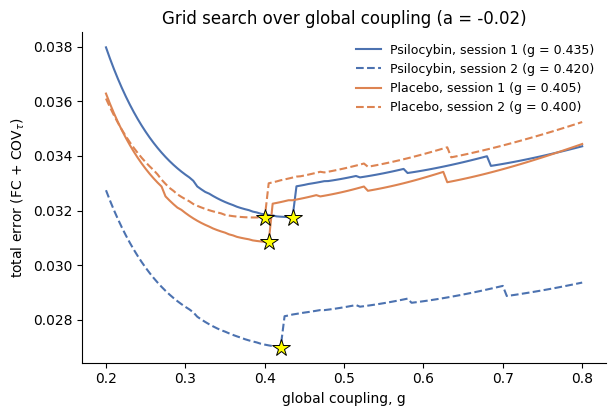

In [7]:
"""Grid search over global coupling with the bifurcation parameter fixed.
Produces the error curve over g for each group and session."""
 
VARS = ["Gvals", "Avals", "ErrorMat", "gBest", "aBest", "minVal"]
 
RUNS = [("Psilocybin", "01", "active"),
        ("Psilocybin", "02", "active"),
        ("Placebo",    "01", "placebo"),
        ("Placebo",    "02", "placebo")]
 
D = {}
for label, ses, grp in RUNS:
    fname = f"{GRID_PATH}gridGroupResults_group-{grp}_task-rest_ses-{ses}_tau-1.mat"
    D[(label, ses)] = sio.loadmat(fname, variable_names=VARS)
 
# sanity: the saved optimum should be the argmin of the error matrix
for key, d in D.items():
    G, A, E = d["Gvals"].ravel(), d["Avals"].ravel(), d["ErrorMat"]
    iG, iA = np.unravel_index(np.nanargmin(E), E.shape)
    assert np.isclose(G[iG], d["gBest"].ravel()[0]), key
    assert np.isclose(A[iA], d["aBest"].ravel()[0]), key
    assert np.isclose(E[iG, iA], d["minVal"].ravel()[0]), key
print("optimum verified against argmin(ErrorMat) in all runs")

# COL = {"01": "#4C72B0", "02": "#C44E52"}
 
# ------------------------------------------------------------------ figure
COL = {"Psilocybin": "#4C72B0", "Placebo": "#DD8452"}
LS  = {"01": "-", "02": "--"}

fig, ax = plt.subplots(figsize=(6.5, 4.5))
for (grp, ses), d in D.items():
    G  = d["Gvals"].ravel()
    E  = d["ErrorMat"].astype(float).ravel()
    gb = float(d["gBest"].ravel()[0])
    mv = float(d["minVal"].ravel()[0])

    ax.plot(G, E, color=COL[grp], ls=LS[ses], lw=1.5,
            label=f"{grp}, session {int(ses)} (g = {gb:.3f})")
    ax.plot(gb, mv, marker="*", ms=13, mfc="yellow", mec="black",
            mew=0.7, ls="none", zorder=5)
    
# ax.set_xscale("log")
ax.set_xlabel("global coupling, g")
ax.set_ylabel(r"total error (FC + COV$_\tau$)")
ax.set_title(f"Grid search over global coupling (a = {float(D[('Psilocybin','01')]['aBest'].ravel()[0]):.2f})")
ax.legend(frameon=False, fontsize=9)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(f"{SAVEFIG}grid_error_curve.png", dpi=330, bbox_inches="tight")
 

In [8]:
print('optimal g and a values for each run:')
for key in D.keys():
    d = D[key]
    print(f"{key}: g={d['gBest'].ravel()[0]:.3f}, a={d['aBest'].ravel()[0]:.3f}, error={d['minVal'].ravel()[0]:.4f}")

optimal g and a values for each run:
('Psilocybin', '01'): g=0.435, a=-0.020, error=0.0317
('Psilocybin', '02'): g=0.420, a=-0.020, error=0.0270
('Placebo', '01'): g=0.405, a=-0.020, error=0.0308
('Placebo', '02'): g=0.400, a=-0.020, error=0.0317


trajectories verified; iterations: {('Psilocybin', '01'): 2100, ('Psilocybin', '02'): 1900, ('Placebo', '01'): 2000, ('Placebo', '02'): 1900}


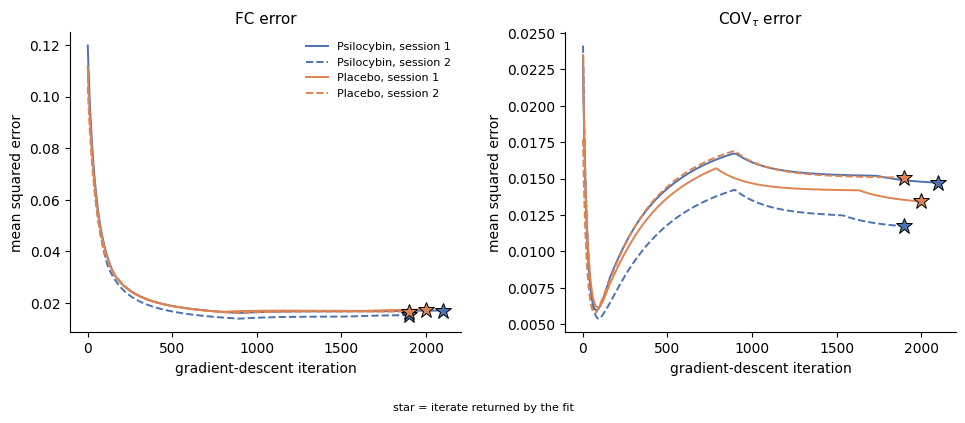

In [9]:
# ── eFigure 5: convergence at the selected solution ──────────────────────────
TRAJ = TRAJ_PATH

T = {}
for l, s, g in RUNS:
    m = sio.loadmat(f"{TRAJ}gridGroupResults_group-{g}_task-rest_ses-{s}_tau-1.mat",
                    variable_names=["errFC", "errCOVtau", "errFC_best",
                                    "errCOVtau_best", "ErrorMat", "Gvals", "iterBest"])
    T[(l, s)] = {"errFC":     m["errFC"]     if "errFC"     in m else m["errFC_best"],
                 "errCOVtau": m["errCOVtau"] if "errCOVtau" in m else m["errCOVtau_best"],
                 "ErrorMat":  m["ErrorMat"], "Gvals": m["Gvals"],
                 # iterate the fit returned: the last iterate under the stopping
                 # rule, or the saved iterBest for fits with a fixed iteration budget
                 "iterBest":  int(np.ravel(m["iterBest"])[0]) if "iterBest" in m else None}

# provenance: trajectory endpoint must match minVal from the full grid
for key in T:
    tot = T[key]["errFC"].ravel() + T[key]["errCOVtau"].ravel()
    mv = float(D[key]["minVal"].ravel()[0])
    # published stopping rule: minVal is the trajectory's endpoint;
    # fixed-budget fits that keep the best iterate: minVal is the trajectory's minimum
    assert (np.isclose(tot[-1], mv, rtol=1e-3) or np.isclose(tot.min(), mv, rtol=1e-9)), \
        f"{key}: end {tot[-1]:.5f} / min {tot.min():.5f} vs minVal {mv:.5f}"
print(f"trajectories verified; iterations: "
      f"{ {k: T[k]['errFC'].size for k in T} }")

COL = {"Psilocybin": "#4C72B0", "Placebo": "#DD8452"}
LS  = {"01": "-", "02": "--"}

fig, axes = plt.subplots(1, 2, figsize=(10, 4.2), sharex=True)
for ax, (key, lab) in zip(axes, [("errFC", "FC error"),
                                 ("errCOVtau", r"COV$_\tau$ error")]):
    for (grp, ses), d in T.items():                      # T, not D
        y = d[key].ravel()
        ax.plot(np.arange(1, y.size + 1), y, color=COL[grp], ls=LS[ses], lw=1.4,
                label=f"{grp}, session {int(ses)}")
        ib = d["iterBest"] or y.size                     # returned iterate
        ax.plot(ib, y[ib - 1], marker="*", ms=12, mfc=COL[grp], mec="black",
                mew=0.7, ls="none", zorder=5)
    # ax.set_yscale("log")
    ax.set_xlabel("gradient-descent iteration")
    ax.set_ylabel("mean squared error")
    ax.set_title(lab, fontsize=11)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False, fontsize=8)
fig.text(0.5, -0.02, "star = iterate returned by the fit", ha="center", fontsize=8)
fig.tight_layout()
fig.savefig(f"{SAVEFIG}grid_convergence.png", dpi=330, bbox_inches="tight")

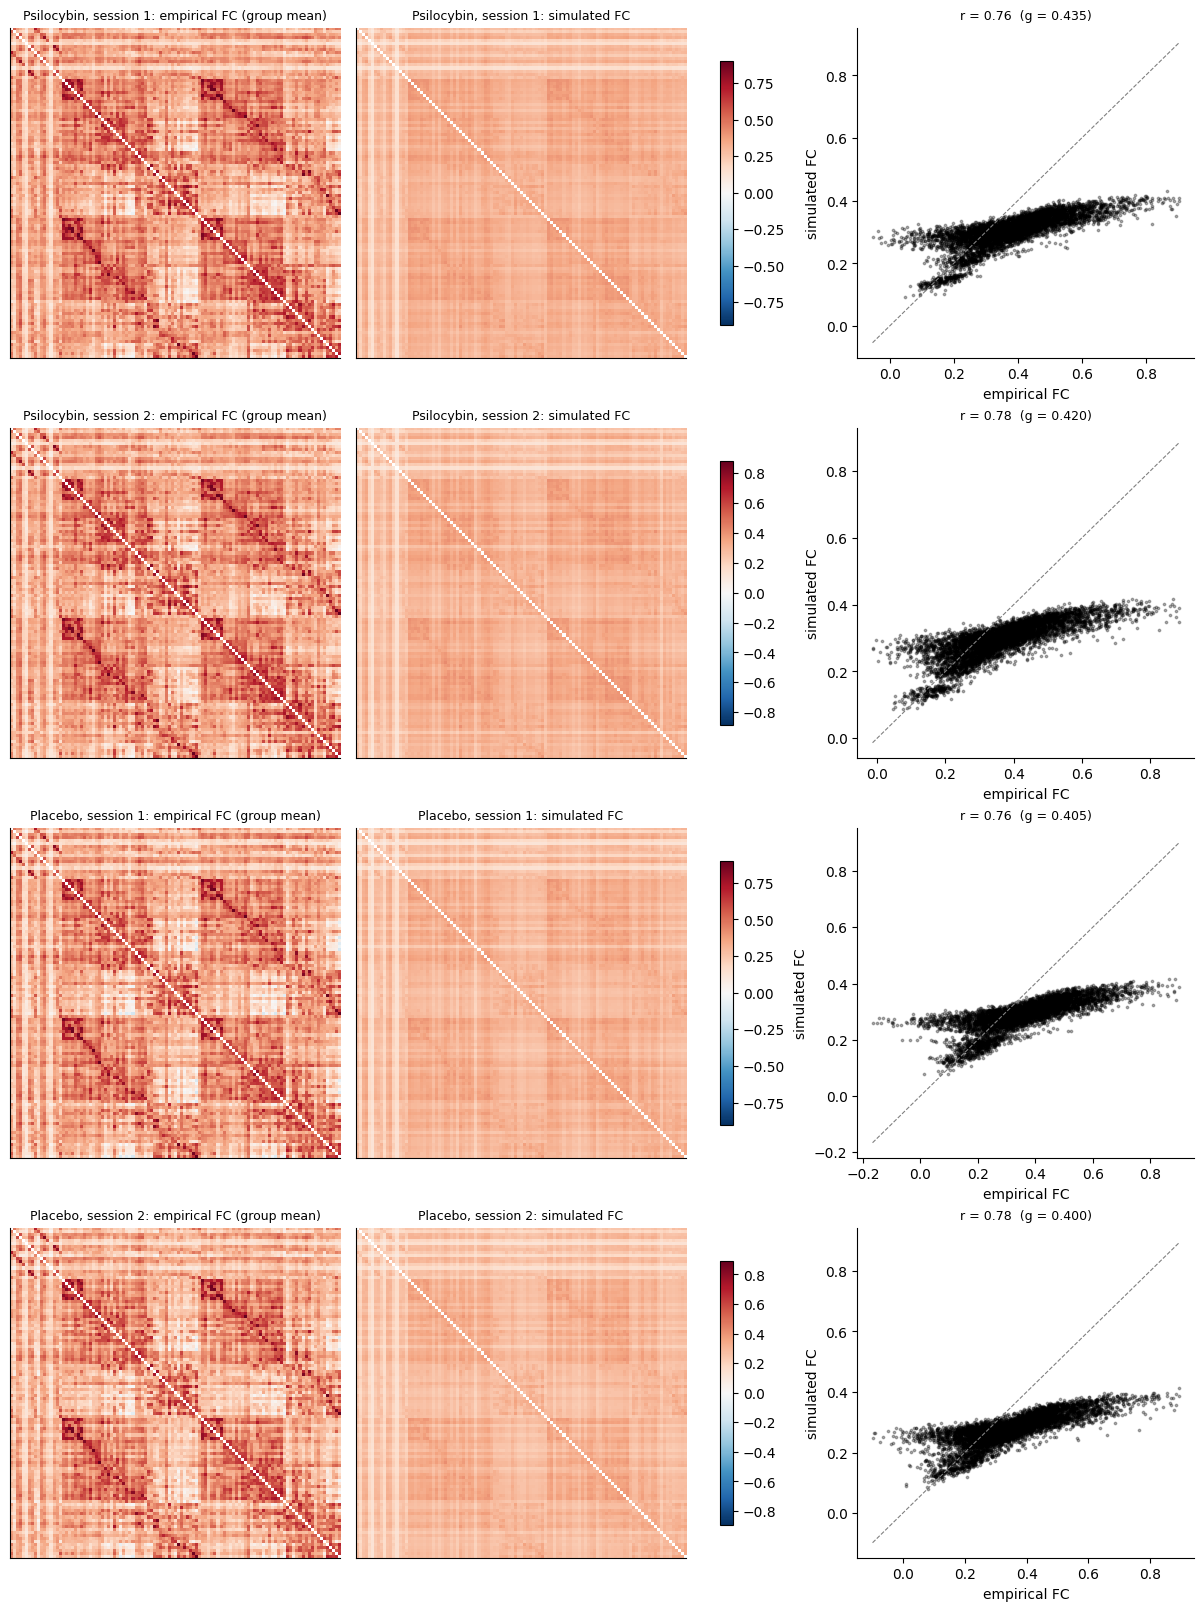

In [10]:
# ── Model fit: group-averaged empirical vs simulated FC ─────────────────────
# Needs FCemp_group / FCsim_best in the grid files; matlab/run_hopf_grid_group_psipet.m
# saves them with every fit.
V = ["FCemp_group", "FCsim_best", "gBest"]
F = {}
for label, ses, grp in RUNS:
    m = sio.loadmat(f"{GRID_PATH}gridGroupResults_group-{grp}_task-rest_ses-{ses}_tau-1.mat",
                    variable_names=V)
    if "FCsim_best" in m and "FCemp_group" in m:
        F[(label, ses)] = m

if not F:
    print("Simulated FC is not stored in these grid files -- point GRID_PATH at "
          "results produced by the repository's grid script (e.g. the replication run).")
else:
    lower = lambda X: X[np.tril_indices(X.shape[0], -1)]
    # constrained layout keeps each row's scatter title clear of the x-label above it
    fig, axes = plt.subplots(len(F), 3, figsize=(12, 4.0 * len(F)), squeeze=False,
                             constrained_layout=True)
    for row, ((grp, ses), m) in enumerate(F.items()):
        Fe, Fs = m["FCemp_group"], m["FCsim_best"]
        off = ~np.eye(len(Fe), dtype=bool)
        lim = max(np.abs(Fe[off]).max(), np.abs(Fs[off]).max())
        for k, (M, t) in enumerate(((Fe, "empirical FC (group mean)"), (Fs, "simulated FC"))):
            ax = axes[row, k]
            im = ax.imshow(np.where(off, M, np.nan), cmap="RdBu_r", vmin=-lim, vmax=lim)
            ax.set_title(f"{grp}, session {int(ses)}: {t}", fontsize=9)
            ax.set_xticks([]); ax.set_yticks([])
        fig.colorbar(im, ax=axes[row, :2].tolist(), shrink=0.8)
        x, y = lower(Fe), lower(Fs)
        ax = axes[row, 2]
        ax.scatter(x, y, s=3, alpha=0.3, color="k")
        lo, hi = min(x.min(), y.min()), max(x.max(), y.max())
        ax.plot([lo, hi], [lo, hi], color="grey", lw=0.8, ls="--")
        ax.set_xlabel("empirical FC"); ax.set_ylabel("simulated FC")
        ax.set_title(f"r = {np.corrcoef(x, y)[0, 1]:.2f}  (g = {float(np.ravel(m['gBest'])[0]):.3f})",
                     fontsize=9)
        ax.spines[["top", "right"]].set_visible(False)
    fig.savefig(f"{SAVEFIG}model_fit_FC.png", dpi=330, bbox_inches="tight")
    plt.show()


#### Individual-level model fit and convergence

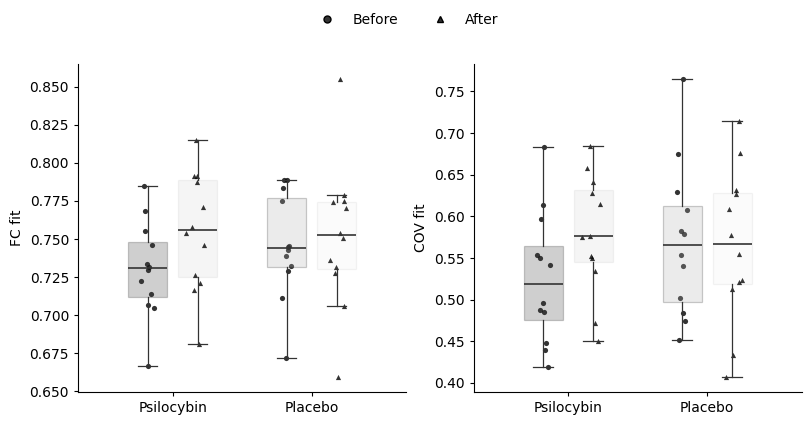

/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2714056566.py:116: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


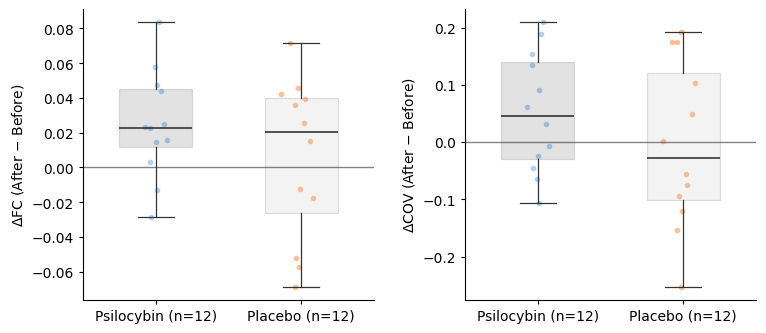

In [11]:
######################
### PLOT MODEL FIT ###
######################

fc_act_1_rest = np.array([act_1_rest['fittFC_subj'][:,0][np.where(np.array([x[0] for x in act_1_rest['subjects'][0]]) == sub)[0][0]] for sub in active_rest_subjects])
fc_act_2_rest = np.array([act_2_rest['fittFC_subj'][:,0][np.where(np.array([x[0] for x in act_2_rest['subjects'][0]]) == sub)[0][0]] for sub in active_rest_subjects])
fc_pla_1_rest = np.array([pla_1_rest['fittFC_subj'][:,0][np.where(np.array([x[0] for x in pla_1_rest['subjects'][0]]) == sub)[0][0]] for sub in placebo_rest_subjects])
fc_pla_2_rest = np.array([pla_2_rest['fittFC_subj'][:,0][np.where(np.array([x[0] for x in pla_2_rest['subjects'][0]]) == sub)[0][0]] for sub in placebo_rest_subjects])

cov_act_1_rest = np.array([act_1_rest['fittCOVtau_subj'][:,0][np.where(np.array([x[0] for x in act_1_rest['subjects'][0]]) == sub)[0][0]] for sub in active_rest_subjects])
cov_act_2_rest = np.array([act_2_rest['fittCOVtau_subj'][:,0][np.where(np.array([x[0] for x in act_2_rest['subjects'][0]]) == sub)[0][0]] for sub in active_rest_subjects])
cov_pla_1_rest = np.array([pla_1_rest['fittCOVtau_subj'][:,0][np.where(np.array([x[0] for x in pla_1_rest['subjects'][0]]) == sub)[0][0]] for sub in placebo_rest_subjects])
cov_pla_2_rest = np.array([pla_2_rest['fittCOVtau_subj'][:,0][np.where(np.array([x[0] for x in pla_2_rest['subjects'][0]]) == sub)[0][0]] for sub in placebo_rest_subjects])


# ---- Figure ----

fig, axes = plt.subplots(1, 2, figsize=(8, 4.5), constrained_layout=True)
for ax in axes:
    ax.set_box_aspect(1)

# FC
grouped_box_scatter(
    axes[0],
    fc_act_1_rest, fc_act_2_rest,
    fc_pla_1_rest, fc_pla_2_rest,
    title="", ylabel="FC fit"
)

# COV
grouped_box_scatter(
    axes[1],
    cov_act_1_rest, cov_act_2_rest,
    cov_pla_1_rest, cov_pla_2_rest,
    title="", ylabel="COV fit"
)

# One legend for session markers
legend_elems = [
    Line2D([0],[0], marker="o", color="none", markerfacecolor="0.2", markersize=5, label="Before"),
    Line2D([0],[0], marker="^", color="none", markerfacecolor="0.2", markersize=5, label="After"),
]
fig.legend(handles=legend_elems, loc="upper center", ncol=2, frameon=False)

fig.savefig(f"{SAVEFIG}/fit_comparison_panels.pdf")
fig.savefig(f"{SAVEFIG}/fit_comparison_panels.png", dpi=600)
plt.show()

# def diff_box_scatter(ax, diff_act, diff_pla, title, ylabel):
#     diff_act = v1d(diff_act)
#     diff_pla = v1d(diff_pla)

#     positions = [1, 2]
#     data = [diff_act, diff_pla]

#     bp = ax.boxplot(
#         data, positions=positions, widths=0.5,
#         patch_artist=True, showfliers=False,
#         medianprops=dict(linewidth=1.2),
#         whiskerprops=dict(linewidth=0.9),
#         capprops=dict(linewidth=0.9),
#         boxprops=dict(linewidth=0.9),
#     )

#     fills = ["0.25", "0.70"]  # Active, Placebo (grayscale)
#     for patch, fc in zip(bp["boxes"], fills):
#         patch.set_facecolor(fc)
#         patch.set_alpha(0.15)
#         patch.set_edgecolor("0.2")
#     for item in (bp["whiskers"] + bp["caps"] + bp["medians"]):
#         item.set_color("0.2")

#     rng = np.random.default_rng(0)
#     for x0, y in zip(positions, data):
#         jitter = rng.normal(0, 0.06, size=len(y))
#         ax.scatter(np.full(len(y), x0) + jitter, y, s=16, alpha=0.85, linewidths=0)

#     # mean ± 95% bootstrap CI
#     for x0, y, sd in [(1, diff_act, 1), (2, diff_pla, 2)]:
#         m, (lo, hi) = bootstrap_mean_ci(y, seed=sd)
#         ax.errorbar([x0], [m], yerr=[[m-lo], [hi-m]], fmt="o", capsize=3, linewidth=1.0)

#     ax.axhline(0, linewidth=1.0, color="0.2", alpha=0.6)

#     ax.set_title(title)
#     ax.set_xticks(positions)
#     ax.set_xticklabels([f"Psilocybin (n={len(diff_act)})", f"Placebo (n={len(diff_pla)})"])
#     ax.set_ylabel(ylabel)

#     ax.spines["top"].set_visible(False)
#     ax.spines["right"].set_visible(False)
#     ax.tick_params(direction="out", length=3, width=0.8)

# --- diffs ---
diff_fc_act      = fc_act_2_rest        - fc_act_1_rest
diff_fc_pla      = fc_pla_2_rest        - fc_pla_1_rest

diff_cov_act     = cov_act_2_rest       - cov_act_1_rest
diff_cov_pla     = cov_pla_2_rest       - cov_pla_1_rest

# -------

fig, axes = plt.subplots(1, 2, figsize=(8, 4.5), constrained_layout=True)
for ax in axes:
    ax.set_box_aspect(1)

# Row 1: ΔFC
diff_box_scatter(axes[0], diff_fc_act, diff_fc_pla,
                 title="", ylabel=r"$\Delta$FC (After − Before)")

# Row 2: ΔCOV
diff_box_scatter(axes[1], diff_cov_act, diff_cov_pla,
                 title="", ylabel=r"$\Delta$COV (After − Before)")


plt.tight_layout()
fig.savefig(f"{SAVEFIG}/delta_cov_fc_group_comparison.pdf")
fig.savefig(f"{SAVEFIG}/delta_cov_fc_group_comparison.png", dpi=600)
plt.show()


In [12]:

PVALS = []
# Psilocybin group
print("Psilocybin group (Wilcoxon):")
stat, p = print_wilcoxon("Rest FC", fc_act_1_rest, fc_act_2_rest)
PVALS.append(p)
stat, p = print_wilcoxon("Rest COV", cov_act_1_rest, cov_act_2_rest)
PVALS.append(p)

# Placebo group
print("\nPlacebo group (Wilcoxon):")
stat, p = print_wilcoxon("Rest FC", fc_pla_1_rest, fc_pla_2_rest)
PVALS.append(p)
stat, p = print_wilcoxon("Rest COV", cov_pla_1_rest, cov_pla_2_rest)
PVALS.append(p)

# multiple comparisons correction (FDR)
reject, pvals_corrected, _, _ = multipletests(PVALS, method='fdr_bh')
print("\nMultiple comparisons correction (FDR):")
for i, (p, pc, r) in enumerate(zip(PVALS, pvals_corrected, reject)):
    print(f"Test {i+1}: original p = {p:.3f}, corrected p = {pc:.3f}, reject null: {r}")


Psilocybin group (Wilcoxon):
Rest FC: W = 10.000, p = 0.021
Rest COV: W = 21.000, p = 0.176

Placebo group (Wilcoxon):
Rest FC: W = 34.000, p = 0.733
Rest COV: W = 39.000, p = 1.000

Multiple comparisons correction (FDR):
Test 1: original p = 0.021, corrected p = 0.084, reject null: False
Test 2: original p = 0.176, corrected p = 0.353, reject null: False
Test 3: original p = 0.733, corrected p = 0.978, reject null: False
Test 4: original p = 1.000, corrected p = 1.000, reject null: False


The fit improvement does not survive multiple correction. Rest FC is W = 12, p = 0.034, uncorrected, but FDR is not sig. 

Therefore: Individual model fit did not change significantly between sessions in either group after correction for multiple comparisons (all FDR-corrected P >= 0.14).

May not need to see if fit quality explain the result but we still report fit-versus-outcome correlations (see further below). 

In [13]:

# Raw per-(group, task, session) matrices, shape (n_subj, 116), subject-matched.
HA1R_raw  = _H('active',  'rest',       '01')
HA2R_raw  = _H('active',  'rest',       '02')
HP1R_raw  = _H('placebo', 'rest',       '01')
HP2R_raw  = _H('placebo', 'rest',       '02')
# HA1RV_raw = _H('active',  'restvisual', '01')
# HA2RV_raw = _H('active',  'restvisual', '02')
# HP1RV_raw = _H('placebo', 'restvisual', '01')
# HP2RV_raw = _H('placebo', 'restvisual', '02')

# Normalization mode for hierarchical levels prior to downstream analyses.
# Options:
#   'pooled_subject' : within-subject pooled z-score across the two sessions
#                      (one mu, sd per subject computed on concat(ses1, ses2)).
#   'group_session'  : z-score within each (group, session) using a single
#                      mu/sd pooled across subjects x regions of that cell.
#   'raw'            : no z-scoring; return raw hierarchical levels.
ZSCORE_MODE = 'group_session'   # 'pooled_subject' | 'group_session' | 'raw'

def group_session_zscore(X, eps=1e-12):
    """Z-score a (n_subj, n_regions) matrix using a single mu/sd pooled
    across all subjects and regions of that group x session cell."""
    X = np.asarray(X, dtype=float)
    mu = np.nanmean(X)
    sd = np.nanstd(X, ddof=0)
    if not np.isfinite(sd) or sd < eps:
        return X - mu
    return (X - mu) / sd

# Raw matrices already built above (subject-matched via canonical indexing).

if ZSCORE_MODE == 'pooled_subject':
    HA1R,  HA2R  = pooled_subject_zscore(HA1R_raw,  HA2R_raw)
    HP1R,  HP2R  = pooled_subject_zscore(HP1R_raw,  HP2R_raw)
    # HA1RV, HA2RV = pooled_subject_zscore(HA1RV_raw, HA2RV_raw)
    # HP1RV, HP2RV = pooled_subject_zscore(HP1RV_raw, HP2RV_raw)

elif ZSCORE_MODE == 'group_session':
    HA1R,  HA2R  = group_session_zscore(HA1R_raw),  group_session_zscore(HA2R_raw)
    HP1R,  HP2R  = group_session_zscore(HP1R_raw),  group_session_zscore(HP2R_raw)
    # HA1RV, HA2RV = group_session_zscore(HA1RV_raw), group_session_zscore(HA2RV_raw)
    # HP1RV, HP2RV = group_session_zscore(HP1RV_raw), group_session_zscore(HP2RV_raw)

elif ZSCORE_MODE == 'raw':
    HA1R,  HA2R  = HA1R_raw,  HA2R_raw
    HP1R,  HP2R  = HP1R_raw,  HP2R_raw
    # HA1RV, HA2RV = HA1RV_raw, HA2RV_raw
    # HP1RV, HP2RV = HP1RV_raw, HP2RV_raw

else:
    raise ValueError(
        f"Unknown ZSCORE_MODE={ZSCORE_MODE!r}. "
        "Expected 'pooled_subject', 'group_session', or 'raw'."
    )


In [14]:
grad_parc, parcellation = load_grad_parc()
gradient_full = np.concatenate((np.zeros(16)*np.nan,grad_parc))
# yeo_full = networks # see analyze_models_functions.py 
yeo_full = np.array(['Sub', 'Sub', 'Sub', 'Sub', 'Sub', 'Sub', 'Sub', 'Sub', 'Sub',
       'Sub', 'Sub', 'Sub', 'Sub', 'Sub', 'Sub', 'Sub', 'Vis', 'Vis',
       'Vis', 'Vis', 'Vis', 'Vis', 'Vis', 'Vis', 'Vis', 'SM', 'SM', 'SM',
       'SM', 'SM', 'SM', 'DA', 'DA', 'DA', 'DA', 'DA', 'DA', 'DA', 'DA',
       'SA', 'SA', 'SA', 'SA', 'SA', 'SA', 'SA', 'Limbic', 'Limbic',
       'Limbic', 'FP', 'FP', 'FP', 'FP', 'DMN', 'DMN', 'DMN', 'DMN',
       'DMN', 'DMN', 'DMN', 'DMN', 'DMN', 'DMN', 'DMN', 'DMN', 'DMN',
       'Vis', 'Vis', 'Vis', 'Vis', 'Vis', 'Vis', 'Vis', 'Vis', 'SM', 'SM',
       'SM', 'SM', 'SM', 'SM', 'SM', 'SM', 'DA', 'DA', 'DA', 'DA', 'DA',
       'DA', 'DA', 'SA', 'SA', 'SA', 'SA', 'SA', 'Limbic', 'Limbic', 'FP',
       'FP', 'FP', 'FP', 'FP', 'FP', 'FP', 'FP', 'FP', 'DMN', 'DMN',
       'DMN', 'DMN', 'DMN', 'DMN', 'DMN', 'DMN', 'DMN', 'DMN', 'DMN'],
      dtype='<U6')

pixdim[1,2,3] should be non-zero; setting 0 dims to 1


In [15]:
#########################
### Trophic coherence ###
#########################
# Get trophic coherence for subjects in each group and session, compute deltas, and plot boxplots of deltas.
DA1R = np.array([act_1_rest['trophiccoherence'][0][np.where(np.array([x for x in act_1_rest['subjects'][0]]) == sub)[0][0]] for sub in active_rest_subjects])
DA2R = np.array([act_2_rest['trophiccoherence'][0][np.where(np.array([x for x in act_2_rest['subjects'][0]]) == sub)[0][0]] for sub in active_rest_subjects])
DP1R = np.array([pla_1_rest['trophiccoherence'][0][np.where(np.array([x for x in pla_1_rest['subjects'][0]]) == sub)[0][0]] for sub in placebo_rest_subjects])
DP2R = np.array([pla_2_rest['trophiccoherence'][0][np.where(np.array([x for x in pla_2_rest['subjects'][0]]) == sub)[0][0]] for sub in placebo_rest_subjects])

print(DA1R.shape)

# Compute delta 
DiffAR = np.array(DA2R) - np.array(DA1R)
DiffPR = np.array(DP2R) - np.array(DP1R)


(12,)


In [16]:
### Statistics ###
pm = PermutationMethod(n_resamples=100_000, random_state=42)

# Within TREATMENT within group between session 
stats = sts.wilcoxon(DA2R, DA1R, alternative='two-sided',method=pm)
print(f'Psilocybin Rest: sess-02 - sess-01: \n {stats}')

stats = sts.wilcoxon(DP2R, DP1R, alternative='two-sided',method=pm)
print(f'Placebo Rest: sess-02 - sess-01: \n {stats}')

# Between TREATMENT within task between group 
stats = sts.mannwhitneyu(DiffAR, DiffPR, alternative='two-sided')
print(f'Rest Psilocybin vs Placebo: \n {stats}')


Psilocybin Rest: sess-02 - sess-01: 
 WilcoxonResult(statistic=37.0, pvalue=0.90966796875)
Placebo Rest: sess-02 - sess-01: 
 WilcoxonResult(statistic=27.0, pvalue=0.38037109375)
Rest Psilocybin vs Placebo: 
 MannwhitneyuResult(statistic=88.0, pvalue=0.3708443333042212)


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


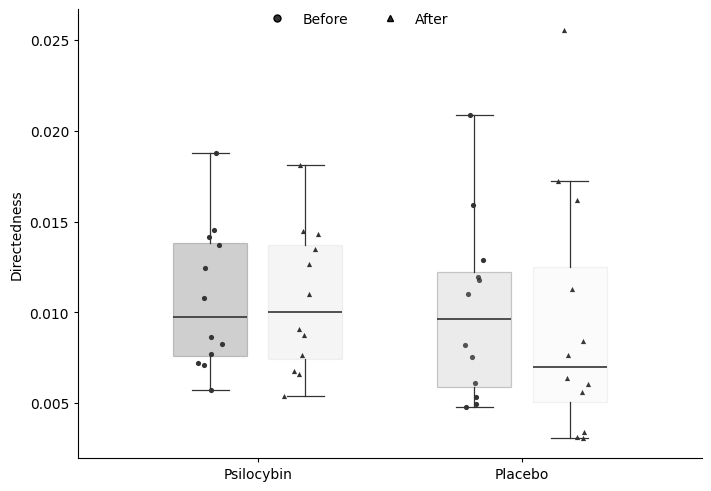

Directedness - Active group (Wilcoxon):
Rest: W = 37.000, p = 0.910

Directedness - Placebo group (Wilcoxon):
Rest: W = 27.000, p = 0.380

Multiple comparisons correction (FDR):
Test 1: original p = 0.910, corrected p = 0.910, reject null: False
Test 2: original p = 0.380, corrected p = 0.761, reject null: False


In [17]:
#########################
### PLOT DIRECTEDNESS ###
#########################
# plot directedness as we did with individual-level model fit above, both sessions and then their difference. 

fig, ax = plt.subplots(1, figsize=(7.0, 4.8), constrained_layout=True)

# Directedness
grouped_box_scatter(
    ax,
    DA1R, DA2R,
    DP1R, DP2R,
    title="", ylabel="Directedness"
)
# One legend for session markers
legend_elems = [
    Line2D([0],[0], marker="o", color="none", markerfacecolor="0.2", markersize=5, label="Before"),
    Line2D([0],[0], marker="^", color="none", markerfacecolor="0.2", markersize=5, label="After"),
]
fig.legend(handles=legend_elems, loc="upper center", ncol=2, frameon=False)

fig.savefig(f"{SAVEFIG}directedness_comparison_panels.pdf", dpi=330)
fig.savefig(f"{SAVEFIG}directedness_comparison_panels.png", dpi=330)
fig.savefig(f"{SAVEFIG}directedness_comparison_panels.eps", format="eps",dpi=330,bbox_inches='tight')
plt.show()

### Non-parametric ttest for directedness 
PVALS = []
print("Directedness - Active group (Wilcoxon):")
stat, p = print_wilcoxon("Rest", DA1R, DA2R)
PVALS.append(p)

print("\nDirectedness - Placebo group (Wilcoxon):")
stat, p = print_wilcoxon("Rest", DP1R, DP2R)
PVALS.append(p)

# Multiple comparisons 
reject, pvals_corrected, _, _ = multipletests(PVALS, method='fdr_bh')
print("\nMultiple comparisons correction (FDR):")
for i, (p, pc, r) in enumerate(zip(PVALS, pvals_corrected, reject)):
    print(f"Test {i+1}: original p = {p:.3f}, corrected p = {pc:.3f}, reject null: {r}")


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/1818178564.py:9: UserWarning: The figure layout has changed to tight
  plt.tight_layout()
The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


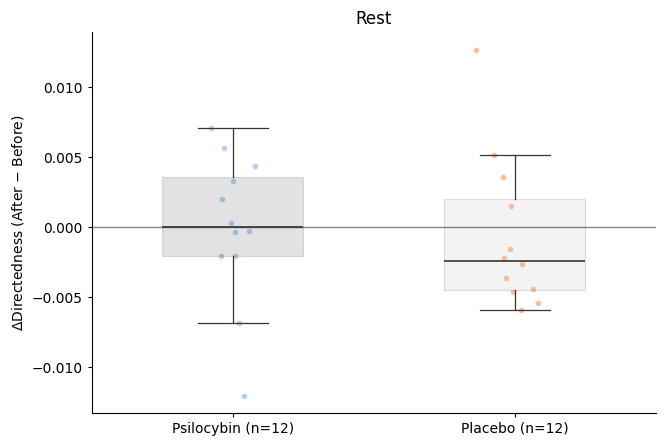

ΔDirectedness - Rest:
Rest: U = 88.000, p = 0.371


In [18]:
### Difference plot (directedness)

fig, ax = plt.subplots(1, figsize=(7.0, 4.8), constrained_layout=True)

# Row 1: ΔCOV
diff_box_scatter(ax, DiffAR, DiffPR,
                 title="Rest", ylabel=r"$\Delta$Directedness (After − Before)")

plt.tight_layout()
fig.savefig(f"{SAVEFIG}/delta_directedness_group_comparison.pdf")
fig.savefig(f"{SAVEFIG}/delta_directedness_group_comparison.png", dpi=330)
fig.savefig(f"{SAVEFIG}/delta_directedness_group_comparison.eps", format="eps", dpi=330, bbox_inches='tight')
plt.show()

### Non-parametric test for ΔDirectedness between groups (e.g., Mann-Whitney U test)
def print_mannwhitney(label, group1, group2):
    stat, p = sts.mannwhitneyu(group1, group2, alternative='two-sided')
    print(f"{label}: U = {stat:.3f}, p = {p:.3f}")

print("ΔDirectedness - Rest:")
print_mannwhitney("Rest", DiffAR, DiffPR)

# Hierarchical levels

pixdim[1,2,3] should be non-zero; setting 0 dims to 1
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/3183820653.py:16: RuntimeWarning: Mean of empty slice
  VIDX = ~np.isnan(np.nanmean(act_1_rest['hierarchicallevels_full'],0))[16:]


ActiveRest (after - before): r = -0.423, p = 0.002
PlaceboRest (after - before): r = -0.017, p = 0.918

Multiple comparisons correction (FDR):
Test 1: original p = 0.002, corrected p = 0.004, reject null: True
Test 2: original p = 0.918, corrected p = 0.918, reject null: False


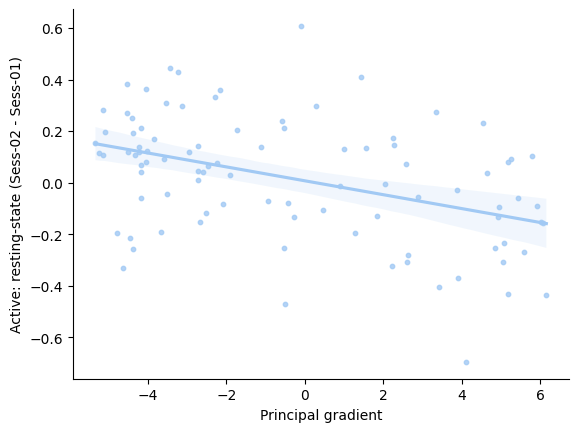

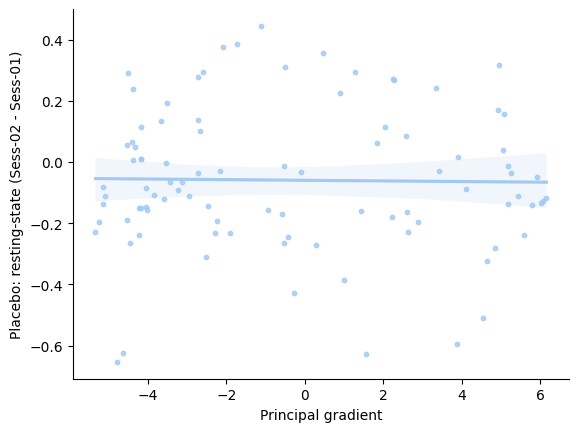

In [19]:
mapix = fetch_annotation(source='margulies2016', desc='fcgradient01', space='fsLR', den='32k')

schaefer = nntdata.fetch_schaefer2018('fslr32k')['100Parcels7Networks']
parcellation = dlabel_to_gifti(schaefer)
schaefer = parcellate.Parcellater(parcellation, 'fsLR').fit()

grad_parc = schaefer.transform(mapix, 'fsLR')



diff_active_rest = HA2R.mean(0) - HA1R.mean(0)
diff_placebo_rest = HP2R.mean(0) - HP1R.mean(0)

cmap = sns.color_palette("BrBG_r",as_cmap=True)

VIDX = ~np.isnan(np.nanmean(act_1_rest['hierarchicallevels_full'],0))[16:]

min_val = np.nanmin(((diff_active_rest)[16:][VIDX].min(), (diff_placebo_rest)[16:][VIDX].min()))
max_val = np.nanmax(((diff_active_rest)[16:][VIDX].max(), (diff_placebo_rest)[16:][VIDX].max()))
min_val = np.round(min_val,2)
max_val = np.round(max_val,2)

del VIDX 

### Resting-state Active treatment (After - Before)
plt.figure()
sns.regplot(x=grad_parc, y=(diff_active_rest)[16:], scatter_kws={'s':10})
plt.xlabel('Principal gradient')
plt.ylabel('Active: resting-state (Sess-02 - Sess-01)')

### Resting-state Placebo treatment (After - Before)
plt.figure()
sns.regplot(x=grad_parc, y=(diff_placebo_rest)[16:], scatter_kws={'s':10})
plt.xlabel('Principal gradient')
plt.ylabel('Placebo: resting-state (Sess-02 - Sess-01)')

#############################
### Spin permutation test ###
#############################

rotated = nulls.alexander_bloch(grad_parc, atlas='fsLR', density='32k',
                                n_perm=1000, seed=SEED, parcellation=parcellation)

PVALS = []

corr, pval = nnstats.compare_images(grad_parc, diff_active_rest[16:], nulls=rotated)
print(f'ActiveRest (after - before): r = {corr:.3f}, p = {pval:.3f}')
PVALS.append(pval)

corr, pval = nnstats.compare_images(grad_parc, diff_placebo_rest[16:], nulls=rotated)
print(f'PlaceboRest (after - before): r = {corr:.3f}, p = {pval:.3f}')
PVALS.append(pval)

reject, pvals_corrected, _, _ = multipletests(PVALS, method='fdr_bh')
print("\nMultiple comparisons correction (FDR):")
for i, (p, pc, r) in enumerate(zip(PVALS, pvals_corrected, reject)):
    print(f"Test {i+1}: original p = {p:.3f}, corrected p = {pc:.3f}, reject null: {r}")


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2398994434.py:5: RuntimeWarning: Mean of empty slice
  comp1 = np.nanmean(HA2R-HA1R, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2398994434.py:8: RuntimeWarning: Mean of empty slice
  comp2 = np.nanmean(HP2R-HP1R, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2398994434.py:11: RuntimeWarning: Mean of empty slice
  comp3 = np.nanmean(HA2R-HA1R, axis=0) - np.nanmean(HP2R-HP1R, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2398994434.py:15: RuntimeWarning: Mean of empty slice
  ActiveRest1  = np.nanmean(HA1R, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2398994434.py:17: RuntimeWarning: Mean of empty slice
  ActiveRest2  = np.nanmean(HA2R, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2398994434.py:19: RuntimeWarning: Mean of empty slice
  PlaceboRest1 = np.nanmean(HP1R, axis=0)
/var/folde

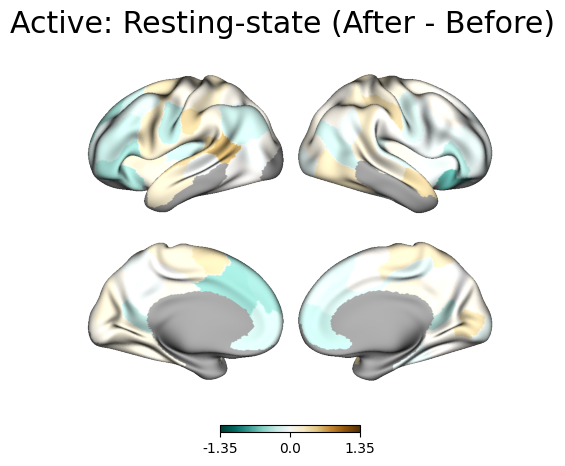

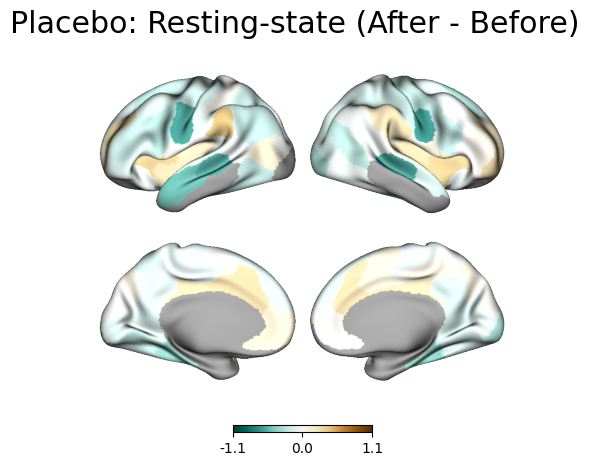

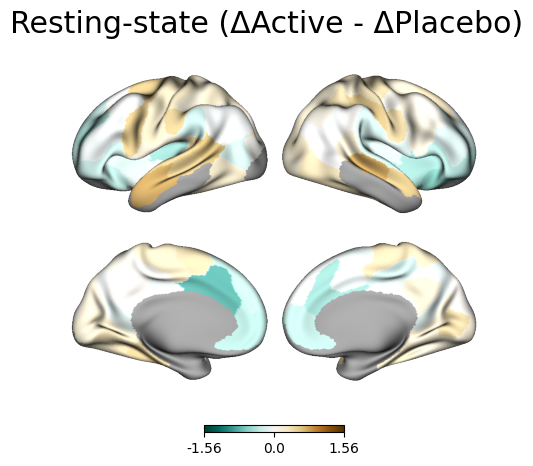

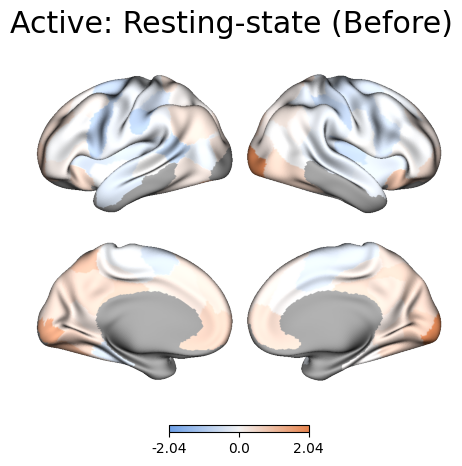

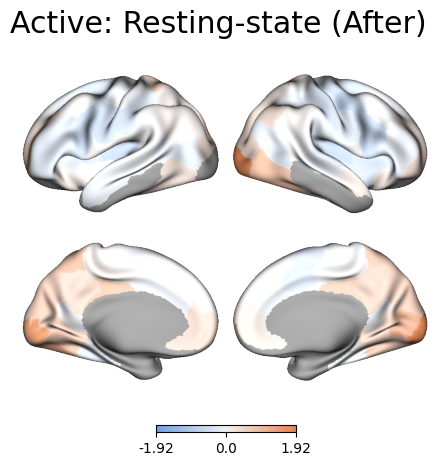

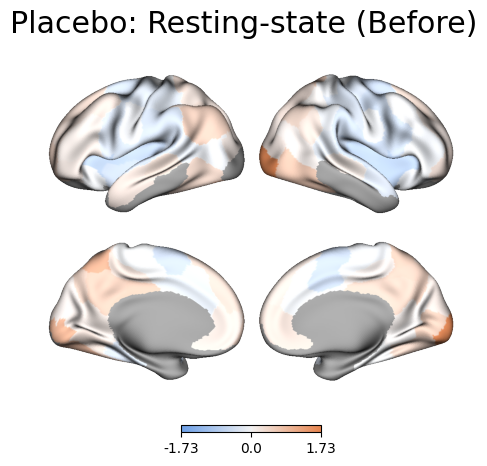

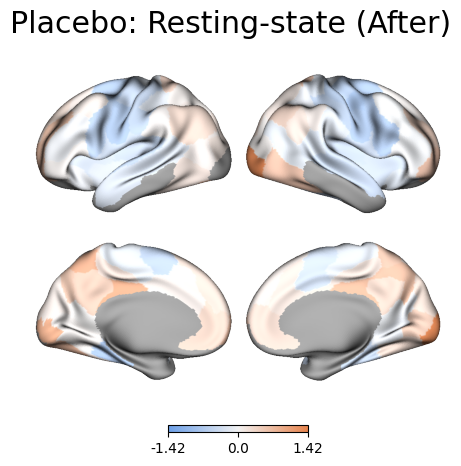

In [20]:
#####################
### SURFACE PLOTS ###
#####################

comp1 = np.nanmean(HA2R-HA1R, axis=0)
title1 = 'Active: Resting-state (After - Before)'

comp2 = np.nanmean(HP2R-HP1R, axis=0)
title2 = 'Placebo: Resting-state (After - Before)'

comp3 = np.nanmean(HA2R-HA1R, axis=0) - np.nanmean(HP2R-HP1R, axis=0)
title3 = 'Resting-state (ΔActive - ΔPlacebo)'


ActiveRest1  = np.nanmean(HA1R, axis=0)
titleA = 'Active: Resting-state (Before)'
ActiveRest2  = np.nanmean(HA2R, axis=0)
titleB = 'Active: Resting-state (After)'
PlaceboRest1 = np.nanmean(HP1R, axis=0)
titleC = 'Placebo: Resting-state (Before)'
PlaceboRest2 = np.nanmean(HP2R, axis=0)
titleD = 'Placebo: Resting-state (After)'

### Deltas 
cmap = sns.color_palette("BrBG_r",as_cmap=True)
plot_brain_surface(comp1, cmap=cmap, title=title1,diverging=True)
plt.savefig(f"{SAVEFIG}_delta-comp1.png")
plot_brain_surface(comp2, cmap=cmap, title=title2,diverging=True)
plt.savefig(f"{SAVEFIG}_delta-comp2.png")

### Deltas of Deltas
cmap = sns.color_palette("BrBG_r",as_cmap=True)
plot_brain_surface(comp3, cmap=cmap, title=title3,diverging=True)
plt.savefig(f"{SAVEFIG}_delta-delta-comp3.png")

### Hierarchical levels 
cmap = sns.diverging_palette(250, 30, l=65, center="light", as_cmap=True)
# cmap = sns.color_palette("PuBuGn", as_cmap=True) # sequential
plot_brain_surface(ActiveRest1, cmap=cmap, title=titleA,diverging=True)
plt.savefig(f"{SAVEFIG}_ActiveRest1.png")
plot_brain_surface(ActiveRest2, cmap=cmap, title=titleB,diverging=True)
plt.savefig(f"{SAVEFIG}_ActiveRest2.png")
plot_brain_surface(PlaceboRest1, cmap=cmap, title=titleC,diverging=True)
plt.savefig(f"{SAVEFIG}_PlaceboRest1.png")
plot_brain_surface(PlaceboRest2, cmap=cmap, title=titleD,diverging=True)
plt.savefig(f"{SAVEFIG}_PlaceboRest2.png")

#### plot subcortical

In [21]:
import subcortex_visualization as sv
print([x for x in dir(sv) if not x.startswith("_")])

from subcortex_visualization import utils
print([x for x in dir(utils) if not x.startswith("_")])

from subcortex_visualization.utils import get_atlas_regions
from subcortex_visualization.plotting import plot_subcortical_data


atlas = 'Melbourne_S1'
sub_labels = get_atlas_regions(atlas)
sub_labels = np.concatenate((sub_labels,sub_labels))
Hemisphere = np.concatenate((np.repeat('R',8),np.repeat('L',8)))



['plot_subcortical_data', 'plotting']
['files', 'get_atlas_regions', 'np', 'pd']


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2439427819.py:7: RuntimeWarning: Mean of empty slice
  comp1 = np.nanmean(HA2R-HA1R, axis=0)


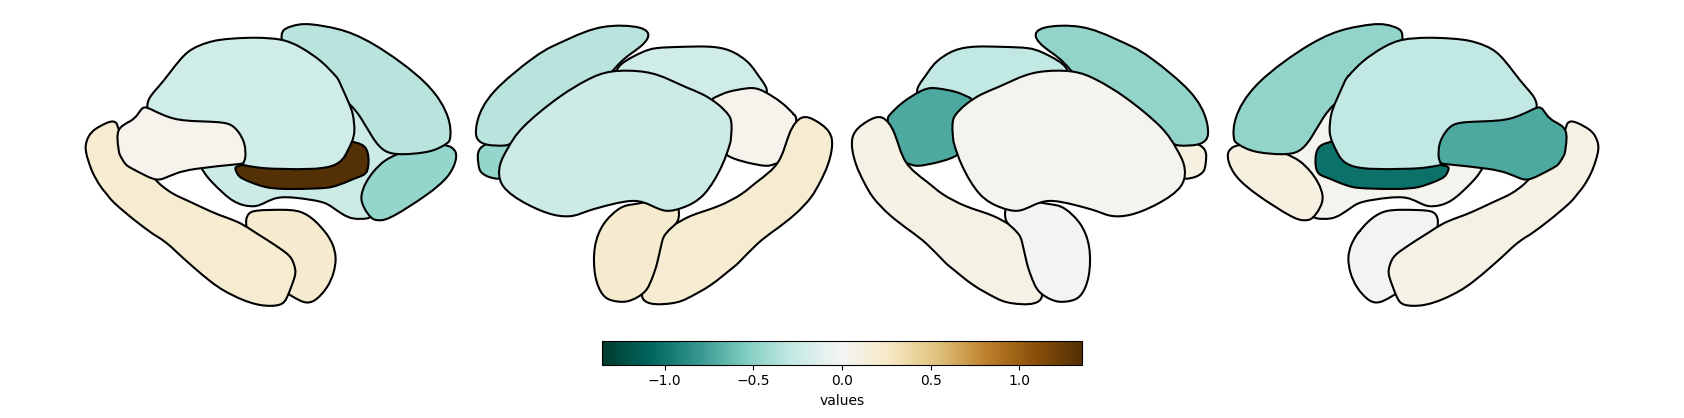

Psilocybin: After - Before


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2439427819.py:27: RuntimeWarning: Mean of empty slice
  comp2 = np.nanmean(HP2R-HP1R, axis=0)


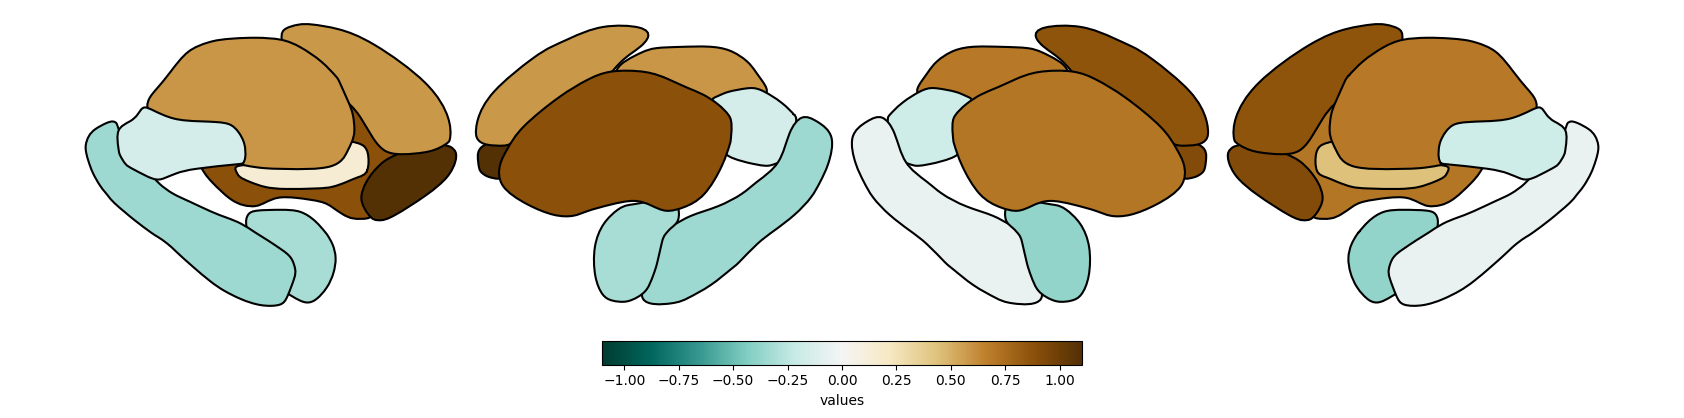

Placebo: After - Before


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2439427819.py:45: RuntimeWarning: Mean of empty slice
  compx = np.nanmean((HA2R - HA1R),axis=0) - np.nanmean((HP2R - HP1R),axis=0)


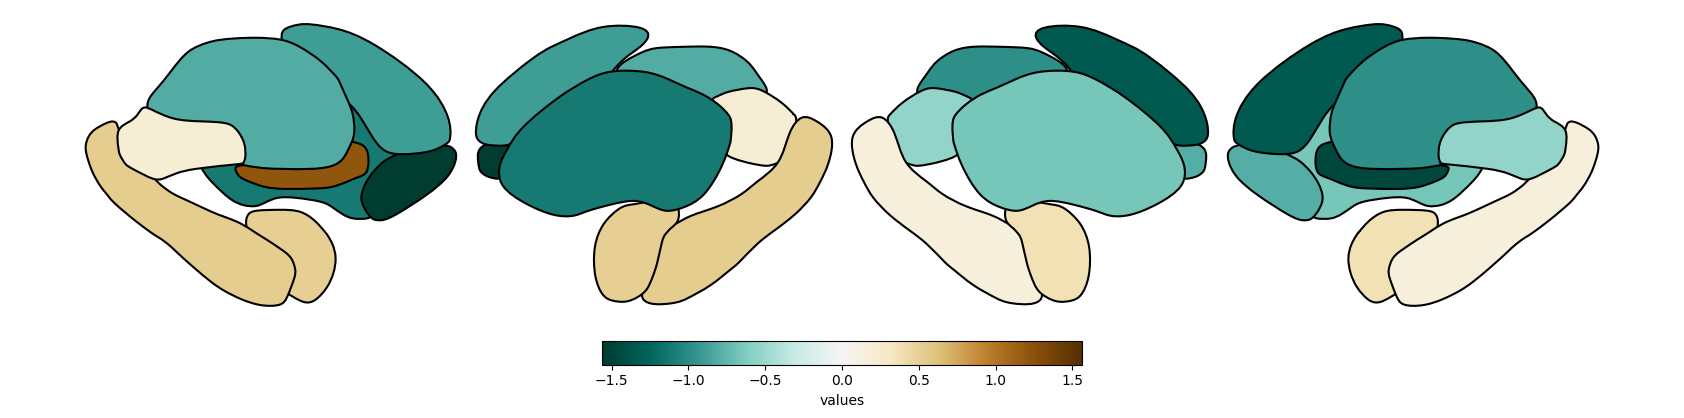

HL(ΔActive - ΔPlacebo)


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2439427819.py:67: RuntimeWarning: Mean of empty slice
  ActiveRest1  = np.nanmean(HA1R, axis=0)


Psilocybin: Before


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2439427819.py:84: RuntimeWarning: Mean of empty slice
  ActiveRest2  = np.nanmean(HA2R, axis=0)


Psilocybin: After


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2439427819.py:101: RuntimeWarning: Mean of empty slice
  PlaceboRest1 = np.nanmean(HP1R, axis=0)


Placebo: Before


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2439427819.py:118: RuntimeWarning: Mean of empty slice
  PlaceboRest2 = np.nanmean(HP2R, axis=0)


Placebo: After


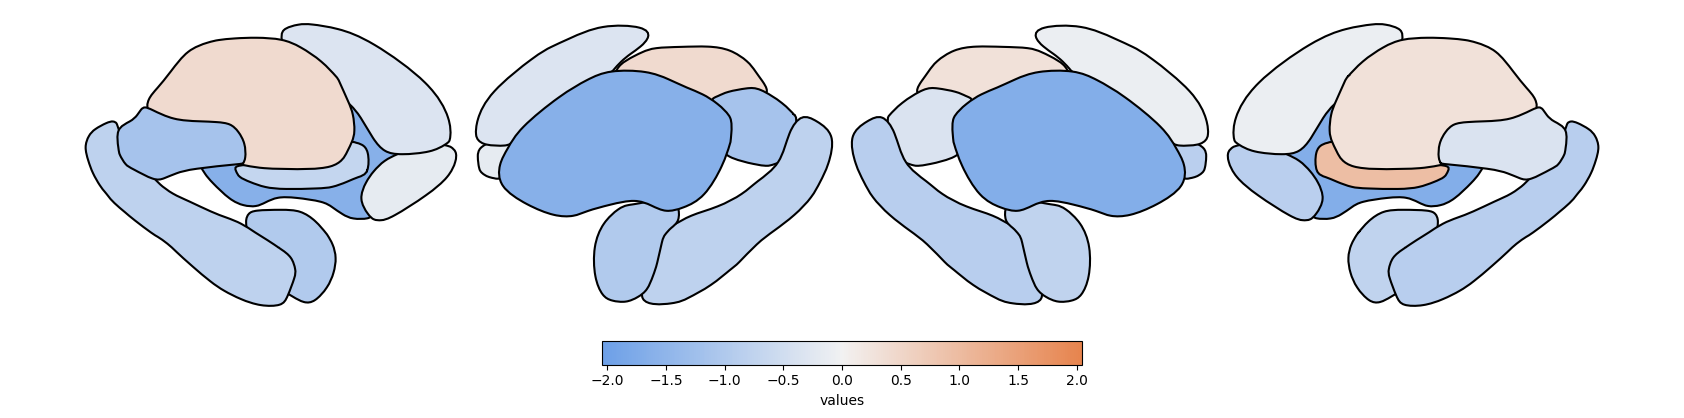

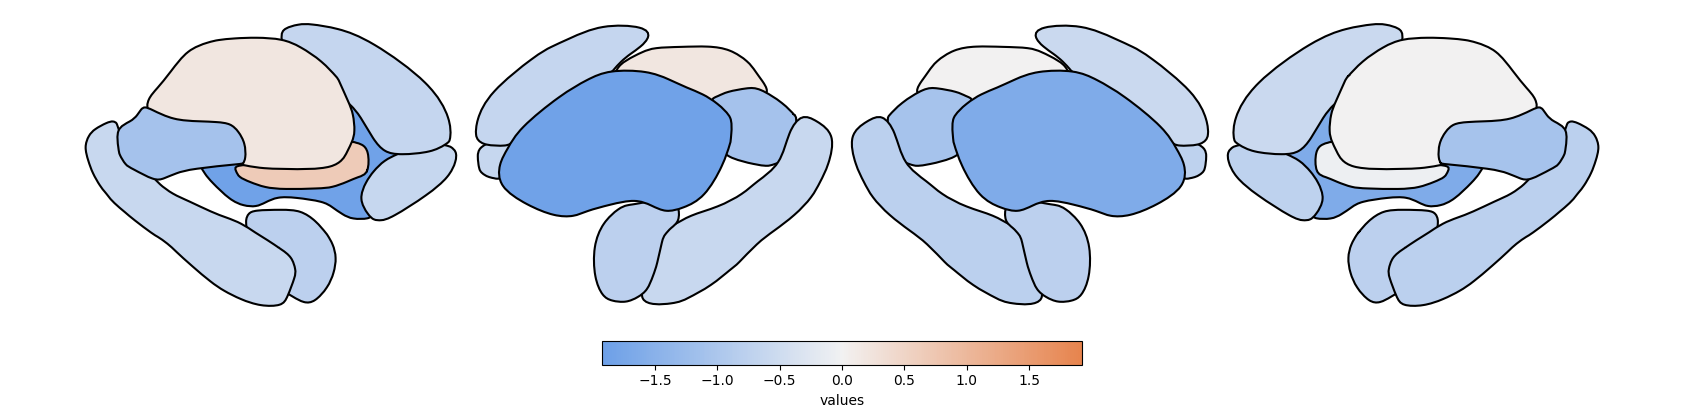

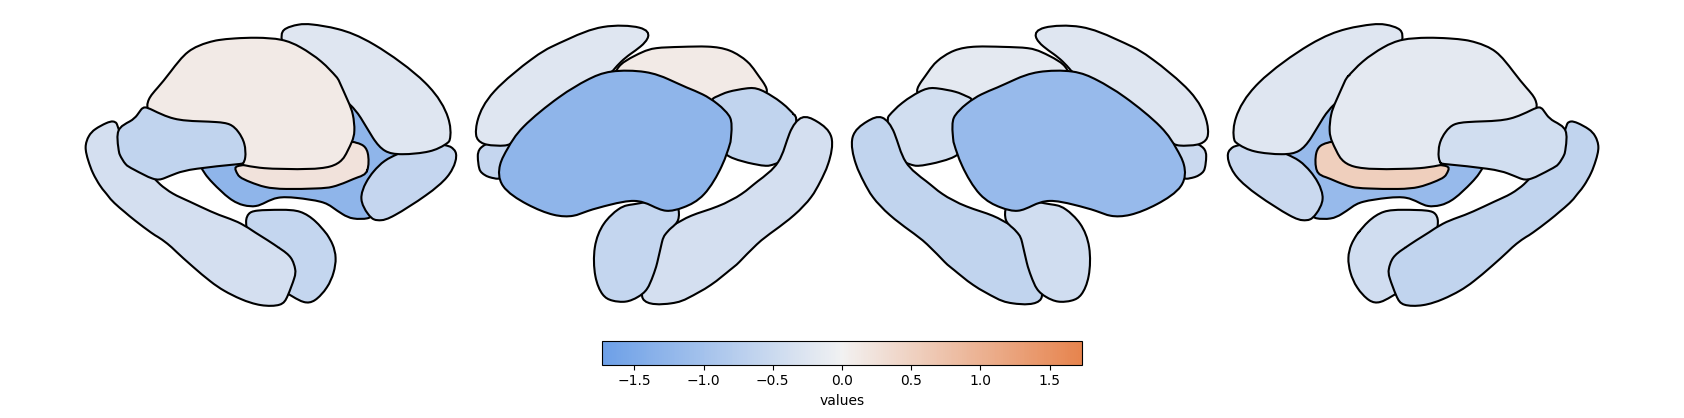

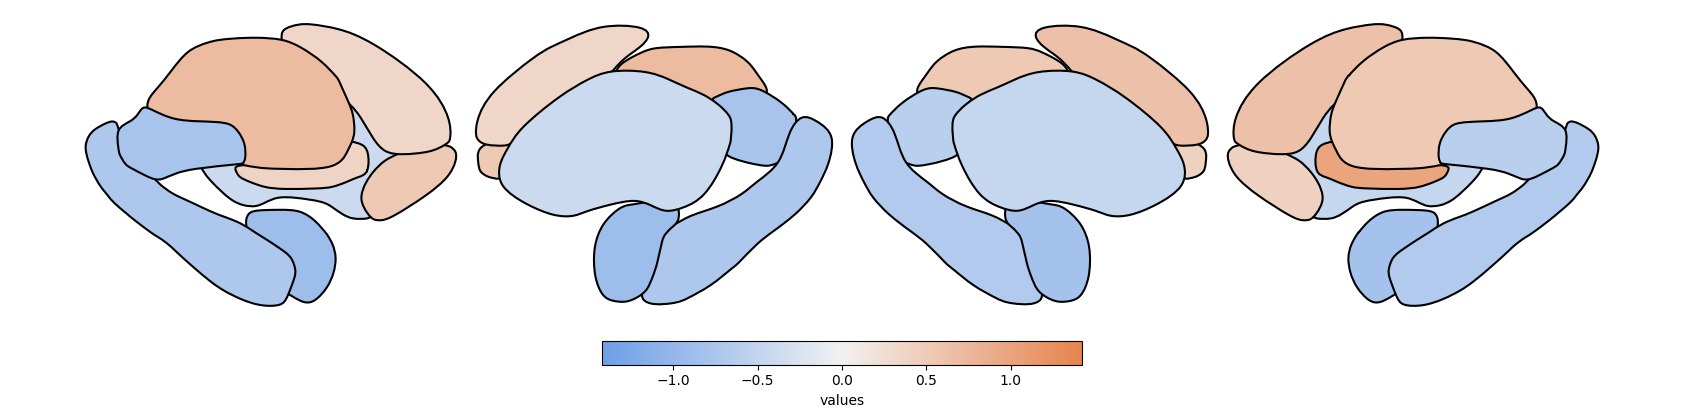

In [22]:
# my labels (obtained from https://github.com/yetianmed/subcortex) vs subcortex_vizualiser labels are flipped. need to reindex my data 
SUB_IDX = np.array([0,1,2,3,5,4,6,7,8,9,10,11,13,12,14,15])

# cmap comp1-comp4
cmap = sns.color_palette("BrBG_r",as_cmap=True)

comp1 = np.nanmean(HA2R-HA1R, axis=0)
title1 = 'Active: Resting-state (After - Before)'
v = np.round(max(np.nanmax(comp1), abs(np.nanmin(comp1))), 2)    
vmin = -v
vmax = v

df = pd.DataFrame({'value':comp1[:16][SUB_IDX], 'region': sub_labels,'Hemisphere':Hemisphere})
fig = plot_subcortical_data(subcortex_data=df, 
                        atlas=atlas, 
                        hemisphere='both',
                        show_figure=False,
                        cmap=cmap,
                        vmin=vmin,
                        vmax=vmax)
plt.savefig(SAVEFIG + title1 + '.png', bbox_inches="tight", dpi=330)
plt.show()
print('Psilocybin: After - Before')



comp2 = np.nanmean(HP2R-HP1R, axis=0)
title2 = 'Placebo: Resting-state (After - Before)'
v = np.round(max(np.nanmax(comp2), abs(np.nanmin(comp2))), 2)    
vmin = -v
vmax = v

df = pd.DataFrame({'value':comp2[:16][SUB_IDX], 'region': sub_labels,'Hemisphere':Hemisphere})
fig = plot_subcortical_data(subcortex_data=df, 
                        atlas=atlas, 
                        hemisphere='both',
                        show_figure=False,
                        cmap=cmap,
                        vmin=vmin,
                        vmax=vmax)
plt.savefig(SAVEFIG + title2 + '.png', bbox_inches="tight", dpi=330)
plt.show()
print('Placebo: After - Before')

compx = np.nanmean((HA2R - HA1R),axis=0) - np.nanmean((HP2R - HP1R),axis=0)
title1 = 'HL(ΔActive - ΔPlacebo)'
v = np.round(max(np.nanmax(compx), abs(np.nanmin(compx))), 2)    
vmin = -v
vmax = v

df = pd.DataFrame({'value':compx[:16][SUB_IDX], 'region': sub_labels,'Hemisphere':Hemisphere})
fig = plot_subcortical_data(subcortex_data=df, 
                        atlas=atlas, 
                        hemisphere='both',
                        show_figure=False,
                        cmap=cmap,
                        vmin=vmin,
                        vmax=vmax)
plt.savefig(SAVEFIG + title1 + '.png', bbox_inches="tight", dpi=330)
plt.show()
print('HL(ΔActive - ΔPlacebo)')

### Plot and save each group before and after separately
# cmap for hierarchical levels 
cmap = sns.diverging_palette(250, 30, l=65, center="light", as_cmap=True)

ActiveRest1  = np.nanmean(HA1R, axis=0)
titleA = 'Active: Resting-state (Before)'
v = np.round(max(np.nanmax(ActiveRest1), abs(np.nanmin(ActiveRest1))), 2)    
vmin = -v
vmax = v

df = pd.DataFrame({'value':ActiveRest1[:16][SUB_IDX], 'region': sub_labels,'Hemisphere':Hemisphere})
fig = plot_subcortical_data(subcortex_data=df, 
                        atlas=atlas, 
                        hemisphere='both',
                        show_figure=False,
                        cmap=cmap,
                        vmin=vmin,
                        vmax=vmax)
plt.savefig(SAVEFIG + titleA + '.png', bbox_inches="tight", dpi=330)
print('Psilocybin: Before')

ActiveRest2  = np.nanmean(HA2R, axis=0)
titleB = 'Active: Resting-state (After)'
v = np.round(max(np.nanmax(ActiveRest2), abs(np.nanmin(ActiveRest2))), 2)    
vmin = -v
vmax = v

df = pd.DataFrame({'value':ActiveRest2[:16][SUB_IDX], 'region': sub_labels,'Hemisphere':Hemisphere})
fig = plot_subcortical_data(subcortex_data=df, 
                        atlas=atlas, 
                        hemisphere='both',
                        show_figure=False,
                        cmap=cmap,
                        vmin=vmin,
                        vmax=vmax)
plt.savefig(SAVEFIG + titleB + '.png', bbox_inches="tight", dpi=330)
print('Psilocybin: After')

PlaceboRest1 = np.nanmean(HP1R, axis=0)
titleC = 'Placebo: Resting-state (Before)'
v = np.round(max(np.nanmax(PlaceboRest1), abs(np.nanmin(PlaceboRest1))), 2)    
vmin = -v
vmax = v

df = pd.DataFrame({'value':PlaceboRest1[:16][SUB_IDX], 'region': sub_labels,'Hemisphere':Hemisphere})
fig = plot_subcortical_data(subcortex_data=df, 
                        atlas=atlas, 
                        hemisphere='both',
                        show_figure=False,
                        cmap=cmap,
                        vmin=vmin,
                        vmax=vmax)
plt.savefig(SAVEFIG + titleC + '.png', bbox_inches="tight", dpi=330)
print('Placebo: Before')

PlaceboRest2 = np.nanmean(HP2R, axis=0)
titleD = 'Placebo: Resting-state (After)'
v = np.round(max(np.nanmax(PlaceboRest2), abs(np.nanmin(PlaceboRest2))), 2)    
vmin = -v
vmax = v

df = pd.DataFrame({'value':PlaceboRest2[:16][SUB_IDX], 'region': sub_labels,'Hemisphere':Hemisphere})
fig = plot_subcortical_data(subcortex_data=df, 
                        atlas=atlas, 
                        hemisphere='both',
                        show_figure=False,
                        cmap=cmap,
                        vmin=vmin,
                        vmax=vmax)
plt.savefig(SAVEFIG + titleD + '.png', bbox_inches="tight", dpi=330)
print('Placebo: After')


# Hierarchical levels vs gradient 

In [23]:

# SKIPPING THE PERM TEST FOR NOW.
from numpy.polynomial.polynomial import polyfit, polyval

def analysis1_regionwise(
    HA1, HA2,
    grad_parc=None, parcellation=None,
    n_spin=1000, n_boot=5000, seed=0
):
    rng = np.random.default_rng(seed)

    nA = HA1.shape[0]
    nP = HA2.shape[0]

    dA = HA1[:, 16:]
    dP = HA2[:, 16:]
    contrast = np.nanmean(dP, axis=0) - np.nanmean(dA, axis=0)

    # Bootstrap 95% CIs per region
    boot = np.empty((n_boot, contrast.size), dtype=float)
    for b in range(n_boot):
        boot[b] = (
            np.nanmean(dP[rng.integers(0, nP, nP)], axis=0)
            - np.nanmean(dA[rng.integers(0, nA, nA)], axis=0)
        )
    ci_lo, ci_hi = np.nanpercentile(boot, [2.5, 97.5], axis=0)

    r_obs = sts.spearmanr(contrast, grad_parc, nan_policy='omit').statistic

    # Spin test
    spin_res = None
    if grad_parc is not None and parcellation is not None:
        spin_res = run_spin_test(
            contrast, grad_parc, parcellation,
            n_spin=n_spin, seed=seed
        )

    return dict(
        contrast=contrast, ci_lo=ci_lo, ci_hi=ci_hi,
        boot=boot,
        gradient=grad_parc, r=r_obs,
        spin=spin_res
    )

def plot_analysis1(res, title=''):
    fig, ax = plt.subplots(figsize=(5, 4))

    grad = res['gradient']
    contrast = res['contrast']
    boot = res['boot']

    # Per-region error bars
    err = [contrast - res['ci_lo'], res['ci_hi'] - contrast]
    ax.errorbar(grad, contrast, yerr=err,
                fmt='o', alpha=0.6, ms=4, lw=0.7,
                ecolor='grey', elinewidth=0.4)

    # Observed OLS regression line
    mask = np.isfinite(contrast)
    coef_obs = np.polyfit(grad[mask], contrast[mask], deg=1)
    xsort = np.argsort(grad[mask])
    ax.plot(grad[mask][xsort], np.polyval(coef_obs, grad[mask][xsort]),
            color='steelblue', lw=2, zorder=5)

    # Bootstrap CI band on regression line
    fits = np.empty((boot.shape[0], mask.sum()))
    for b in range(boot.shape[0]):
        coef_b = np.polyfit(grad[mask], boot[b][mask], deg=1)
        fits[b] = np.polyval(coef_b, grad[mask][xsort])
    lo, hi = np.percentile(fits, [2.5, 97.5], axis=0)
    ax.fill_between(grad[mask][xsort], lo, hi, alpha=0.15, color='steelblue', zorder=4)

    ax.set_xlabel('Margulies FC gradient')
    ax.set_ylabel('Δ HL')

    bits = [f"ρ = {res['r']:.3f}"]
    if res.get('spin') is not None:
        bits.append(f"{_fmt_p(res['spin']['p_spin'])} (spin)")
    ax.set_title(f"{title}\n" + ",  ".join(bits))
    fig.tight_layout()
    return fig


#### First per session 

/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:16: RuntimeWarning: Mean of empty slice
  contrast = np.nanmean(dP, axis=0) - np.nanmean(dA, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:22: RuntimeWarning: Mean of empty slice
  np.nanmean(dP[rng.integers(0, nP, nP)], axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:23: RuntimeWarning: Mean of empty slice
  - np.nanmean(dA[rng.integers(0, nA, nA)], axis=0)
~/miniconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


Psilocybin: Before: r = 0.252, p_spin = 0.330


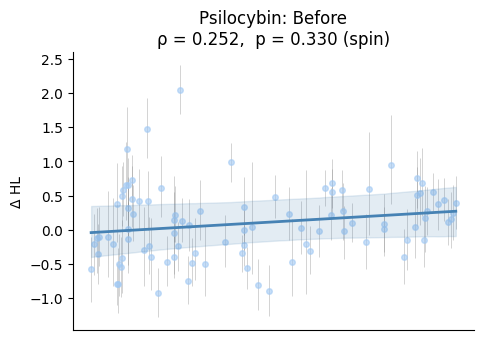

/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:16: RuntimeWarning: Mean of empty slice
  contrast = np.nanmean(dP, axis=0) - np.nanmean(dA, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:22: RuntimeWarning: Mean of empty slice
  np.nanmean(dP[rng.integers(0, nP, nP)], axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:23: RuntimeWarning: Mean of empty slice
  - np.nanmean(dA[rng.integers(0, nA, nA)], axis=0)
~/miniconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


Psilocybin: After: r = 0.099, p_spin = 0.736


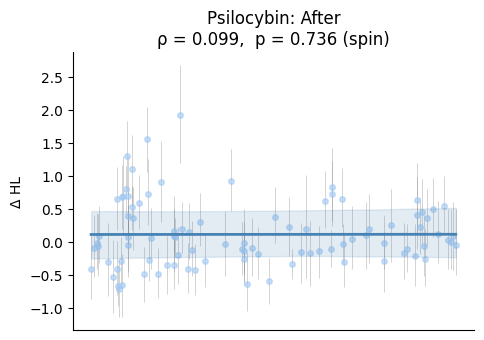

/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:16: RuntimeWarning: Mean of empty slice
  contrast = np.nanmean(dP, axis=0) - np.nanmean(dA, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:22: RuntimeWarning: Mean of empty slice
  np.nanmean(dP[rng.integers(0, nP, nP)], axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:23: RuntimeWarning: Mean of empty slice
  - np.nanmean(dA[rng.integers(0, nA, nA)], axis=0)
~/miniconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


Placebo: Before: r = 0.357, p_spin = 0.132


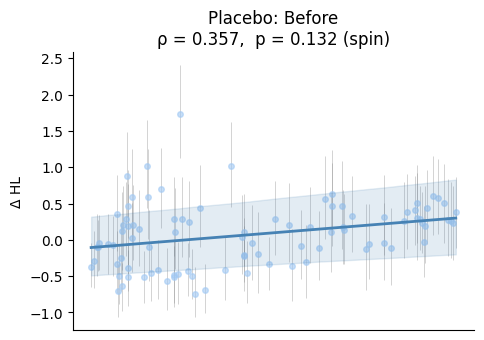

/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:16: RuntimeWarning: Mean of empty slice
  contrast = np.nanmean(dP, axis=0) - np.nanmean(dA, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:22: RuntimeWarning: Mean of empty slice
  np.nanmean(dP[rng.integers(0, nP, nP)], axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:23: RuntimeWarning: Mean of empty slice
  - np.nanmean(dA[rng.integers(0, nA, nA)], axis=0)
~/miniconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


Placebo: After: r = 0.336, p_spin = 0.136


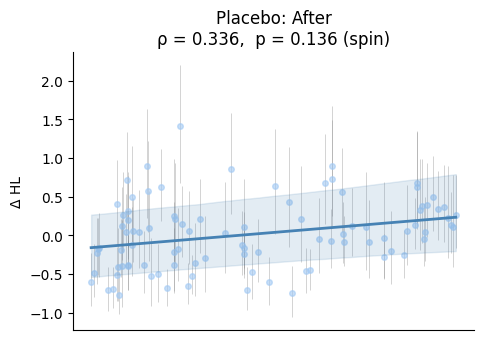


     Group Session  n     r   p_spin  p_fdr
Psilocybin  Before 12 0.252 0.329670  0.440
Psilocybin   After 12 0.099 0.736264  0.736
   Placebo  Before 12 0.357 0.131868  0.272
   Placebo   After 12 0.336 0.135864  0.272


In [24]:
# ── HL vs gradient, per group and session ────────────────────────────────────
n_boot, n_spin = 5000, 1000

CONDITIONS = [
    ("Psilocybin", "Before", HA1R),
    ("Psilocybin", "After",  HA2R),
    ("Placebo",    "Before", HP1R),
    ("Placebo",    "After",  HP2R),
]

def spin_single(H):
    """Spatial correlation of the group-mean HL map with the gradient."""
    if 'analysis1_regionwise_single' in globals():
        return analysis1_regionwise_single(H, grad_parc, parcellation,
                                           n_boot=n_boot, n_spin=n_spin, seed=SEED)
    # fallback: contrast against a zero map that preserves the NaN pattern
    return analysis1_regionwise(H * 0, H, grad_parc, parcellation,
                                n_boot=n_boot, n_spin=n_spin, seed=SEED)

rows = []
for grp, ses, H in CONDITIONS:
    res = spin_single(H)
    title = f"{grp}: {ses}"
    print(f"{title}: r = {res['r']:.3f}, p_spin = {res['spin']['p_spin']:.3f}")

    plot_analysis1(res, title=title)
    plt.xlabel(''); plt.xticks([])
    plt.savefig(f"{SAVEFIG}HL_vs_gradient_{grp}_{ses}.png",
                dpi=600, bbox_inches='tight')
    plt.show()

    rows.append({'Group': grp, 'Session': ses, 'n': H.shape[0],
                 'r': round(float(res['r']), 3),
                 'p_spin': float(res['spin']['p_spin'])})

tab_sess = pd.DataFrame(rows)
_, p_fdr, _, _ = multipletests(tab_sess['p_spin'], method='fdr_bh')
tab_sess['p_fdr'] = np.round(p_fdr, 3)
print("\n" + tab_sess.to_string(index=False))
tab_sess.to_csv(f"{SAVEFIG}eTable_HL_gradient_by_session.csv", index=False)

/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:16: RuntimeWarning: Mean of empty slice
  contrast = np.nanmean(dP, axis=0) - np.nanmean(dA, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:22: RuntimeWarning: Mean of empty slice
  np.nanmean(dP[rng.integers(0, nP, nP)], axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:23: RuntimeWarning: Mean of empty slice
  - np.nanmean(dA[rng.integers(0, nA, nA)], axis=0)
~/miniconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


Active: Resting-state (After - Before): r = -0.402, p_spin = 0.005


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:16: RuntimeWarning: Mean of empty slice
  contrast = np.nanmean(dP, axis=0) - np.nanmean(dA, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:22: RuntimeWarning: Mean of empty slice
  np.nanmean(dP[rng.integers(0, nP, nP)], axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:23: RuntimeWarning: Mean of empty slice
  - np.nanmean(dA[rng.integers(0, nA, nA)], axis=0)
~/miniconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


Placebo: Resting-state (After - Before): r = 0.012, p_spin = 0.946

Multiple comparisons correction (FDR):
Test 1: original p = 0.005, corrected p = 0.010, reject null: True
Test 2: original p = 0.946, corrected p = 0.946, reject null: False


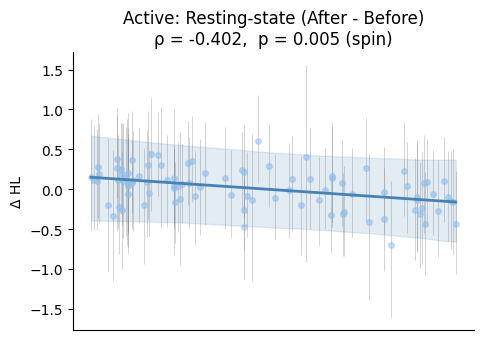

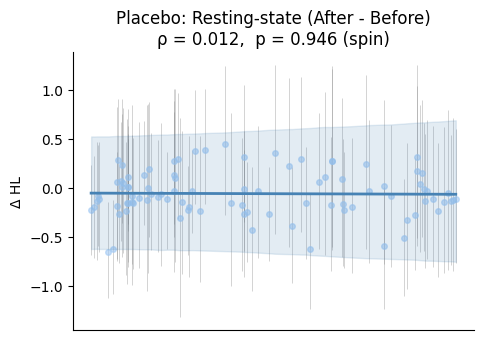

In [25]:
n_boot = 5000
n_spin = 1000

PVALS_SPIN = []
res = analysis1_regionwise(HA1R, HA2R, grad_parc, parcellation, n_boot=n_boot, n_spin=n_spin, seed=SEED)
title1 = 'Active: Resting-state (After - Before)'
print(f"{title1}: r = {res['r']:.3f}, p_spin = {res['spin']['p_spin']:.3f}")
plot_analysis1(res,title=title1)
plt.xlabel('')
plt.xticks([])
plt.savefig(f"{SAVEFIG}_CONTRAST_VS_MARGULIES_ActiveRest.png", dpi=600)

PVALS_SPIN.append(res['spin']['p_spin'] if res.get('spin') is not None else np.nan)

res = analysis1_regionwise(HP1R, HP2R, grad_parc, parcellation, n_boot=n_boot, n_spin=n_spin, seed=SEED)
title2 = 'Placebo: Resting-state (After - Before)'
print(f"{title2}: r = {res['r']:.3f}, p_spin = {res['spin']['p_spin']:.3f}")
plot_analysis1(res,title=title2)
plt.xlabel('')
plt.xticks([])  
plt.savefig(f"{SAVEFIG}_CONTRAST_VS_MARGULIES_PlaceboRest.png", dpi=600)

PVALS_SPIN.append(res['spin']['p_spin'] if res.get('spin') is not None else np.nan)

reject, pvals_corrected, _, _ = multipletests(PVALS_SPIN, method='fdr_bh')
print("\nMultiple comparisons correction (FDR):")
for i, (p, pc, r) in enumerate(zip(PVALS_SPIN, pvals_corrected, reject)):
    print(f"Test {i+1}: original p = {p:.3f}, corrected p = {pc:.3f}, reject null: {r}")


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:16: RuntimeWarning: Mean of empty slice
  contrast = np.nanmean(dP, axis=0) - np.nanmean(dA, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:22: RuntimeWarning: Mean of empty slice
  np.nanmean(dP[rng.integers(0, nP, nP)], axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:23: RuntimeWarning: Mean of empty slice
  - np.nanmean(dA[rng.integers(0, nA, nA)], axis=0)
~/miniconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


HL(ΔActive - ΔPlacebo): r = -0.344, p_spin = 0.060


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/1431703281.py:17: RuntimeWarning: Mean of empty slice
  compx = np.nanmean((HA2R - HA1R),axis=0) - np.nanmean((HP2R - HP1R),axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/2402993319.py:66: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


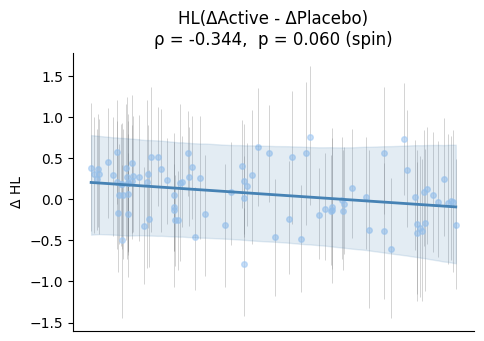

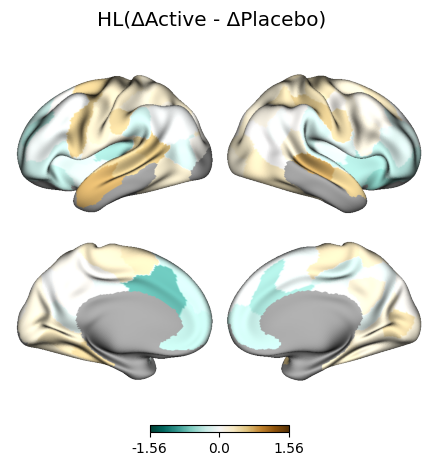

In [26]:
##################################
### For HL(ΔActive - ΔPlacebo) ###
##################################

n_boot = 5000
n_spin = 1000

res = analysis1_regionwise((HP2R - HP1R), (HA2R - HA1R) , grad_parc, parcellation, n_boot=n_boot, n_spin=n_spin, seed=SEED)
title1 = 'HL(ΔActive - ΔPlacebo)'
print(f"{title1}: r = {res['r']:.3f}, p_spin = {res['spin']['p_spin']:.3f}")
plot_analysis1(res,title=title1)
plt.xlabel('')
plt.xticks([])
plt.savefig(f"{SAVEFIG}_HL(ΔActive - ΔPlacebo)_VS_MARGULIES.png", dpi=600)

cmap = sns.color_palette("BrBG_r",as_cmap=True)
compx = np.nanmean((HA2R - HA1R),axis=0) - np.nanmean((HP2R - HP1R),axis=0)
plot_brain_surface(compx, cmap=cmap, title=title1,diverging=True)
plt.savefig(f"{SAVEFIG}_HL(ΔActive - ΔPlacebo).png")


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:16: RuntimeWarning: Mean of empty slice
  contrast = np.nanmean(dP, axis=0) - np.nanmean(dA, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:22: RuntimeWarning: Mean of empty slice
  np.nanmean(dP[rng.integers(0, nP, nP)], axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:23: RuntimeWarning: Mean of empty slice
  - np.nanmean(dA[rng.integers(0, nA, nA)], axis=0)
~/miniconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


Pooled session 1 (n = 24): r = 0.311, p_spin = 0.204


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:16: RuntimeWarning: Mean of empty slice
  contrast = np.nanmean(dP, axis=0) - np.nanmean(dA, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:22: RuntimeWarning: Mean of empty slice
  np.nanmean(dP[rng.integers(0, nP, nP)], axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:23: RuntimeWarning: Mean of empty slice
  - np.nanmean(dA[rng.integers(0, nA, nA)], axis=0)
~/miniconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,


  sensitivity (per-group z, then pooled): r = 0.302, p_spin = 0.226


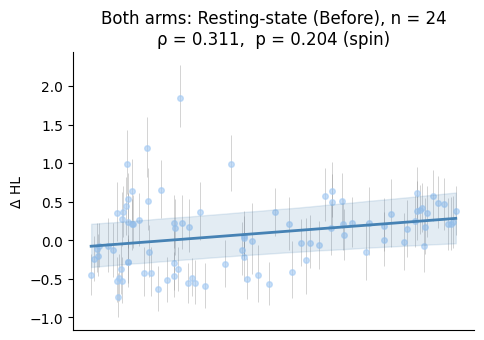

/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:16: RuntimeWarning: Mean of empty slice
  contrast = np.nanmean(dP, axis=0) - np.nanmean(dA, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:22: RuntimeWarning: Mean of empty slice
  np.nanmean(dP[rng.integers(0, nP, nP)], axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:23: RuntimeWarning: Mean of empty slice
  - np.nanmean(dA[rng.integers(0, nA, nA)], axis=0)
~/miniconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:16: RuntimeWarning: Mean of empty slice
  contrast = np.nanmean(dP, axis=0) - np.nanmean(dA, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:22: RuntimeWarning: Mean of empty slice
  np.nanmean(dP[rng.integers(0, nP,


FDR (Benjamini-Hochberg) across the 7-test regional family:
                      Test      r   p_spin  p_fdr
        Psilocybin: Before  0.252 0.329670  0.462
         Psilocybin: After  0.099 0.736264  0.859
           Placebo: Before  0.357 0.131868  0.238
            Placebo: After  0.336 0.135864  0.238
Psilocybin: After - Before -0.402 0.004995  0.035
   Placebo: After - Before  0.012 0.946054  0.946
dHL (Psilocybin - Placebo) -0.344 0.059940  0.210


In [27]:
# ── Pooled session-1 HL vs gradient, with FDR across the full regional family ─
# Insert as a new cell directly AFTER cell 33 ("For HL(ΔActive - ΔPlacebo)")
# and BEFORE the markdown "# Individual rho(deltaHL, FC gradient)".
#
# Self-contained: needs only HA1R/HA2R/HP1R/HP2R (+ the *_raw versions),
# grad_parc, parcellation, analysis1_regionwise, plot_analysis1,
# group_session_zscore, SAVEFIG, SEED. Every test in the family is recomputed
# here with the same seed, so the first seven rows must reproduce cells 31-33
# exactly (that is a built-in check).
#
# Family (8 spin tests, Spearman vs the principal FC gradient, two-sided):
#   4  group x session maps
#   2  after - before within each group
#   1  between-group contrast of dHL (psilocybin - placebo)
#   1  pooled session-1 map, both arms (n = 24)            <- new

n_spin = 1000

def _spin_map(H, n_boot=200):
    """Spin test of the group-mean map of H (bootstrap only needed for plots)."""
    return analysis1_regionwise(H * 0, H, grad_parc, parcellation,
                                n_boot=n_boot, n_spin=n_spin, seed=SEED)

def _spin_contrast(H1, H2, n_boot=200):
    """Spin test of mean(H2) - mean(H1)."""
    return analysis1_regionwise(H1, H2, grad_parc, parcellation,
                                n_boot=n_boot, n_spin=n_spin, seed=SEED)

# --- pooled session 1 -------------------------------------------------------
# Primary: standardize the pooled cell exactly as every other cell is
# standardized (one mu/sd across subjects x regions), then take the mean map.
H1_pool = group_session_zscore(np.vstack([HA1R_raw, HP1R_raw]))
res_pool = _spin_map(H1_pool, n_boot=5000)
print(f"Pooled session 1 (n = {H1_pool.shape[0]}): "
      f"r = {res_pool['r']:.3f}, p_spin = {res_pool['spin']['p_spin']:.3f}")

# Sensitivity: pool the already per-group-standardized maps instead
# (equal weighting of the two arms regardless of their raw spread).
res_pool_z = _spin_map(np.vstack([HA1R, HP1R]))
print(f"  sensitivity (per-group z, then pooled): "
      f"r = {res_pool_z['r']:.3f}, p_spin = {res_pool_z['spin']['p_spin']:.3f}")

plot_analysis1(res_pool, title='Both arms: Resting-state (Before), n = 24')
plt.xlabel(''); plt.xticks([])
plt.savefig(f"{SAVEFIG}HL_vs_gradient_Pooled_Before.png", dpi=600, bbox_inches='tight')
plt.show()

# --- the seven-test regional family ------------------------------------------
# The pooled session-1 test above is reported separately and is NOT in this family.
tests = [
    ('Psilocybin: Before',            _spin_map(HA1R)),
    ('Psilocybin: After',             _spin_map(HA2R)),
    ('Placebo: Before',               _spin_map(HP1R)),
    ('Placebo: After',                _spin_map(HP2R)),
    ('Psilocybin: After - Before',    _spin_contrast(HA1R, HA2R)),
    ('Placebo: After - Before',       _spin_contrast(HP1R, HP2R)),
    ('dHL (Psilocybin - Placebo)',    _spin_contrast(HP2R - HP1R, HA2R - HA1R)),
]

tab_fam = pd.DataFrame([{'Test': name,
                         'r': round(float(r['r']), 3),
                         'p_spin': float(r['spin']['p_spin'])}
                        for name, r in tests])
assert len(tab_fam) == 7

_, p_fdr, _, _ = multipletests(tab_fam['p_spin'], method='fdr_bh')
tab_fam['p_fdr'] = np.round(p_fdr, 3)

print("\nFDR (Benjamini-Hochberg) across the 7-test regional family:")
print(tab_fam.to_string(index=False))
tab_fam.to_csv(f"{SAVEFIG}eTable_HL_gradient_family7.csv", index=False)

# Individual rho(deltaHL, FC gradient) 


────────────────────────────────────────────────────────────
  rest | Analysis — per-subject ρ(ΔHL, FC gradient)
────────────────────────────────────────────────────────────
    Psilocybin  mean ρ = -0.102 ± 0.452 (n = 12)
    Placebo     mean ρ = -0.006 ± 0.403 (n = 12)
    Mann–Whitney U = 59.0,  p = 0.470


The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


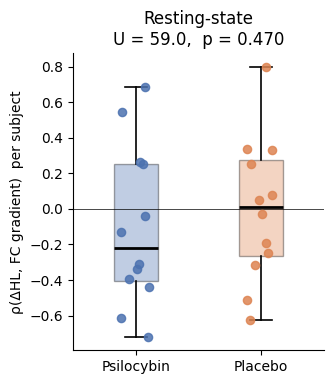

In [28]:
# participant-level correlation between hierarchical level change and FC gradient 
rho_analysis = analysis_subject_corr(HA1R, HA2R, HP1R, HP2R, gradient_full)
rho_analysis

def print_rho_stats(r, tag='Resting-state'):
    print(f"\n{'─'*60}\n  {tag} — per-subject ρ(ΔHL, FC gradient)\n{'─'*60}")
    for lab, k in [('Psilocybin', 'rhoA'), ('Placebo', 'rhoP')]:
        v = np.asarray(r[k], float)
        print(f"    {lab:<11s} mean ρ = {np.nanmean(v):+.3f} ± {np.nanstd(v, ddof=1):.3f} "
              f"(n = {np.isfinite(v).sum()})")
    print(f"    Mann–Whitney U = {r['U']:.1f},  {_fmt_p(r['p'])}")

print_rho_stats(rho_analysis, tag=f"{'rest'} | Analysis")

_ = plot_rho_analysis(rho_analysis, title='Resting-state')


# Brain-Behaviour

In [29]:
filepath1 = PET_TO_MR_XLSX
madrs_raw = pd.read_excel(filepath1)
columns = ['MRI_subject','Treatment','Acronym','Column1']

madrs_raw = madrs_raw[columns].iloc[:35]

filepath2 = MADRS_XLSX
madrs_treatment = pd.read_excel(filepath2)

dff = madrs_raw.merge(madrs_treatment, left_on='Acronym', right_on='akronym', how='inner')
# Index(['MRI_subject', 'Treatment', 'Acronym', 'Column1', 'akronym',
#     'treatment', 'ID', 'AssessorId', 'MADRSdate', 'MADRS1', 'MADRS2',
#     'MADRS3', 'MADRS4', 'MADRS5', 'MADRS6', 'MADRS7', 'MADRS8', 'MADRS9',
#     'MADRS10', 'MADRS_sum', 'TimePoint'],
#     dtype='object')

###


In [30]:

# ── 1. LOAD & FILTER ─────────────────────────────────────────────────────────
subjects = canonical_by_task.copy()

included_subjects = np.concatenate(list(subjects.values()))
print(f"Total included subjects: {len(included_subjects)}")

# Optional: build a group mapping from the dict (as a cross-check against Treatment column)
group_map = {}
for (treatment, condition), subs in subjects.items():
    for s in subs:
        group_map[s] = treatment

group_df = pd.DataFrame(list(group_map.items()), columns=['MRI_subject', 'group_from_dict'])


dff = dff[dff['MRI_subject'].isin(included_subjects)].copy()


# ── FILTER: included subjects + timepoints ────────────────────────────────────
dff = dff[
    (dff['MRI_subject'].isin(included_subjects)) &
    (dff['TimePoint'].isin(['Dag 0', 'Dag 8']))
].copy()

print(f"Subjects: {dff['MRI_subject'].nunique()}")
print(f"Timepoints:\n{dff['TimePoint'].value_counts()}")


# Check coverage
found = dff['MRI_subject'].unique()
missing = set(included_subjects) - set(found)
print(f"Matched in MADRS: {len(found)} / {len(included_subjects)}")
if missing:
    print(f"NOT found in MADRS data: {missing}")

# ── CROSS-CHECK: does Treatment column agree with dict keys? ─────────────────
check = dff[['MRI_subject', 'Treatment']].drop_duplicates().merge(group_df, on='MRI_subject', how='left')
mismatch = check[check['Treatment'].str.lower() != check['group_from_dict'].str.lower()]
if len(mismatch) > 0:
    print(f"\nWARNING: {len(mismatch)} subjects where Treatment != dict group:")
    print(mismatch)
else:
    print("Treatment column matches dict grouping — all good.")

print(f"Subjects after filtering: {dff['MRI_subject'].nunique()}")
print(f"Treatment groups:\n{dff.groupby('TimePoint')['Treatment'].value_counts()}")


# ── 2. MADRS SCORING ─────────────────────────────────────────────────────────
# Convention: MADRS total = sum of items 1–10 (each scored 0–6, range 0–60)
# Severity: 0–6 normal, 7–19 mild, 20–34 moderate, 35–60 severe

madrs_items = [f'MADRS{i}' for i in range(1, 11)]

# Verify or recompute the sum (don't trust pre-computed blindly)
dff['MADRS_sum_check'] = dff[madrs_items].sum(axis=1)
mismatch = dff[dff['MADRS_sum'] != dff['MADRS_sum_check']]
if len(mismatch) > 0:
    print(f"WARNING: {len(mismatch)} rows where MADRS_sum != recomputed sum")
    print(mismatch[['MRI_subject', 'TimePoint', 'MADRS_sum', 'MADRS_sum_check']])
else:
    print("MADRS_sum verified — matches item sum.")

# ── 3. PIVOT: ONE ROW PER SUBJECT ────────────────────────────────────────────
madrs_wide = dff.pivot_table(
    index=['MRI_subject', 'Treatment'],
    columns='TimePoint',
    values='MADRS_sum',
    aggfunc='first'
).reset_index()

madrs_wide.columns.name = None
madrs_wide = madrs_wide.rename(columns={'Dag 0': 'MADRS_d0', 'Dag 8': 'MADRS_d8'})
madrs_wide['Treatment'] = madrs_wide['Treatment'].map({'Active': 'Psilocybin', 'Placebo': 'Placebo'})

GROUP_ORDER = ["Psilocybin", "Placebo"]
madrs_wide["Treatment"] = pd.Categorical(madrs_wide["Treatment"],
                                         categories=GROUP_ORDER, ordered=True)

print(f"Subjects in madrs_wide: {madrs_wide['MRI_subject'].nunique()}")
print(f"Per group:\n{madrs_wide['Treatment'].value_counts()}")

# Change scores
madrs_wide['MADRS_change']   = madrs_wide['MADRS_d8'] - madrs_wide['MADRS_d0'] # absolute change (post - pre)
madrs_wide['MADRS_pct_change'] = (madrs_wide['MADRS_change'] / madrs_wide['MADRS_d0']) * 100 # percent change relative to baseline

# Response (≥50% reduction) and remission (≤10) — standard MADRS conventions
madrs_wide['MADRS_responder'] = madrs_wide['MADRS_pct_change'] <= -50
madrs_wide['MADRS_remission'] = madrs_wide['MADRS_d8'] <= 10

print(f"\nSubjects with both timepoints: {madrs_wide.dropna(subset=['MADRS_d0','MADRS_d8']).shape[0]}")

# ── 4. DESCRIPTIVES ──────────────────────────────────────────────────────────
print("\n=== MADRS DESCRIPTIVES — OVERALL ===")
for col in ['MADRS_d0', 'MADRS_d8', 'MADRS_change', 'MADRS_pct_change']:
    s = madrs_wide[col].dropna()
    print(f"  {col:20s}  M={s.mean():.1f}  SD={s.std():.1f}  Mdn={s.median():.1f}  range={s.min():.0f}–{s.max():.0f}")

print("\n=== MADRS DESCRIPTIVES — BY TREATMENT ===")
for grp, sub in madrs_wide.groupby('Treatment'):
    print(f"\n  {grp} (n={len(sub)})")
    for col in ['MADRS_d0', 'MADRS_d8', 'MADRS_change', 'MADRS_pct_change']:
        s = sub[col].dropna()
        print(f"    {col:20s}  M={s.mean():.1f}  SD={s.std():.1f}  Mdn={s.median():.1f}")
    print(f"    Responders: {sub['MADRS_responder'].sum()}/{sub['MADRS_responder'].notna().sum()}")
    print(f"    Remitters:  {sub['MADRS_remission'].sum()}/{sub['MADRS_remission'].notna().sum()}")

# ── 5. WITHIN-GROUP CHANGE (Wilcoxon signed-rank) ────────────────────────────
print("\n=== WITHIN-GROUP CHANGE (Wilcoxon) ===")
for grp, sub in madrs_wide.groupby('Treatment'):
    complete = sub.dropna(subset=['MADRS_d0', 'MADRS_d8'])
    if len(complete) >= 5:
        stat, p = sts.wilcoxon(complete['MADRS_d0'], complete['MADRS_d8'])
        print(f"  {grp}: W={stat:.0f}, p={p:.4f}, n={len(complete)}")

# ── 6. BETWEEN-GROUP COMPARISONS ─────────────────────────────────────────────
print("\n=== BETWEEN-GROUP COMPARISONS (Mann-Whitney) ===")
groups = madrs_wide['Treatment'].dropna().unique()
print('Treatment groups:', groups)

# groups = GROUP_ORDER

for col in ['MADRS_d0', 'MADRS_d8', 'MADRS_change', 'MADRS_pct_change']:
    if len(groups) == 2:
        g1 = madrs_wide.loc[madrs_wide['Treatment'] == groups[0], col].dropna()
        g2 = madrs_wide.loc[madrs_wide['Treatment'] == groups[1], col].dropna()
        stat, p = sts.mannwhitneyu(g1, g2, alternative='two-sided')
        print(f"  {col:20s}  U={stat:.0f}, p={p:.3f}")
    else:
        samples = [sub[col].dropna() for _, sub in madrs_wide.groupby('Treatment')]
        stat, p = sts.kruskal(*samples)
        print(f"  {col:20s}  H={stat:.1f}, p={p:.3f}")



Total included subjects: 24
Subjects: 24
Timepoints:
TimePoint
Dag 8    24
Dag 0    24
Name: count, dtype: int64
Matched in MADRS: 24 / 24
Treatment column matches dict grouping — all good.
Subjects after filtering: 24
Treatment groups:
TimePoint  Treatment
Dag 0      Active       12
           Placebo      12
Dag 8      Active       12
           Placebo      12
Name: count, dtype: int64
MADRS_sum verified — matches item sum.
Subjects in madrs_wide: 24
Per group:
Treatment
Psilocybin    12
Placebo       12
Name: count, dtype: int64

Subjects with both timepoints: 24

=== MADRS DESCRIPTIVES — OVERALL ===
  MADRS_d0              M=22.8  SD=5.8  Mdn=23.5  range=12–34
  MADRS_d8              M=16.9  SD=8.0  Mdn=15.0  range=4–34
  MADRS_change          M=-5.9  SD=7.6  Mdn=-5.0  range=-21–5
  MADRS_pct_change      M=-24.9  SD=31.5  Mdn=-25.8  range=-78–28

=== MADRS DESCRIPTIVES — BY TREATMENT ===

  Psilocybin (n=12)
    MADRS_d0              M=21.2  SD=5.6  Mdn=20.5
    MADRS_d8          

/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/1618773986.py:100: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for grp, sub in madrs_wide.groupby('Treatment'):
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/1618773986.py:110: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  for grp, sub in madrs_wide.groupby('Treatment'):


  Placebo: W=10, p=0.0381, n=12

=== BETWEEN-GROUP COMPARISONS (Mann-Whitney) ===
Treatment groups: ['Placebo', 'Psilocybin']
Categories (2, object): ['Psilocybin' < 'Placebo']
  MADRS_d0              U=96, p=0.182
  MADRS_d8              U=106, p=0.049
  MADRS_change          U=89, p=0.340
  MADRS_pct_change      U=89, p=0.341


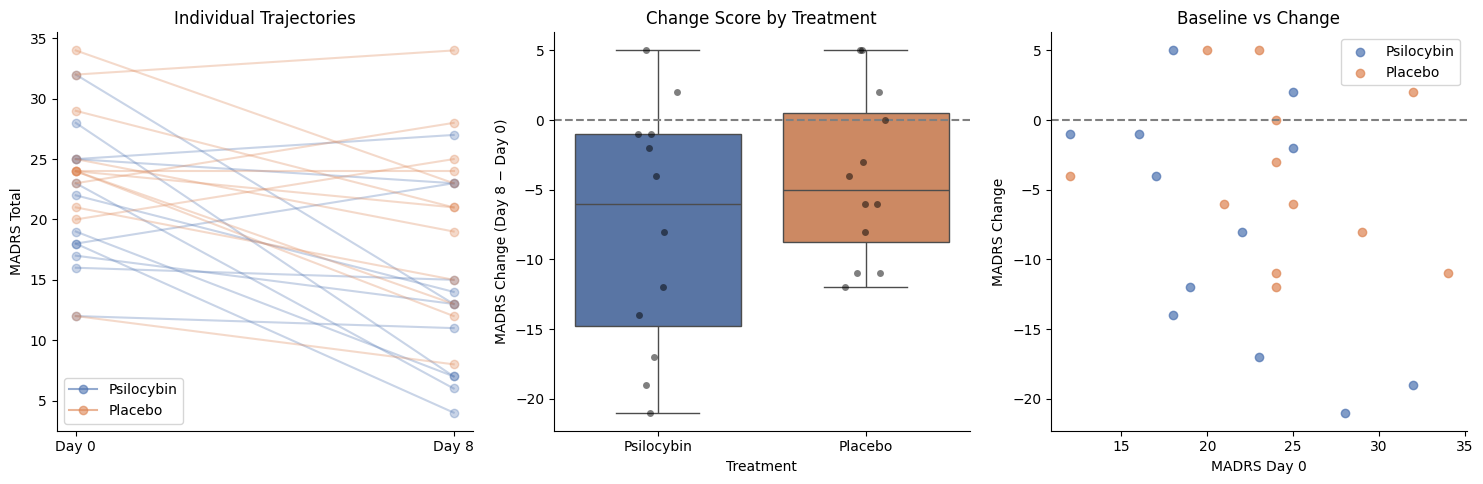

In [31]:
# ── 7. FIGURES ────────────────────────────────────────────────────────────────
from matplotlib.lines import Line2D

GROUP_ORDER = ["Psilocybin", "Placebo"]
PALETTE = {"Psilocybin": "#4C72B0", "Placebo": "#DD8452"}

fig, axes = plt.subplots(1, 3, figsize=(15, 5))

# A: paired change by group
ax = axes[0]
for grp in GROUP_ORDER:
    sub = madrs_wide[madrs_wide["Treatment"] == grp].dropna(subset=["MADRS_d0", "MADRS_d8"])
    for _, row in sub.iterrows():
        ax.plot([0, 1], [row["MADRS_d0"], row["MADRS_d8"]], "o-",
                alpha=0.3, color=PALETTE[grp])
ax.set_xticks([0, 1])
ax.set_xticklabels(["Day 0", "Day 8"])
ax.set_ylabel("MADRS Total")
ax.set_title("Individual Trajectories")
ax.legend([Line2D([0], [0], color=PALETTE[g], marker="o", linestyle="-", alpha=0.6)
           for g in GROUP_ORDER], GROUP_ORDER, frameon=True)

# B: change score by group
ax = axes[1]
sns.boxplot(data=madrs_wide, x="Treatment", y="MADRS_change", ax=ax,
            order=GROUP_ORDER, hue="Treatment", hue_order=GROUP_ORDER,
            palette=PALETTE, legend=False)
sns.stripplot(data=madrs_wide, x="Treatment", y="MADRS_change", ax=ax,
              order=GROUP_ORDER, color="black", alpha=0.5)
ax.axhline(0, color="grey", linestyle="--")
ax.set_ylabel("MADRS Change (Day 8 − Day 0)")
ax.set_title("Change Score by Treatment")

# C: baseline vs change
ax = axes[2]
for grp in GROUP_ORDER:
    sub = madrs_wide[madrs_wide["Treatment"] == grp]
    ax.scatter(sub["MADRS_d0"], sub["MADRS_change"],
               c=PALETTE[grp], label=grp, alpha=0.7)
ax.set_xlabel("MADRS Day 0")
ax.set_ylabel("MADRS Change")
ax.axhline(0, color="grey", linestyle="--")
ax.legend(frameon=True)
ax.set_title("Baseline vs Change")

plt.tight_layout()
plt.savefig(f"{SAVEFIG}madrs_analysis.png", dpi=330)
plt.show()

In [32]:
# ── BETWEEN-GROUP COMPARISONS WITH EFFECT SIZES ──────────────────────────────
def rank_biserial(u, n1, n2):
    """Rank-biserial correlation: effect size for Mann-Whitney U."""
    return 1 - (2 * u) / (n1 * n2)

print("\n=== BETWEEN-GROUP COMPARISONS (Mann-Whitney U) ===")
print(f"{'Variable':25s} {'n1':>4s} {'n2':>4s} {'U':>6s} {'p':>8s} {'r_rb':>8s} {'effect':>12s}")
print("-" * 75)

groups = madrs_wide['Treatment'].dropna().unique()

for col in ['MADRS_d0', 'MADRS_d8', 'MADRS_change', 'MADRS_pct_change']:
    g1 = madrs_wide.loc[madrs_wide['Treatment'] == groups[0], col].dropna()
    g2 = madrs_wide.loc[madrs_wide['Treatment'] == groups[1], col].dropna()
    stat, p = sts.mannwhitneyu(g1, g2, alternative='two-sided')
    r = rank_biserial(stat, len(g1), len(g2))

    # Cohen's benchmarks for rank-biserial: small=.1, medium=.3, large=.5
    size = "large" if abs(r) >= .5 else "medium" if abs(r) >= .3 else "small"

    print(f"  {col:23s} {len(g1):4d} {len(g2):4d} {stat:6.0f} {p:8.3f} {r:8.2f} ({size})")

# ── MANUSCRIPT-READY TABLE ────────────────────────────────────────────────────
print(f"\n=== MANUSCRIPT TABLE: MADRS by Treatment Group ===")
print(f"\n{'':25s} {groups[0]:>20s} {groups[1]:>20s} {'U':>6s} {'p':>7s} {'r':>6s}")
print("-" * 90)

for col, label in [('MADRS_d0', 'Baseline (Day 0)'),
                    ('MADRS_d8', 'Post-treatment (Day 8)'),
                    ('MADRS_change', 'Change (Day 8 − Day 0)'),
                    ('MADRS_pct_change', '% Change')]:
    g1 = madrs_wide.loc[madrs_wide['Treatment'] == groups[0], col].dropna()
    g2 = madrs_wide.loc[madrs_wide['Treatment'] == groups[1], col].dropna()
    stat, p = sts.mannwhitneyu(g1, g2, alternative='two-sided')
    r = rank_biserial(stat, len(g1), len(g2))

    fmt_g1 = f"{g1.mean():.1f} ± {g1.std():.1f} [{g1.median():.1f}]"
    fmt_g2 = f"{g2.mean():.1f} ± {g2.std():.1f} [{g2.median():.1f}]"
    p_str = f"{p:.3f}" if p >= .001 else "<.001"

    print(f"  {label:23s} {fmt_g1:>20s} {fmt_g2:>20s} {stat:6.0f} {p_str:>7s} {r:6.2f}")

print(f"\nValues: M ± SD [Mdn]. r = rank-biserial correlation.")


### OUPUT TO TABLE:
rows = []
for col, label in [('MADRS_d0', 'Baseline (Day 0)'),
                    ('MADRS_d8', 'Post-treatment (Day 8)'),
                    ('MADRS_change', 'Change (Day 8 − Day 0)'),
                    ('MADRS_pct_change', '% Change')]:
    g1 = madrs_wide.loc[madrs_wide['Treatment'] == groups[0], col].dropna()
    g2 = madrs_wide.loc[madrs_wide['Treatment'] == groups[1], col].dropna()
    stat, p = sts.mannwhitneyu(g1, g2, alternative='two-sided')
    r = rank_biserial(stat, len(g1), len(g2))
    p_str = f"{p:.3f}" if p >= .001 else "<.001"

    rows.append({
        'Measure': label,
        groups[0]: f"{g1.mean():.1f} ± {g1.std():.1f} [{g1.median():.1f}]",
        groups[1]: f"{g2.mean():.1f} ± {g2.std():.1f} [{g2.median():.1f}]",
        'U': f"{stat:.0f}",
        'p': p_str,
        'r': f"{r:.2f}",
    })

madrs_table = pd.DataFrame(rows)
print(madrs_table.to_string(index=False))

###
savetable = SAVETABLE
madrs_table.to_csv(f"{savetable}madrs_statistics.csv", index=False)
###


=== BETWEEN-GROUP COMPARISONS (Mann-Whitney U) ===
Variable                    n1   n2      U        p     r_rb       effect
---------------------------------------------------------------------------
  MADRS_d0                  12   12     96    0.182    -0.33 (medium)
  MADRS_d8                  12   12    106    0.049    -0.48 (medium)
  MADRS_change              12   12     89    0.340    -0.24 (small)
  MADRS_pct_change          12   12     89    0.341    -0.24 (small)

=== MANUSCRIPT TABLE: MADRS by Treatment Group ===

                                       Placebo           Psilocybin      U       p      r
------------------------------------------------------------------------------------------
  Baseline (Day 0)           24.3 ± 5.7 [24.0]    21.2 ± 5.6 [20.5]     96   0.182  -0.33
  Post-treatment (Day 8)     20.2 ± 7.4 [21.0]    13.6 ± 7.4 [13.0]    106   0.049  -0.48
  Change (Day 8 − Day 0)     -4.1 ± 6.0 [-5.0]    -7.7 ± 8.7 [-6.0]     89   0.340  -0.24
  % Change      

In [33]:
from docx import Document
from docx.shared import Pt

doc = Document()
doc.add_heading("MADRS by Treatment Group", level=2)
table = doc.add_table(rows=1, cols=len(madrs_table.columns), style="Light Shading Accent 1")

for j, col in enumerate(madrs_table.columns):
    cell = table.rows[0].cells[j]
    cell.text = col
    for run in cell.paragraphs[0].runs:
        run.bold = True
        run.font.size = Pt(9)

for _, row in madrs_table.iterrows():
    cells = table.add_row().cells
    for j, val in enumerate(row):
        cells[j].text = str(val)
        for run in cells[j].paragraphs[0].runs:
            run.font.size = Pt(9)

doc.add_paragraph("Values: M ± SD [Mdn]. r = rank-biserial correlation.", style="Normal")
doc.save(f"{savetable}madrs_statistics.docx")


In [34]:
# ── BRAIN–BEHAVIOUR ASSOCIATIONS (eTable) ────────────────────────────────────

MEASURES = ['MADRS_change', 'MADRS_pct_change']
CLIN_LAB = {'MADRS_change': 'ΔMADRS', 'MADRS_pct_change': 'MADRS % change'}
BRAIN_LAB = {'ddir': 'Δdirectedness', 'drho': 'ρ(ΔHL, FC gradient)'}

brain_ready = madrs_wide[['MRI_subject', 'Treatment',
                           'MADRS_d0', 'MADRS_d8',
                           'MADRS_change', 'MADRS_pct_change',
                           'MADRS_responder', 'MADRS_remission']].copy()

print(f"\nBrain-ready dataframe: {len(brain_ready)} subjects")
print(brain_ready.head())


# long frame: one row per participant, both brain measures as columns
brain_long = pd.concat([
    pd.DataFrame({'subjects': active_rest_subjects,
                  'ddir': DA2R - DA1R, 'drho': rho_analysis['rhoA']}),
    pd.DataFrame({'subjects': placebo_rest_subjects,
                  'ddir': DP2R - DP1R, 'drho': rho_analysis['rhoP']}),
], ignore_index=True).merge(brain_ready, left_on='subjects',
                            right_on='MRI_subject', how='inner')

assert len(brain_long) == len(active_rest_subjects) + len(placebo_rest_subjects), \
    "participants lost in merge"

def boot_ci(x, y, n=5000, seed=42):
    rng = np.random.default_rng(seed)
    x, y = np.asarray(x, float), np.asarray(y, float)
    out = []
    for _ in range(n):
        i = rng.integers(0, len(x), len(x))
        if len(np.unique(i)) > 3:
            out.append(sts.spearmanr(x[i], y[i]).statistic)
    return np.nanpercentile(out, [2.5, 97.5])

def fmt_p(p):
    return "<.001" if p < .001 else f"{p:.3f}".lstrip("0")

rows = []
for grp in ['Psilocybin', 'Placebo']:
    sub = brain_long[brain_long['Treatment'] == grp]
    for bx in ['ddir', 'drho']:
        for cy in MEASURES:
            res = pg.corr(sub[bx], sub[cy], method='spearman')
            rho = float(res['r'].iloc[0]); p = float(res['p_val'].iloc[0])
            lo, hi = [float(v) for v in res['CI95'].iloc[0]]
            blo, bhi = boot_ci(sub[bx], sub[cy])
            rows.append({'Group': grp,
                         'Brain measure': BRAIN_LAB[bx],
                         'Clinical measure': CLIN_LAB[cy],
                         'n': len(sub), 'rho': round(rho, 2),
                         '95% CI': f"{lo:.2f} to {hi:.2f}",
                         'Bootstrap 95% CI': f"{blo:.2f} to {bhi:.2f}",
                         'P': fmt_p(p), '_p': p})

tab = pd.DataFrame(rows)
_, p_fdr, _, _ = multipletests(tab['_p'], method='fdr_bh')
tab['P (FDR)'] = [fmt_p(p) for p in p_fdr]
tab = tab.drop(columns='_p')

print(tab.to_string(index=False))
tab.to_csv(f"{SAVEFIG}eTable_brain_behaviour.csv", index=False)

# inline strings for pasting into the manuscript
print("\n=== MANUSCRIPT-READY STRINGS ===")
for _, r in tab.iterrows():
    print(f"{r['Group']:11s} {r['Brain measure']:22s} {r['Clinical measure']:15s} "
          f"ρ = {r['rho']:.2f}; 95% CI, {r['95% CI']}; P = {r['P']}")


Brain-ready dataframe: 24 subjects
  MRI_subject   Treatment  MADRS_d0  MADRS_d8  MADRS_change  MADRS_pct_change  \
0    P13     Placebo        23        28             5         21.739130   
1    P01  Psilocybin        19         7           -12        -63.157895   
2    P14     Placebo        24        21            -3        -12.500000   
3    P15     Placebo        25        19            -6        -24.000000   
4    P02  Psilocybin        17        13            -4        -23.529412   

   MADRS_responder  MADRS_remission  
0            False            False  
1             True             True  
2            False            False  
3            False            False  
4            False            False  
     Group       Brain measure Clinical measure  n   rho         95% CI Bootstrap 95% CI    P P (FDR)
Psilocybin       Δdirectedness           ΔMADRS 12 -0.74 -0.92 to -0.29   -0.92 to -0.30 .006    .045
Psilocybin       Δdirectedness   MADRS % change 12 -0.67 -0.90 to -0.1

In [64]:
# ── TABLE 1: baseline characteristics + MADRS, analytic sample (n = 24) ─────
# Replaces the first draft of this cell. Prints and saves group aggregates only.
from docx import Document
from docx.shared import Pt
from docx.enum.text import WD_ALIGN_PARAGRAPH

T1_CSV = os.path.join(os.path.dirname(PET_TO_MR_XLSX), "table1(Sheet1).csv")
base = pd.read_csv(T1_CSV, sep=None, engine="python", encoding="utf-8-sig")
mapx = pd.read_excel(PET_TO_MR_XLSX, usecols=["SubjectID", "MRI_subject", "Treatment"]).iloc[:35]

b = base.merge(mapx, on="SubjectID", how="inner", suffixes=("", "_map"))
b = b[b["MRI_subject"].isin(included_subjects)].copy()
assert len(b) == len(included_subjects) == 24, f"matched {len(b)} of {len(included_subjects)}"
b["Arm"] = b["Treatment_map"].map({"Active": "Psilocybin", "Placebo": "Placebo"})
assert b["Arm"].notna().all()
chk = b.merge(madrs_wide[["MRI_subject", "MADRS_d0"]], on="MRI_subject")
assert (chk["MADRS_baseline"] == chk["MADRS_d0"]).all(), "baseline MADRS differs from the analysis value"

ARMS = ["Psilocybin", "Placebo"]
N_ARM = {a: int((b.Arm == a).sum()) for a in ARMS}

def num(v):
    """Numbers stored as text: decimal comma, units or words around the number."""
    s = v.astype(str).str.replace(",", ".", regex=False).str.extract(r"(-?\d+(?:\.\d+)?)")[0]
    return pd.to_numeric(s, errors="coerce")

# Duration came back empty: show its format (pattern counts only, no values per person)
raw = b["Duration_current_episode"]
print("Duration_current_episode dtype:", raw.dtype, "| non-missing:", int(raw.notna().sum()),
      "| parsed as numbers:", int(num(raw).notna().sum()))
print("  formats:", raw.dropna().astype(str).str.replace(r"\d", "9", regex=True).value_counts().to_dict())

def mean_sd(col, rng=False, dec=1):
    out = {}
    for a in ARMS:
        x = num(b.loc[b.Arm == a, col]).dropna()
        if x.empty:
            out[a] = "—"; continue
        s = f"{x.mean():.{dec}f} ({x.std():.{dec}f})"
        if rng: s += f" [{x.min():g}–{x.max():g}]"
        if len(x) < N_ARM[a]: s += f"; n = {len(x)}"
        out[a] = s
    return out

def n_pct(col, test):
    out = {}
    for a in ARMS:
        v = b.loc[b.Arm == a, col].dropna().astype(str).str.strip().str.lower()
        k, n = int(v.map(test).sum()), len(v)
        out[a] = f"{k} ({100 * k / n:.0f})" + ("" if n == N_ARM[a] else f"; n = {n}")
    return out

isin = lambda *vals: (lambda s: s in {x.lower() for x in vals})
yes = isin("yes", "1", "1.0")

rows = []
def add(label, d=None, indent=False):
    rows.append({"Characteristic": ("    " if indent else "") + label,
                 **(d or {a: "" for a in ARMS})})

add("Age, mean (SD), y", mean_sd("Age_Baseline"))
add("Female sex", n_pct("Sex", isin("female")))
add("Education")
add("University degree", n_pct("Education", isin("university degree")), True)
add("High school", n_pct("Education", isin("high school")), True)
add("Elementary school", n_pct("Education", isin("elementary school")), True)
add("Employed or self-employed", n_pct("Employment", isin("employed", "selfemployed")))
add("Student", n_pct("Employment", isin("student")))
add("Full-time sick leave", n_pct("Sickleave_baseline", isin("fulltime")))
add("Clinical characteristics")
add("MADRS score, mean (SD)", mean_sd("MADRS_baseline"), True)
add("Duration of current episode", None, True)
_cats = b["Duration_current_episode"].dropna().astype(str).str.strip().unique()
for cat in sorted(_cats, key=lambda s: (not s.startswith("<"), s)):
    add("    " + cat.replace("mths", "mo").replace("-", "–"),
        n_pct("Duration_current_episode", isin(cat)), True)
add("Lifetime depressive episodes, mean (SD) [range]", mean_sd("Lifetime_depressive_episodes", rng=True), True)
add("Psychiatric inpatient admission", n_pct("HOSP_baseline", yes), True)
add("Suicide attempt, lifetime", n_pct("Attempted_suicide_ever", yes), True)
add("Previous treatment")
add("Psychotherapy, lifetime", n_pct("Psychotherapy_ever", yes), True)
add("SSRI", n_pct("SSRI", yes), True)
add("SNRI", n_pct("SNRI", yes), True)
add("Atypical antidepressant or anticonvulsant", n_pct("Atypical_anticonvul", yes), True)
add("Lithium, TCA, or MAOI", n_pct("Lithium_TCA_MAOI", yes), True)
add("Medication tapered before inclusion", n_pct("Tapered_medication", yes), True)
base_tab = pd.DataFrame(rows)

# MADRS outcomes, same numbers as the existing Table 1 (now one table)
if "rank_biserial" not in globals():
    rank_biserial = lambda u, n1, n2: 1 - 2 * u / (n1 * n2)
mw = madrs_wide[madrs_wide["MRI_subject"].isin(included_subjects)]
out_rows = []
for col, lab in [("MADRS_d8", "Day 8"),
                 ("MADRS_change", "Change (day 8 − day 0)"), ("MADRS_pct_change", "% Change")]:
    psi = mw.loc[mw.Treatment == "Psilocybin", col]; pla = mw.loc[mw.Treatment == "Placebo", col]
    u, p = sts.mannwhitneyu(pla, psi, alternative="two-sided")
    fmt = lambda x: f"{x.mean():.1f} ± {x.std():.1f} [{x.median():.1f}]".replace("-", "−")
    out_rows.append({"Characteristic": "    " + lab, "Psilocybin": fmt(psi), "Placebo": fmt(pla),
                     "U": f"{u:g}", "P": f"{p:.3f}".lstrip("0"),
                     "r_rb": f"{rank_biserial(u, len(pla), len(psi)):.2f}".replace("-", "−")})
out_tab = pd.DataFrame(out_rows)

tab1 = pd.concat([base_tab, pd.DataFrame([{"Characteristic": "MADRS score, mean ± SD [median]"}]),
                  out_tab], ignore_index=True).fillna("")
print(tab1.to_string(index=False))
tab1.to_csv(f"{SAVETABLE}Table1_baseline_MADRS.csv", index=False)

# Word export, same style as the eTables
doc = Document()
doc.styles["Normal"].font.name = "Calibri"; doc.styles["Normal"].font.size = Pt(9)
doc.add_paragraph().add_run(
    "Table 1. Baseline Characteristics and MADRS Scores of the Analytic Sample").bold = True
hdr = ["Characteristic", f"Psilocybin (n = {N_ARM['Psilocybin']})",
       f"Placebo (n = {N_ARM['Placebo']})", "U", "P", "r_rb"]
t = doc.add_table(rows=1, cols=len(hdr)); t.style = "Table Grid"
for j, h in enumerate(hdr):
    t.rows[0].cells[j].text = h; t.rows[0].cells[j].paragraphs[0].runs[0].bold = True
section_rows = {"Education", "Clinical characteristics", "Previous treatment",
                "MADRS score, mean ± SD [median]"}
for _, r in tab1.iterrows():
    cells = t.add_row().cells
    for j, k in enumerate(["Characteristic", "Psilocybin", "Placebo", "U", "P", "r_rb"]):
        cells[j].text = str(r[k])
        if j > 0: cells[j].paragraphs[0].alignment = WD_ALIGN_PARAGRAPH.CENTER
    if r["Characteristic"] in section_rows:
        cells[0].paragraphs[0].runs[0].bold = True
for n in [
    "Values are No. (%) unless otherwise indicated; percentages are of participants with "
    "available data (n shown where data were missing). Baseline characteristics were not "
    "compared statistically.",
    "MADRS scores: U, Mann–Whitney U test (placebo vs psilocybin); r_rb, rank-biserial "
    "correlation (negative values indicate lower scores in the psilocybin group).",
    "Abbreviations: MADRS, Montgomery–Åsberg Depression Rating Scale; MAOI, monoamine oxidase "
    "inhibitor; SNRI, serotonin-norepinephrine reuptake inhibitor; SSRI, selective serotonin "
    "reuptake inhibitor; TCA, tricyclic antidepressant.",
]:
    p = doc.add_paragraph(n); p.runs[0].font.size = Pt(8)
doc.save(f"{SAVETABLE}Table1_baseline_MADRS.docx")
print(f"\nsaved {SAVETABLE}Table1_baseline_MADRS.docx")

Duration_current_episode dtype: object | non-missing: 23 | parsed as numbers: 23
  formats: {'<99 mths': 13, '99-99 mths': 10}
                                     Characteristic               Psilocybin                 Placebo     U    P  r_rb
                                  Age, mean (SD), y              41.5 (10.0)             40.7 (10.1)                 
                                         Female sex                   7 (58)                  9 (75)                 
                                          Education                                                                  
                                  University degree           7 (64); n = 11           6 (67); n = 9                 
                                        High school           3 (27); n = 11           3 (33); n = 9                 
                                  Elementary school            1 (9); n = 11            0 (0); n = 9                 
                          Employed or self-empl

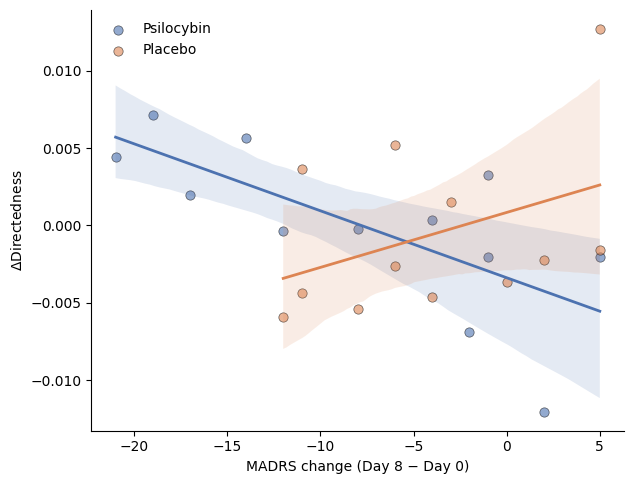

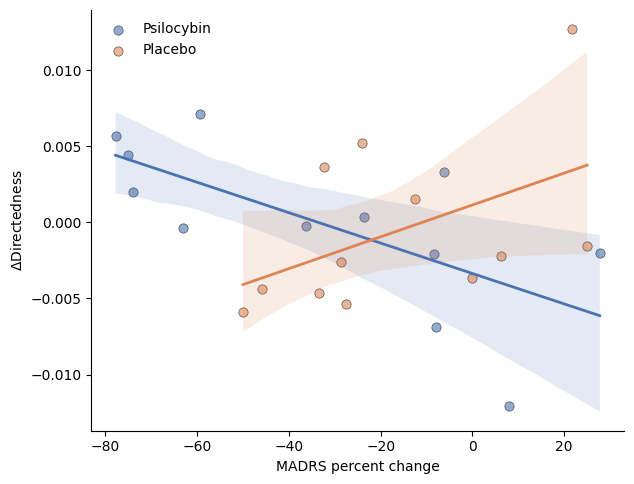

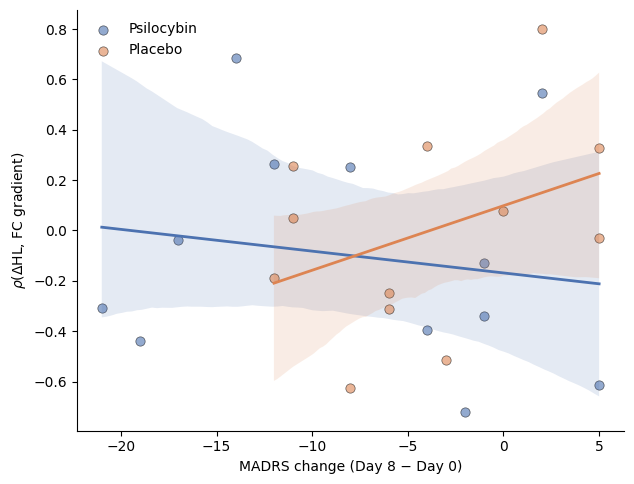

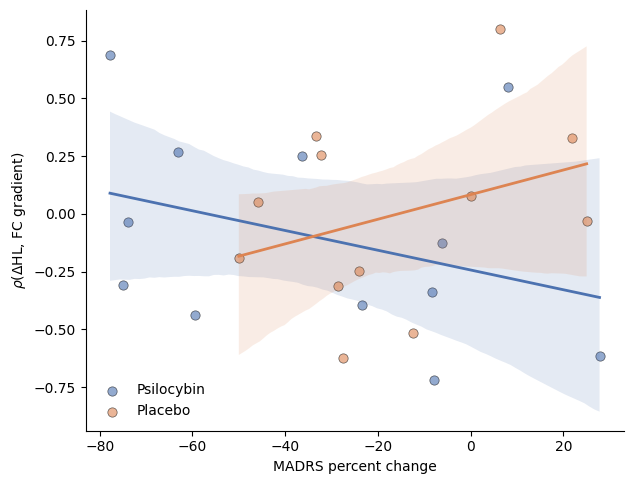

In [36]:
# ── BRAIN–BEHAVIOUR SCATTERS ─────────────────────────────────────────────────
GROUP_ORDER = ["Psilocybin", "Placebo"]
PALETTE = {"Psilocybin": "#4C72B0", "Placebo": "#DD8452"}

YLAB = {'ddir': r'$\Delta$Directedness', 'drho': r'$\rho$($\Delta$HL, FC gradient)'}
XLAB = {'MADRS_change': 'MADRS change (Day 8 − Day 0)',
        'MADRS_pct_change': 'MADRS percent change'}
FNAME = {'ddir': 'ddir', 'drho': 'rho_dHL_gradient'}

for bx in ['ddir', 'drho']:
    for cy in ['MADRS_change', 'MADRS_pct_change']:
        fig, ax = plt.subplots(figsize=(6.5, 5))
        for grp in GROUP_ORDER:
            sns.regplot(data=brain_long[brain_long['Treatment'] == grp],
                        x=cy, y=bx, ax=ax, color=PALETTE[grp], label=grp, ci=95,
                        scatter_kws={'s': 45, 'alpha': 0.6, 'edgecolor': 'black',
                                     'linewidths': 0.5},
                        line_kws={'linewidth': 2})
        ax.set_xlabel(XLAB[cy]); ax.set_ylabel(YLAB[bx])
        ax.legend(frameon=False)
        ax.spines[['top', 'right']].set_visible(False)
        fig.tight_layout()
        suffix = 'change' if cy == 'MADRS_change' else 'pctchange'
        fig.savefig(f"{SAVEFIG}{FNAME[bx]}_vs_MADRS_{suffix}.png",
                    dpi=330, bbox_inches='tight')
        plt.show()

The test below asks whether the gap between the two arms' correlations (−0.74 versus +0.48) is bigger than you'd expect if treatment allocation were irrelevant. Shuffling the labels breaks any treatment-specific brain–behaviour coupling while leaving the distributions of Δdirectedness and ΔMADRS untouched, so the null distribution shows what difference-in-correlations arises by chance at n = 12 per arm. The p-value is the fraction of shuffles whose absolute difference matches or exceeds yours.

In [37]:
def fisher_z_diff(r1, n1, r2, n2):
    z1, z2 = np.arctanh(r1), np.arctanh(r2)
    se = np.sqrt(1/(n1-3) + 1/(n2-3))
    z = (z1 - z2) / se
    return z, 2 * (1 - sts.norm.cdf(abs(z)))

print(fisher_z_diff(-0.74, 12, 0.48, 12))

# permutation alternative, safer at this n
d = brain_long.copy(); null = []
a0 = d[d.Treatment == 'Psilocybin']; b0 = d[d.Treatment == 'Placebo']
obs = (sts.spearmanr(a0.ddir, a0.MADRS_change).statistic
       - sts.spearmanr(b0.ddir, b0.MADRS_change).statistic)

print("observed difference:", round(obs, 3))


rng = np.random.default_rng(42)
for _ in range(10000):
    lab = rng.permutation(d['Treatment'].values)
    a = d[lab == 'Psilocybin']; b = d[lab == 'Placebo']
    null.append(sts.spearmanr(a.ddir, a.MADRS_change).statistic
                - sts.spearmanr(b.ddir, b.MADRS_change).statistic)
print("permutation p =", np.mean(np.abs(null) >= abs(obs)))


(-3.1256884336097346, 0.0017738938234803658)
observed difference: -1.224
permutation p = 0.0019


In [38]:
# Same for percent change
obs2 = (sts.spearmanr(a0.ddir, a0.MADRS_pct_change).statistic
        - sts.spearmanr(b0.ddir, b0.MADRS_pct_change).statistic)
null2 = []
for _ in range(10000):
    lab = rng.permutation(d['Treatment'].values)
    a = d[lab == 'Psilocybin']; b = d[lab == 'Placebo']
    null2.append(sts.spearmanr(a.ddir, a.MADRS_pct_change).statistic
                 - sts.spearmanr(b.ddir, b.MADRS_pct_change).statistic)
print(round(obs2, 3), np.mean(np.abs(null2) >= abs(obs2)))

-1.266 0.001


Check it isn't baseline severity. Baseline MADRS differed nominally between arms (24.3 vs 21.2, r_rb = −0.33), and change scores correlate with baseline through regression to the mean. If baseline drives part of this, the interaction is less interesting:

In [39]:
d2 = brain_long.copy()
for c in ['ddir', 'MADRS_change', 'MADRS_d0']:
    d2[c + '_r'] = d2[c].rank()
mod = smf.ols('MADRS_change_r ~ ddir_r * C(Treatment) + MADRS_d0_r', data=d2).fit()
print(mod.summary().tables[1])

                                     coef    std err          t      P>|t|      [0.025      0.975]
--------------------------------------------------------------------------------------------------
Intercept                         26.6122      4.029      6.604      0.000      18.178      35.046
C(Treatment)[T.Placebo]          -11.0234      4.613     -2.389      0.027     -20.679      -1.368
ddir_r                            -0.8222      0.230     -3.576      0.002      -1.303      -0.341
ddir_r:C(Treatment)[T.Placebo]     1.1828      0.325      3.639      0.002       0.502       1.863
MADRS_d0_r                        -0.3941      0.167     -2.357      0.029      -0.744      -0.044


In [40]:
# sensitivite to individual subjects: leave-one-out regression
rows = []
for s in brain_long['subjects']:
    dd = brain_long[brain_long.subjects != s].copy()
    for c in ['ddir', 'MADRS_change', 'MADRS_d0']:
        dd[c + '_r'] = dd[c].rank()
    mm = smf.ols('MADRS_change_r ~ ddir_r * C(Treatment) + MADRS_d0_r', data=dd).fit()
    term = 'ddir_r:C(Treatment)[T.Placebo]'
    rows.append({'dropped': s, 'beta': round(mm.params[term], 3),
                 'p': round(mm.pvalues[term], 4)})
loo_int = pd.DataFrame(rows).sort_values('p', ascending=False)
print(loo_int.to_string(index=False))
print("\nmax p across exclusions:", loo_int.p.max())

# summarize the beta and p-values across leave-one-out regressions
mean_beta = loo_int['beta'].mean()
mean_p = loo_int['p'].mean()
print(f"\nMean beta across leave-one-out regressions: {mean_beta:.3f}")
print(f"Mean p-value across leave-one-out regressions: {mean_p:.4f}")

 dropped  beta      p
P13 1.041 0.0106
P03 1.086 0.0064
P24 1.059 0.0054
P05 1.112 0.0051
P20 1.095 0.0041
P19 1.126 0.0031
P07 1.231 0.0030
P22 1.162 0.0029
P21 1.111 0.0029
P04 1.170 0.0026
P10 1.264 0.0026
P11 1.196 0.0026
P18 1.206 0.0024
P06 1.213 0.0022
P08 1.192 0.0022
P14 1.202 0.0019
P02 1.197 0.0019
P09 1.205 0.0019
P01 1.213 0.0017
P15 1.255 0.0013
P17 1.227 0.0012
P16 1.266 0.0012
P12 1.264 0.0006
P23 1.266 0.0005

max p across exclusions: 0.0106

Mean beta across leave-one-out regressions: 1.182
Mean p-value across leave-one-out regressions: 0.0029


feat NOT subset; don't know how to subset; dropped
fond NOT subset; don't know how to subset; dropped
morx NOT subset; don't know how to subset; dropped


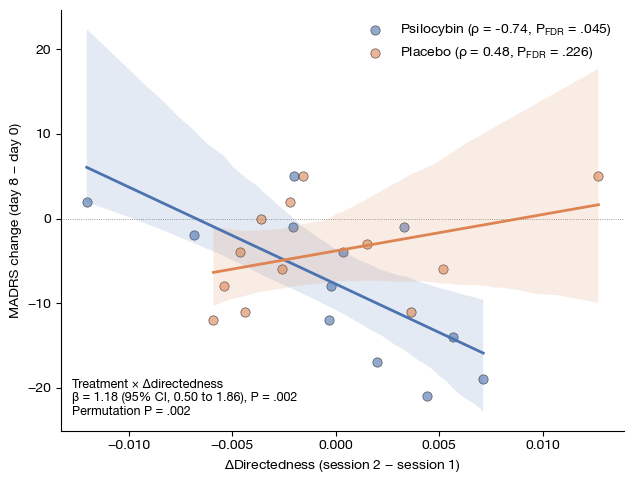

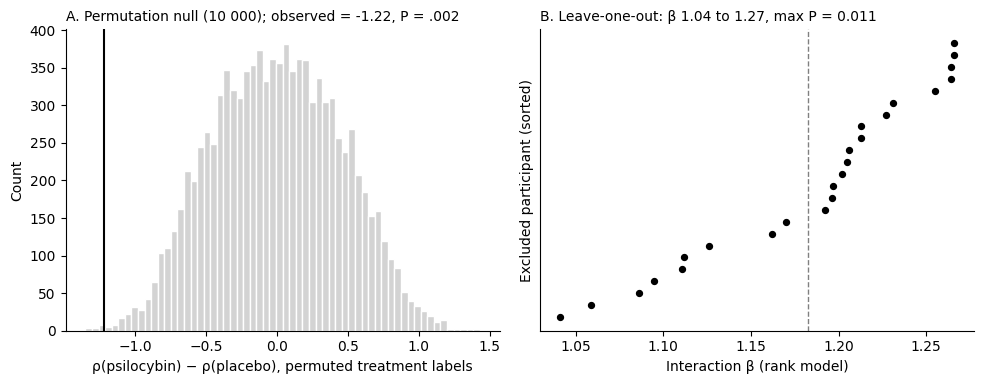

In [41]:
# ── FIGURE 2: Δdirectedness → MADRS change, with the interaction test ─────────
# Axes follow the model: Δdirectedness is the predictor (x), MADRS change the outcome (y).
# Lines are least-squares fits on raw values, shown for illustration; inference used ranks.

HN = {"font.family": "Helvetica Neue", "font.weight": "normal",
      "axes.labelweight": "light",
      "mathtext.fontset": "custom", "mathtext.rm": "Helvetica Neue:light",
      "mathtext.it": "Helvetica Neue:italic:light",
      "pdf.fonttype": 42, "svg.fonttype": "none"}

term = 'ddir_r:C(Treatment)[T.Placebo]'
beta, (ci_lo, ci_hi), p_int = mod.params[term], mod.conf_int().loc[term], mod.pvalues[term]
p_perm = float(np.mean(np.abs(null) >= abs(obs)))

def _p(p):                       # JAMA style: P = .006, P < .001
    return "P < .001" if p < .001 else f"P = {p:.3f}".replace("0.", ".")

# FDR across the same 8 tests as the eTable: group × brain measure × clinical measure
_keys, _ps = [], []
for grp in ["Psilocybin", "Placebo"]:
    sub = brain_long[brain_long['Treatment'] == grp]
    for bx in ['ddir', 'drho']:
        for cy in ['MADRS_change', 'MADRS_pct_change']:
            _keys.append((grp, bx, cy)); _ps.append(sts.spearmanr(sub[bx], sub[cy]).pvalue)
p_fdr = dict(zip(_keys, multipletests(_ps, method='fdr_bh')[1]))

with plt.rc_context(HN):
    fig, ax = plt.subplots(figsize=(6.5, 5))
    for grp in ["Psilocybin", "Placebo"]:
        sub = brain_long[brain_long['Treatment'] == grp]
        rho = sts.spearmanr(sub['ddir'], sub['MADRS_change']).statistic
        pf = p_fdr[(grp, 'ddir', 'MADRS_change')]
        lab = f"{grp} (ρ = {rho:.2f}, " + r"$P_{FDR}$" + f" = {pf:.3f}".replace("0.", ".") + ")"
        sns.regplot(data=sub, x='ddir', y='MADRS_change', ax=ax, color=PALETTE[grp],
                    label=lab, ci=95,
                    scatter_kws={'s': 45, 'alpha': 0.6, 'edgecolor': 'black', 'linewidths': 0.5},
                    line_kws={'linewidth': 2})

    ax.axhline(0, color='grey', lw=0.6, ls=':', zorder=0)
    ax.set_xlabel(r'$\Delta$Directedness (session 2 − session 1)')
    ax.set_ylabel('MADRS change (day 8 − day 0)')
    ax.legend(frameon=False, loc='upper right')
    ax.text(0.02, 0.03,
            f"Treatment × Δdirectedness\n"
            f"β = {beta:.2f} (95% CI, {ci_lo:.2f} to {ci_hi:.2f}), {_p(p_int)}\n"
            f"Permutation {_p(p_perm)}",
            transform=ax.transAxes, ha='left', va='bottom', fontsize=9)
    ax.spines[['top', 'right']].set_visible(False)
    fig.tight_layout()
    for ext in ('png', 'pdf','svg'):
        fig.savefig(f"{SAVEFIG}Figure2_ddir_MADRS_interaction.{ext}", dpi=330, bbox_inches='tight')
    plt.show()

# ── eFigure: permutation null and leave-one-out stability ───────────────────
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 4))

a1.hist(null, bins=60, color='lightgrey', edgecolor='white')
a1.axvline(obs, color='black', lw=1.5)
a1.set_xlabel('ρ(psilocybin) − ρ(placebo), permuted treatment labels')
a1.set_ylabel('Count')
a1.set_title(f"A. Permutation null (10 000); observed = {obs:.2f}, {_p(p_perm)}", fontsize=10, loc='left')

loo = loo_int.sort_values('beta').reset_index(drop=True)          # participants not identified
a2.scatter(loo['beta'], np.arange(len(loo)), s=18, color='black')
a2.axvline(beta, color='grey', ls='--', lw=1)
a2.set_yticks([]); a2.set_ylabel('Excluded participant (sorted)')
a2.set_xlabel('Interaction β (rank model)')
a2.set_title(f"B. Leave-one-out: β {loo['beta'].min():.2f} to {loo['beta'].max():.2f}, "
             f"max P = {loo['p'].max():.3f}", fontsize=10, loc='left')

for a in (a1, a2):
    a.spines[['top', 'right']].set_visible(False)
fig.tight_layout()
for ext in ('png', 'pdf'):
    fig.savefig(f"{SAVEFIG}eFigure_interaction_permutation_loo.{ext}", dpi=330, bbox_inches='tight')
plt.show()

#### Post hoc: MADRS at days 15 and 42

Post hoc extension of the day-8 analysis to the parent trial's secondary clinician-rated time points. For each time point, among participants with imaging and MADRS at that time point:

* between-arm Mann-Whitney U tests on the score at that time point, on change from baseline (Day 0) and on percentage change;
* Spearman correlations between Δdirectedness and change, and percentage change, within each arm, FDR-corrected across the 4 tests of that time point;
* a treatment-label permutation test (10,000 shuffles) on the difference between the two arms' correlations.

Day 365 is not analysed: participants still depressed at day 42 were referred for standard treatment, and antidepressants were started in both arms after day 42.

The first code cell defines the functions, the second verifies that they reproduce the day-8 results exactly, the third runs days 15 and 42.

In [42]:
# ── POST HOC, MADRS AT DAYS 15 AND 42: functions ─────────────────────────────
# Reuses madrs_raw and madrs_treatment (under "# Brain-Behaviour"), included_subjects,
# rank_biserial, boot_ci and fmt_p (defined above), and the Δdirectedness arrays.

MADRS_ITEMS = [f'MADRS{i}' for i in range(1, 11)]
ARM = {'Active': 'Psilocybin', 'Placebo': 'Placebo'}

# long MADRS for the imaging sample, every time point
# (the day-8 cell narrowed `dff` to Dag 0 / Dag 8, so rebuild from the sources)
madrs_long_all = madrs_raw.merge(madrs_treatment, left_on='Acronym',
                                 right_on='akronym', how='inner')
madrs_long_all = madrs_long_all[madrs_long_all['MRI_subject'].isin(included_subjects)].copy()


def madrs_wide_at(tp):
    """One row per imaged participant with MADRS at `tp`: baseline, score, change, % change."""
    d = madrs_long_all[madrs_long_all['TimePoint'].isin(['Dag 0', tp])].copy()
    bad = d[d['MADRS_sum'] != d[MADRS_ITEMS].sum(axis=1)]
    if len(bad):
        print(f"WARNING {tp}: {len(bad)} row(s) where MADRS_sum != sum of items")
    w = (d.pivot_table(index=['MRI_subject', 'Treatment'], columns='TimePoint',
                       values='MADRS_sum', aggfunc='first')
          .reset_index())
    w.columns.name = None
    if tp not in w.columns:
        raise ValueError(f"no MADRS rows labelled {tp!r} for the imaging sample")
    w = w.rename(columns={'Dag 0': 'd0', tp: 'dt'}).dropna(subset=['d0', 'dt'])
    w['Treatment'] = w['Treatment'].map(ARM)
    w['change'] = w['dt'] - w['d0']
    w['pct_change'] = w['change'] / w['d0'] * 100
    return w


def between_arm(w, tp):
    """Mann-Whitney U, placebo vs psilocybin. U is the placebo statistic and r_rb < 0
    means lower scores in the psilocybin arm, the convention of the day-8 table."""
    day = tp.split()[-1]
    rows = []
    for col, lab in [('d0', 'Baseline (Day 0)'), ('dt', f'Day {day}'),
                     ('change', f'Change (Day {day} − Day 0)'), ('pct_change', '% Change')]:
        psi = w.loc[w['Treatment'] == 'Psilocybin', col]
        pla = w.loc[w['Treatment'] == 'Placebo', col]
        u, p = sts.mannwhitneyu(pla, psi, alternative='two-sided')
        rows.append({'Timepoint': tp, 'Measure': lab,
                     'Psilocybin': f"{psi.mean():.1f} ± {psi.std():.1f} [{psi.median():.1f}]",
                     'Placebo':    f"{pla.mean():.1f} ± {pla.std():.1f} [{pla.median():.1f}]",
                     'n psilocybin': len(psi), 'n placebo': len(pla),
                     'U': u, 'P': p, 'r_rb': rank_biserial(u, len(pla), len(psi))})
    return pd.DataFrame(rows)


def brain_frame(w):
    """Δdirectedness joined to MADRS, psilocybin then placebo in canonical order
    (the row order of `brain_long`, which the permutation depends on)."""
    b = pd.concat([pd.DataFrame({'subjects': active_rest_subjects, 'ddir': DA2R - DA1R}),
                   pd.DataFrame({'subjects': placebo_rest_subjects, 'ddir': DP2R - DP1R})],
                  ignore_index=True)
    return b.merge(w, left_on='subjects', right_on='MRI_subject', how='inner')


def brain_behaviour(b, tp):
    """Spearman Δdirectedness vs change and % change in each arm, FDR over these 4 tests."""
    rows = []
    for grp in ['Psilocybin', 'Placebo']:
        sub = b[b['Treatment'] == grp]
        for cy, lab in [('change', 'ΔMADRS'), ('pct_change', 'MADRS % change')]:
            res = pg.corr(sub['ddir'], sub[cy], method='spearman')
            lo, hi = [float(v) for v in res['CI95'].iloc[0]]
            blo, bhi = boot_ci(sub['ddir'], sub[cy])
            rows.append({'Timepoint': tp, 'Group': grp, 'Clinical measure': lab,
                         'n': len(sub), 'rho': float(res['r'].iloc[0]),
                         '95% CI': f"{lo:.2f} to {hi:.2f}",
                         'Bootstrap 95% CI': f"{blo:.2f} to {bhi:.2f}",
                         'P': float(res['p_val'].iloc[0])})
    t = pd.DataFrame(rows)
    t['P (FDR)'] = multipletests(t['P'], method='fdr_bh')[1]
    return t


def perm_diff(b, tp, n_perm=10_000, seed=42):
    """ρ(psilocybin) − ρ(placebo) against a treatment-label permutation null.
    One generator for both measures, consumed in the order of the day-8 cells."""
    rng = np.random.default_rng(seed)
    lab_obs = b['Treatment'].values
    rows = []
    for cy, lab in [('change', 'ΔMADRS'), ('pct_change', 'MADRS % change')]:
        def diff(lab_):
            a, c = b[lab_ == 'Psilocybin'], b[lab_ == 'Placebo']
            return (sts.spearmanr(a['ddir'], a[cy]).statistic
                    - sts.spearmanr(c['ddir'], c[cy]).statistic)
        obs = diff(lab_obs)
        null = np.array([diff(rng.permutation(lab_obs)) for _ in range(n_perm)])
        rows.append({'Timepoint': tp, 'Clinical measure': lab, 'n': len(b),
                     'observed difference': obs,
                     'P (permutation)': float(np.mean(np.abs(null) >= abs(obs)))})
    return pd.DataFrame(rows)


In [43]:
# ── CHECK: the functions reproduce the published day-8 results exactly ───────
w8 = madrs_wide_at('Dag 8')
b8 = brain_frame(w8)

# same participants, same order, same values as the day-8 analysis
assert list(b8['subjects']) == list(brain_long['subjects']), "participant order differs"
assert np.allclose(b8['ddir'], brain_long['ddir'])
assert np.allclose(b8['change'], brain_long['MADRS_change'])
assert np.allclose(b8['pct_change'], brain_long['MADRS_pct_change'])

# between-arm tests: Table 1 (U printed to the nearest integer, P to 3 decimals)
expected = {'Baseline (Day 0)': (96, .182), 'Day 8': (106, .049),
            'Change (Day 8 − Day 0)': (89, .340), '% Change': (89, .341)}
for _, r in between_arm(w8, 'Dag 8').iterrows():
    u_exp, p_exp = expected[r['Measure']]
    assert abs(r['U'] - u_exp) <= 0.5 and np.isclose(round(r['P'], 3), p_exp), \
        f"{r['Measure']}: U {r['U']} P {r['P']:.4f}, expected {u_exp} / {p_exp}"

# Δdirectedness rows of eTable_brain_behaviour.csv (written by the day-8 cell)
ref = pd.read_csv(f"{SAVEFIG}eTable_brain_behaviour.csv")
ref = ref[ref['Brain measure'] == 'Δdirectedness']
new = brain_behaviour(b8, 'Dag 8')
for (_, a), (_, e) in zip(new.iterrows(), ref.iterrows()):
    assert (a['Group'], a['Clinical measure']) == (e['Group'], e['Clinical measure'])
    assert round(a['rho'], 2) == e['rho'], (a['Group'], a['Clinical measure'], a['rho'])
    assert a['95% CI'] == e['95% CI'] and a['Bootstrap 95% CI'] == e['Bootstrap 95% CI']
    assert np.isclose(round(a['P'], 3), float(e['P']))

# permutation tests: must reproduce the day-8 cells above (obs/null, obs2/null2)
# exactly, whichever fit is loaded. Published fit: -1.224, P = .0019 and -1.266, P = .001
pm = perm_diff(b8, 'Dag 8')
assert np.isclose(pm['observed difference'][0], obs) and \
       pm['P (permutation)'][0] == float(np.mean(np.abs(null) >= abs(obs)))
assert np.isclose(pm['observed difference'][1], obs2) and \
       pm['P (permutation)'][1] == float(np.mean(np.abs(null2) >= abs(obs2)))

print("Day-8 reproduction: all checks passed "
      "(participants, Table 1, Δdirectedness eTable rows, both permutation tests).")


Day-8 reproduction: all checks passed (participants, Table 1, Δdirectedness eTable rows, both permutation tests).


In [44]:
# ── POST HOC: days 15 and 42 ─────────────────────────────────────────────────
TIMEPOINTS = ['Dag 15', 'Dag 42']
arm_tabs, bb_tabs, perm_tabs = [], [], []

for tp in TIMEPOINTS:
    w = madrs_wide_at(tp)
    b = brain_frame(w)
    n = b['Treatment'].value_counts()
    n_psi, n_pla = int(n.get('Psilocybin', 0)), int(n.get('Placebo', 0))
    print(f"\n==== {tp}: imaging + MADRS in psilocybin n = {n_psi}, placebo n = {n_pla}")
    if min(n_psi, n_pla) < 5:
        print("  NOTE: fewer than 5 in an arm; the correlations carry very little information")

    arm_tabs.append(between_arm(w, tp))
    bb_tabs.append(brain_behaviour(b, tp))
    perm_tabs.append(perm_diff(b, tp))

arm = pd.concat(arm_tabs, ignore_index=True)
bb = pd.concat(bb_tabs, ignore_index=True)
pm = pd.concat(perm_tabs, ignore_index=True)

show = lambda t: print(t.round({'U': 1, 'P': 3, 'r_rb': 2, 'rho': 2, 'P (FDR)': 3,
                                'observed difference': 3, 'P (permutation)': 4})
                        .to_string(index=False))
print("\n=== Between-arm (Mann-Whitney U) ==="); show(arm)
print("\n=== Δdirectedness vs MADRS, per arm (FDR within time point) ==="); show(bb)
print("\n=== Permutation: ρ(psilocybin) − ρ(placebo) ==="); show(pm)

arm.to_csv(f"{SAVETABLE}madrs_statistics_d15_d42.csv", index=False)
bb.to_csv(f"{SAVEFIG}eTable_brain_behaviour_d15_d42.csv", index=False)
pm.to_csv(f"{SAVEFIG}permutation_ddir_d15_d42.csv", index=False)

print("\n=== MANUSCRIPT-READY STRINGS ===")
for _, r in bb.iterrows():
    print(f"{r['Timepoint']:7s} {r['Group']:11s} {r['Clinical measure']:15s} n = {r['n']:2d}  "
          f"ρ = {r['rho']:.2f}; 95% CI, {r['95% CI']}; P = {fmt_p(r['P'])}; P_FDR = {fmt_p(r['P (FDR)'])}")
for _, r in pm.iterrows():
    print(f"{r['Timepoint']:7s} permutation, {r['Clinical measure']:15s} "
          f"difference = {r['observed difference']:.3f}; P = {r['P (permutation)']:.4f}")



==== Dag 15: imaging + MADRS in psilocybin n = 5, placebo n = 6

==== Dag 42: imaging + MADRS in psilocybin n = 12, placebo n = 12

=== Between-arm (Mann-Whitney U) ===
Timepoint                 Measure           Psilocybin              Placebo  n psilocybin  n placebo     U     P  r_rb
   Dag 15        Baseline (Day 0)    22.6 ± 7.9 [23.0]    27.8 ± 4.5 [27.0]             5          6  22.0 0.233 -0.47
   Dag 15                  Day 15      5.4 ± 5.2 [4.0]    24.2 ± 5.6 [22.5]             5          6  30.0 0.008 -1.00
   Dag 15 Change (Day 15 − Day 0)  -17.2 ± 5.8 [-18.0]    -3.7 ± 6.6 [-1.5]             5          6  28.0 0.021 -0.87
   Dag 15                % Change -77.4 ± 16.9 [-78.3]  -11.8 ± 20.4 [-6.0]             5          6  30.0 0.004 -1.00
   Dag 42        Baseline (Day 0)    21.2 ± 5.6 [20.5]    24.3 ± 5.7 [24.0]            12         12  95.5 0.182 -0.33
   Dag 42                  Day 42     12.8 ± 9.6 [8.5]    20.6 ± 7.8 [21.0]            12         12 106.0 0.052 -0.

#### Post hoc: self-rated MADRS-S on the day of scan 2

Post hoc. The self-rated MADRS-S was collected daily (dosing day = day 0, before dosing). For each participant we take the MADRS-S on the day of the second scan and compute change from day 0, so the clinical measure is concurrent with imaging rather than six days later.

* Day of scan 2 = days from dosing to the second MRI (PET-to-MR mapping file).
* Several entries on the same day are averaged (sensitivity: first entry in the file).
* No entry on the scan day: the nearest day within ±1 is used, never day 0, averaged if both neighbours exist.
* Participants without a day-0 score are excluded.
* Tests as for days 15 and 42: between-arm Mann-Whitney U; Spearman correlations between Δdirectedness and change, and percentage change, within each arm, FDR-corrected across these 4 tests; and the treatment-label permutation test on the difference between arms. Sensitivity: rank partial correlation adjusting for days since dosing.
* Validity: MADRS-S against clinician-rated MADRS at day 8.

Only aggregates are printed: the source files carry acronyms and dates.

In [45]:
# ── POST HOC: self-rated MADRS-S on the day of scan 2 ────────────────────────
# Prints aggregates only: the MADRS-S file and the mapping carry acronyms and dates.

def _parse_dates(s):
    """Dates stored as datetimes or as 'YYYY-MM-DD' / 'DD/MM/YYYY' strings."""
    s = pd.Series(s)
    out = pd.to_datetime(s.where(s.map(lambda v: not isinstance(v, str))), errors='coerce')
    st = s.map(lambda v: v.strip() if isinstance(v, str) else None)
    out = out.fillna(pd.to_datetime(st, format='%Y-%m-%d', errors='coerce'))
    out = out.fillna(pd.to_datetime(st, format='%d/%m/%Y', errors='coerce'))
    return out.dt.normalize()

# dates of dosing and both scans, imaged participants only. Neither source is
# complete on its own: scan_dates.xlsx first, gaps filled from the mapping file,
# and the two must agree wherever both have a date.
DCOLS = ['Dosingdate', 'MRI_date_1', 'MRI_date_2']
dates = pd.read_excel(PET_TO_MR_XLSX, usecols=['MRI_subject', 'Treatment', 'Acronym'] + DCOLS).iloc[:35]
dates = dates[dates['MRI_subject'].isin(included_subjects)].copy().set_index('MRI_subject')
sd = pd.read_excel(SCAN_DATES_XLSX, usecols=['MRI_name'] + DCOLS).set_index('MRI_name')
for c in DCOLS:
    a = pd.Series(_parse_dates(dates[c]).values, index=dates.index)
    b = pd.Series(_parse_dates(sd[c]).values, index=sd.index).reindex(dates.index)
    both = a.notna() & b.notna()
    assert (a[both] == b[both]).all(), f"{c} differs between scan_dates.xlsx and the mapping file"
    dates[c] = b.combine_first(a)
dates = dates.reset_index()
assert len(dates) == len(included_subjects), "imaged participant missing from the mapping file"
assert dates[['Dosingdate', 'MRI_date_2']].notna().all().all(), "dosing or scan-2 date missing"
dates['scan_day'] = (dates['MRI_date_2'] - dates['Dosingdate']).dt.days
dates['pre_days'] = (dates['Dosingdate'] - dates['MRI_date_1']).dt.days

madrss = pd.read_excel(MADRSS_XLSX)
assert (madrss['FormName'] == 'MADRS-S').all()
assert ((madrss['PerformedAt'] - madrss['Dosingdate']).dt.days == madrss['Days_from_dosing']).all()
dose_s = madrss.groupby('akronym')['Dosingdate'].first().dt.normalize()
assert (dates['Dosingdate'].values == dose_s.reindex(dates['Acronym']).values).all(), \
    "dosing date differs between the mapping and the MADRS-S file"


def madrss_scan_table(agg='mean'):
    """One row per imaged participant: MADRS-S on day 0 and on the scan-2 day."""
    daily = madrss.groupby(['akronym', 'Days_from_dosing'])['Value'].agg(agg)
    nrow = madrss.groupby(['akronym', 'Days_from_dosing']).size()
    rows = []
    for _, r in dates.iterrows():
        ac, d = r['Acronym'], int(r['scan_day'])
        get = lambda k: daily.get((ac, k), np.nan)
        base, dt, fallback = get(0), get(d), False
        used = [0, d]
        if np.isnan(dt):
            near = [k for k in (d - 1, d + 1) if k >= 1 and not np.isnan(get(k))]
            dt, fallback = (float(np.mean([get(k) for k in near])), True) if near else (np.nan, False)
            used = [0] + near
        rows.append({'MRI_subject': r['MRI_subject'], 'Treatment': ARM[r['Treatment']],
                     'scan_day': d, 'd0': base, 'dt': dt, 'fallback': fallback,
                     'dup_days': sum(int(nrow.get((ac, k), 0) > 1) for k in used)})
    w = pd.DataFrame(rows)
    n_nobase = int(w['d0'].isna().sum())
    w = w.dropna(subset=['d0', 'dt']).copy()
    assert (w['d0'] > 0).all(), "zero baseline: percentage change undefined"
    w['change'] = w['dt'] - w['d0']
    w['pct_change'] = w['change'] / w['d0'] * 100
    return w, n_nobase


w_s, n_nobase = madrss_scan_table('mean')
n_arm = w_s['Treatment'].value_counts()
print(f"Imaged participants: {len(dates)} | excluded, no day-0 MADRS-S: {n_nobase} | "
      f"analysed: psilocybin {n_arm.get('Psilocybin', 0)}, placebo {n_arm.get('Placebo', 0)}")
print(f"Scan-day score from a neighbouring day: {int(w_s['fallback'].sum())} | "
      f"days with several entries averaged: {int(w_s['dup_days'].sum())}")

# scan timing in the analytic sample (all imaged participants)
q = lambda x: f"median {x.median():.0f} (IQR {x.quantile(.25):.2f}-{x.quantile(.75):.2f}, range {x.min():.0f}-{x.max():.0f})"
print(f"\nDays from dosing to scan 2 (n = {len(dates)}): {q(dates['scan_day'])}")
print(f"Days from scan 1 to dosing (n = {int(dates['pre_days'].notna().sum())}): {q(dates['pre_days'].dropna())}")
for a, g in dates.assign(arm=dates['Treatment'].map(ARM)).groupby('arm'):
    print(f"   {a:10s} days to scan 2: {q(g['scan_day'])}")

# tests, as for days 15 and 42
TP = 'MADRS-S scan day'
relabel = lambda t: t.replace({'ΔMADRS': 'ΔMADRS-S', 'MADRS % change': 'MADRS-S % change',
                                'Day scan-day': 'Scan-2 day',
                                'Change (Day scan-day − Day 0)': 'Change (scan-2 day − Day 0)'})
arm_s = relabel(between_arm(w_s, 'MADRS-S scan-day'))
b_s = brain_frame(w_s)
bb_s = relabel(brain_behaviour(b_s, TP))
pm_s = relabel(perm_diff(b_s, TP))

# sensitivity 1: rank partial correlation adjusting for days since dosing
sens = []
for grp in ['Psilocybin', 'Placebo']:
    sub = b_s[b_s['Treatment'] == grp]
    for cy, lab in [('change', 'ΔMADRS-S'), ('pct_change', 'MADRS-S % change')]:
        pc = pg.partial_corr(data=sub, x='ddir', y=cy, covar='scan_day', method='spearman')
        pcol = 'p_val' if 'p_val' in pc.columns else 'p-val'
        sens.append({'Group': grp, 'Clinical measure': lab, 'n': int(pc['n'].iloc[0]),
                     'partial rho (days since dosing)': float(pc['r'].iloc[0]),
                     'P': float(pc[pcol].iloc[0])})
sens = pd.DataFrame(sens)

# sensitivity 2: first entry instead of the mean for duplicated days
w_f, _ = madrss_scan_table('first')
bb_f = relabel(brain_behaviour(brain_frame(w_f), TP + ' (first entry)'))

# validity: self-rated vs clinician-rated MADRS at day 8
s8 = madrss[madrss['Days_from_dosing'] == 8].groupby('akronym')['Value'].mean()
c8 = madrs_wide_at('Dag 8').set_index('MRI_subject')['dt']
v = dates.set_index('MRI_subject')['Acronym'].map(s8).rename('self').to_frame().join(c8.rename('clin')).dropna()
rv = sts.spearmanr(v['self'], v['clin'])

show = lambda t: print(t.round({'U': 1, 'P': 3, 'r_rb': 2, 'rho': 2, 'P (FDR)': 3,
                                'observed difference': 3, 'P (permutation)': 4,
                                'partial rho (days since dosing)': 2}).to_string(index=False))
print("\n=== Between-arm (Mann-Whitney U) ==="); show(arm_s)
print("\n=== Δdirectedness vs MADRS-S on the scan-2 day, per arm (FDR across these 4) ==="); show(bb_s)
print("\n=== Permutation: ρ(psilocybin) − ρ(placebo) ==="); show(pm_s)
print("\n=== Sensitivity: rank partial correlation adjusting for days since dosing ==="); show(sens)
print("\n=== Sensitivity: first entry for duplicated days ==="); show(bb_f[['Group', 'Clinical measure', 'n', 'rho', 'P']])
print(f"\nValidity, day 8: MADRS-S vs clinician MADRS, Spearman rho = {rv.statistic:.2f}, P = {fmt_p(rv.pvalue)}, n = {len(v)}")

arm_s.to_csv(f"{SAVETABLE}madrss_scanday_between_arm.csv", index=False)
bb_s.to_csv(f"{SAVEFIG}eTable_brain_behaviour_madrss.csv", index=False)
pm_s.to_csv(f"{SAVEFIG}permutation_ddir_madrss.csv", index=False)
sens.to_csv(f"{SAVEFIG}madrss_sensitivity_days_since_dosing.csv", index=False)

Imaged participants: 24 | excluded, no day-0 MADRS-S: 2 | analysed: psilocybin 12, placebo 10
Scan-day score from a neighbouring day: 1 | days with several entries averaged: 4

Days from dosing to scan 2 (n = 24): median 2 (IQR 2.00-2.25, range 1-5)
Days from scan 1 to dosing (n = 24): median 7 (IQR 4.50-10.25, range 1-59)
   Placebo    days to scan 2: median 2 (IQR 2.00-2.00, range 1-4)
   Psilocybin days to scan 2: median 2 (IQR 2.00-3.00, range 2-5)

=== Between-arm (Mann-Whitney U) ===
       Timepoint                     Measure           Psilocybin             Placebo  n psilocybin  n placebo    U     P  r_rb
MADRS-S scan-day            Baseline (Day 0)    27.5 ± 5.7 [26.0]   30.0 ± 5.2 [30.5]            12         10 75.0 0.336 -0.25
MADRS-S scan-day                  Scan-2 day    18.5 ± 7.3 [22.0]  27.4 ± 10.4 [30.5]            12         10 95.0 0.023 -0.58
MADRS-S scan-day Change (scan-2 day − Day 0)    -9.0 ± 7.0 [-8.0]   -2.6 ± 6.2 [-0.2]            12         10 95.0 0.023

#### Test whether model fit was associated with ∆directedness, participant-level ρ(ΔHL, FC gradient), or MADRS score in either group 

In [46]:
### Model fit vs brain and behaviour measures

def _by_name(mat, key, canonical, col=True):
    names = np.array([x[0] for x in mat['subjects'][0]])
    pos = {s: i for i, s in enumerate(names)}
    arr = mat[key][:, 0] if col else mat[key][0]
    return arr[np.array([pos[s] for s in canonical], dtype=int)]

def frame(canon, label, ddir, rho, dfc, dcov):
    return pd.DataFrame(dict(
        MRI_subject=np.asarray(canon), group=label,
        ddir=np.asarray(ddir), rho_dHL_grad=np.asarray(rho),
        dfit_fc=np.asarray(dfc), dfit_cov=np.asarray(dcov),
        MADRS_change=m.loc[list(canon), 'MADRS_change'].to_numpy(),
        MADRS_pct_change=m.loc[list(canon), 'MADRS_pct_change'].to_numpy()))

fc_act_1_rest = _by_name(act_1_rest, 'fittFC_subj', active_rest_subjects)
fc_act_2_rest = _by_name(act_2_rest, 'fittFC_subj', active_rest_subjects)
fc_pla_1_rest = _by_name(pla_1_rest, 'fittFC_subj', placebo_rest_subjects)
fc_pla_2_rest = _by_name(pla_2_rest, 'fittFC_subj', placebo_rest_subjects)

cov_act_1_rest = _by_name(act_1_rest, 'fittCOVtau_subj', active_rest_subjects)
cov_act_2_rest = _by_name(act_2_rest, 'fittCOVtau_subj', active_rest_subjects)
cov_pla_1_rest = _by_name(pla_1_rest, 'fittCOVtau_subj', placebo_rest_subjects)
cov_pla_2_rest = _by_name(pla_2_rest, 'fittCOVtau_subj', placebo_rest_subjects)

delta_fc_act  = fc_act_2_rest - fc_act_1_rest
delta_cov_act = cov_act_2_rest - cov_act_1_rest
delta_fc_pla  = fc_pla_2_rest - fc_pla_1_rest
delta_cov_pla = cov_pla_2_rest - cov_pla_1_rest

# Compute delta 
DiffAR = np.array(DA2R) - np.array(DA1R)
DiffPR = np.array(DP2R) - np.array(DP1R)

m = brain_ready.set_index('MRI_subject')

# get from r4 in hierarchy_unpack.py
rhoA = rho_analysis['rhoA'] # psilocybin rho_dHL_grad
rhoP = rho_analysis['rhoP'] # placebo rho_dHL_grad

df = pd.concat([frame(active_rest_subjects, 'active',  DiffAR, rhoA, delta_fc_act, delta_cov_act),
                frame(placebo_rest_subjects, 'placebo', DiffPR, rhoP, delta_fc_pla, delta_cov_pla)],
               ignore_index=True)

rows = []
for g, sub in df.groupby("group"):
    for fit in ["dfit_fc", "dfit_cov"]:
        for tgt in ["ddir", "rho_dHL_grad", "MADRS_change", "MADRS_pct_change"]:
            r = pg.corr(sub[fit], sub[tgt], method="spearman")
            rows.append(dict(group=g, fit=fit, target=tgt,
                             rho=round(float(r['r'].iloc[0]), 3),
                             ci=r['CI95'].iloc[0],
                             p=round(float(r['p_val'].iloc[0]), 3)))
# print(pd.DataFrame(rows).to_string(index=False))

for fit in ["dfit_fc", "dfit_cov"]:
    print(fit, pg.mwu(df.query("group=='active'")[fit],
                      df.query("group=='placebo'")[fit])[['U_val','p_val']].to_dict('records'))
    
tab = pd.DataFrame(rows)
_, p_fdr, _, _ = multipletests(tab['p'], method='fdr_bh')
tab['p_fdr'] = np.round(p_fdr, 3)
print(tab.to_string(index=False))


dfit_fc [{'U_val': 85.0, 'p_val': 0.47048642205878966}]
dfit_cov [{'U_val': 90.0, 'p_val': 0.3123214216762161}]
  group      fit           target    rho            ci     p  p_fdr
 active  dfit_fc             ddir -0.371 [-0.78, 0.26] 0.236  0.890
 active  dfit_fc     rho_dHL_grad -0.154 [-0.67, 0.46] 0.633  0.948
 active  dfit_fc     MADRS_change -0.039  [-0.6, 0.55] 0.905  0.948
 active  dfit_fc MADRS_pct_change  0.119 [-0.49, 0.65] 0.713  0.948
 active dfit_cov             ddir -0.517 [-0.84, 0.08] 0.085  0.890
 active dfit_cov     rho_dHL_grad  0.119 [-0.49, 0.65] 0.713  0.948
 active dfit_cov     MADRS_change  0.042  [-0.55, 0.6] 0.897  0.948
 active dfit_cov MADRS_pct_change  0.091 [-0.51, 0.63] 0.779  0.948
placebo  dfit_fc             ddir  0.280 [-0.35, 0.74] 0.379  0.948
placebo  dfit_fc     rho_dHL_grad  0.021 [-0.56, 0.59] 0.948  0.948
placebo  dfit_fc     MADRS_change  0.341 [-0.29, 0.77] 0.278  0.890
placebo  dfit_fc MADRS_pct_change  0.343 [-0.29, 0.77] 0.276  0.890
plac

No associations between change in model fit and any brain or clinical measure survived correction (all FDR-corrected P = 0.90).

#### Test sensitivity for regional level analysis.

In [47]:
# ── SENSITIVITY: regional analysis (eTable 8) ────────────────────────────────
# A. leave-one-out on the ΔHL × gradient association, per arm
# B. inter-participant consistency of individual ΔHL maps

def loo_regional(H1, H2, subjects, n_spin=1000, n_boot=200):
    rows = []
    for k in range(len(subjects)):
        idx = [i for i in range(len(subjects)) if i != k]
        r = analysis1_regionwise(H1[idx], H2[idx], grad_parc, parcellation,
                                 n_boot=n_boot, n_spin=n_spin, seed=SEED)
        rows.append({'r': float(r['r']), 'p_spin': float(r['spin']['p_spin'])})
    return pd.DataFrame(rows).sort_values('r').reset_index(drop=True)

def consistency(H1, H2):
    d = np.asarray(H2 - H1, float)
    v = []
    for k in range(d.shape[0]):
        others = np.nanmean(np.delete(d, k, axis=0), axis=0)
        v.append(float(sts.spearmanr(d[k], others, nan_policy='omit').statistic))
    return np.array(v)

loo_A = loo_regional(HA1R, HA2R, active_rest_subjects)
loo_P = loo_regional(HP1R, HP2R, placebo_rest_subjects)
con_A, con_P = consistency(HA1R, HA2R), consistency(HP1R, HP2R)

for lab, l, c in [('Psilocybin', loo_A, con_A), ('Placebo', loo_P, con_P)]:
    print(f"{lab}: LOO r {l.r.min():.3f} to {l.r.max():.3f}, "
          f"non-significant in {(l.p_spin >= .05).sum()} of {len(l)}")
    print(f"   consistency mean {c.mean():+.3f}, range {c.min():+.3f} to {c.max():+.3f}")
print(pg.mwu(con_A, con_P)[['U_val', 'p_val']])
print(pg.wilcoxon(con_A, np.zeros_like(con_A))[['W_val', 'p_val']])

/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:16: RuntimeWarning: Mean of empty slice
  contrast = np.nanmean(dP, axis=0) - np.nanmean(dA, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:22: RuntimeWarning: Mean of empty slice
  np.nanmean(dP[rng.integers(0, nP, nP)], axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:23: RuntimeWarning: Mean of empty slice
  - np.nanmean(dA[rng.integers(0, nA, nA)], axis=0)
~/miniconda3/lib/python3.10/site-packages/numpy/lib/nanfunctions.py:1563: RuntimeWarning: All-NaN slice encountered
  return function_base._ureduce(a,
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:16: RuntimeWarning: Mean of empty slice
  contrast = np.nanmean(dP, axis=0) - np.nanmean(dA, axis=0)
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/556978755.py:22: RuntimeWarning: Mean of empty slice
  np.nanmean(dP[rng.integers(0, nP,

Psilocybin: LOO r -0.558 to -0.208, non-significant in 3 of 12
   consistency mean +0.105, range -0.343 to +0.276
Placebo: LOO r -0.163 to 0.171, non-significant in 12 of 12
   consistency mean +0.287, range -0.006 to +0.606
     U_val     p_val
MWU   50.0  0.214494
          W_val     p_val
Wilcoxon   18.0  0.109863


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/490497282.py:18: RuntimeWarning: Mean of empty slice
  others = np.nanmean(np.delete(d, k, axis=0), axis=0)


In [48]:
doc = Document()
doc.styles['Normal'].font.name = 'Calibri'; doc.styles['Normal'].font.size = Pt(9)
doc.add_paragraph().add_run(
    'eTable 8. Sensitivity of the regional analysis to sample composition.').bold = True

t = doc.add_table(rows=1, cols=5); t.style = 'Table Grid'
for j, lab in enumerate(['Group', 'Participant excluded', 'ρ', 'P (spin)', '']):
    t.rows[0].cells[j].text = lab
    if lab: t.rows[0].cells[j].paragraphs[0].runs[0].bold = True

for lab, l in [('Psilocybin', loo_A), ('Placebo', loo_P)]:
    for i, r in l.iterrows():
        cells = t.add_row().cells
        cells[0].text = lab if i == 0 else ''
        cells[1].text = f'{i+1}'
        cells[2].text = f"{r['r']:.2f}"
        cells[3].text = ('<.001' if r['p_spin'] < .001
                         else f"{r['p_spin']:.3f}".lstrip('0'))
        cells[4].text = '' if r['p_spin'] < .05 else 'ns'

for n in [
    "Each row gives the association between the group-mean change in hierarchical level "
    "and the principal functional connectivity gradient when one participant is excluded. "
    "Participants are ordered by the resulting ρ and are not identified. "
    "In the full sample the association was ρ = −0.39 (P = .01) in the psilocybin group "
    "and ρ = −0.06 (P = .74) in the placebo group.",
    "Inter-participant consistency of individual change maps, computed as the correlation "
    "between each participant's map and the mean of the remaining participants, did not "
    "differ between arms (U = 56, P = .37) and did not exceed zero in the psilocybin arm "
    "(W = 22, P = .20).",
]:
    p = doc.add_paragraph(n); p.runs[0].font.size = Pt(8)

doc.save(f"{savetable}eTable8_regional_sensitivity.docx")

#### Does baseline MADRS difference drive result?

In [49]:
import statsmodels.formula.api as smf

md = madrs_wide.copy()
md['grp'] = (md['Treatment'] == 'Psilocybin').astype(int)   # placebo = reference

m = smf.ols('MADRS_d8 ~ grp + MADRS_d0', data=md).fit()
print(m.summary().tables[1])
ci = m.conf_int().loc['grp']
print(f"adjusted difference (psilocybin − placebo): {m.params['grp']:.2f} "
      f"(95% CI, {ci[0]:.2f} to {ci[1]:.2f}), P = {m.pvalues['grp']:.3f}")

# rank-based version, consistent with the rest of the paper
for c in ['MADRS_d8', 'MADRS_d0']:
    md[c + '_r'] = md[c].rank()
mr = smf.ols('MADRS_d8_r ~ grp + MADRS_d0_r', data=md).fit()
print(f"rank-based: beta = {mr.params['grp']:.2f}, P = {mr.pvalues['grp']:.3f}")

                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept      8.8456      6.749      1.311      0.204      -5.191      22.882
grp           -5.2216      2.988     -1.747      0.095     -11.436       0.993
MADRS_d0       0.4687      0.264      1.772      0.091      -0.081       1.019
adjusted difference (psilocybin − placebo): -5.22 (95% CI, -11.44 to 0.99), P = 0.095
rank-based: beta = -4.63, P = 0.104


# Data quality
mean and max framewise displacement and tSNR
* eFigure 12: mean and max FD for BOLD data
* eTable 4: Mean and max framewise displacement for BOLD data (check N)
* eFigure 13: Mean and max of framewise displacement (FD) for diffusion MRI data
* eTable 5: Primary non-parametric comparisons for DWI data
* eFigure 14. Mean grey matter temporal signal-to-noise ratio (tSNR). 

#### FD for BOLD data

In [50]:

MOTION = MOTION_DIR
TSDIR = TS_DIR

# which participants were scanned on the GE Signa
signa_subs = {m.group(1) for f in glob.glob(
    TSDIR + "sub-*_ses-*_task-rest_acq-gesigna_space-fsLR_seg-Gordon_stat-mean_timeseries.tsv")
    if (m := re.search(r"(sub-\d+)", os.path.basename(f)))}

rows, missing = [], []
for grp, subs in [("Psilocybin", active_rest_subjects),
                  ("Placebo",    placebo_rest_subjects)]:
    for sub in subs:
        for ses, lab in [("ses-01", "Before"), ("ses-02", "After")]:
            f = f"{MOTION}{sub}_{ses}_task-rest_setting-preproc1_desc-confounds_regressors.tsv"
            if not os.path.exists(f):
                missing.append((sub, ses)); continue
            fd = pd.read_csv(f, sep="\t")["framewise_displacement"]
            rows.append({"subject": sub, "group": grp, "session": lab,
                         "meanFD": fd.mean(), "maxFD": fd.max(),
                         "scanner": "GE Signa" if sub in signa_subs else "GE Discovery"})

bold = pd.DataFrame(rows)
if missing:
    print(f"WARNING: missing confounds files: {missing}")
print(f"BOLD: {bold.subject.nunique()} participants, {len(bold)} scans")
print(bold.groupby(['group', 'scanner']).subject.nunique())

BOLD: 24 participants, 48 scans
group       scanner     
Placebo     GE Discovery    8
            GE Signa        4
Psilocybin  GE Discovery    9
            GE Signa        3
Name: subject, dtype: int64


In [51]:
# ── MOTION QC: figures 11-12, tables 4-5 ─────────────────────────────────────

GROUP_ORDER, SES_ORDER = ["Psilocybin", "Placebo"], ["Before", "After"]
SCAN_ORDER = ["GE Discovery", "GE Signa"]
PALETTE = {"Psilocybin": "#4C72B0", "Placebo": "#DD8452"}
MET = {"meanFD": "Mean FD (mm)", "maxFD": "Max FD (mm)"}

def mwu_row(a, b, comp, meas, ctx, unit="participants"):
    s, p = sts.mannwhitneyu(a, b, alternative="two-sided")
    return {"Comparison": comp, "Measure": meas, "Context": ctx,
            "N1": len(a), "N2": len(b), "Unit": unit,
            "Mean diff (mm)": round(np.mean(a) - np.mean(b), 4),
            "Statistic": round(s, 1), "p-value": round(p, 4)}

rows = []
# between groups, per session
for ses in SES_ORDER:
    for m in MET:
        a = bold.query("group=='Psilocybin' and session==@ses")[m]
        b = bold.query("group=='Placebo'    and session==@ses")[m]
        rows.append(mwu_row(a, b, "Psilocybin vs Placebo", m, ses))

# within group, across sessions (paired) - missing from your Table 4
for grp in GROUP_ORDER:
    for m in MET:
        w = bold.query("group==@grp").pivot(index="subject", columns="session",
                                            values=m).dropna()
        s, p = sts.wilcoxon(w["Before"], w["After"])
        rows.append({"Comparison": f"{grp}: Before vs After", "Measure": m,
                     "Context": "Paired", "N1": len(w), "N2": len(w),
                     "Unit": "participants",
                     "Mean diff (mm)": round((w["Before"] - w["After"]).mean(), 4),
                     "Statistic": round(s, 1), "p-value": round(p, 4)})

# between scanners - participant-level means, pooled across sessions
per_sub = bold.groupby(["subject", "group", "scanner"], as_index=False)[list(MET)].mean()
for grp in GROUP_ORDER:
    for m in MET:
        d = per_sub.query("group==@grp and scanner=='GE Discovery'")[m]
        s_ = per_sub.query("group==@grp and scanner=='GE Signa'")[m]
        rows.append(mwu_row(d, s_, "GE Discovery vs GE Signa", m, grp))

table4 = pd.DataFrame(rows)
print(table4.to_string(index=False))
table4.to_csv(f"{SAVEFIG}/table4_bold_fd.csv", index=False)

                 Comparison Measure    Context  N1  N2         Unit  Mean diff (mm)  Statistic  p-value
      Psilocybin vs Placebo  meanFD     Before  12  12 participants          0.0429       82.0   0.5834
      Psilocybin vs Placebo   maxFD     Before  12  12 participants          0.0565       84.0   0.5067
      Psilocybin vs Placebo  meanFD      After  12  12 participants          0.0013       69.0   0.8852
      Psilocybin vs Placebo   maxFD      After  12  12 participants         -0.0501       65.0   0.7075
Psilocybin: Before vs After  meanFD     Paired  12  12 participants          0.0091       25.0   0.3013
Psilocybin: Before vs After   maxFD     Paired  12  12 participants          0.0281       30.0   0.5186
   Placebo: Before vs After  meanFD     Paired  12  12 participants         -0.0325       18.0   0.1099
   Placebo: Before vs After   maxFD     Paired  12  12 participants         -0.0785       12.0   0.0342
   GE Discovery vs GE Signa  meanFD Psilocybin   9   3 participa

/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/1235405038.py:6: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:0.2'` for the same effect.

  sns.stripplot(data=bold, x="session", y=m, hue="group", order=SES_ORDER,
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/1235405038.py:19: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{s}\n(n={n.get(s,0)})" for s in SCAN_ORDER])
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/1235405038.py:6: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:0.2'` for the same effect.

  sns.stripplot(data=bold, x="session", y=m, hue="group", order=SES_ORDER,
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/1235405038.py:19: UserWarning: set_tickla

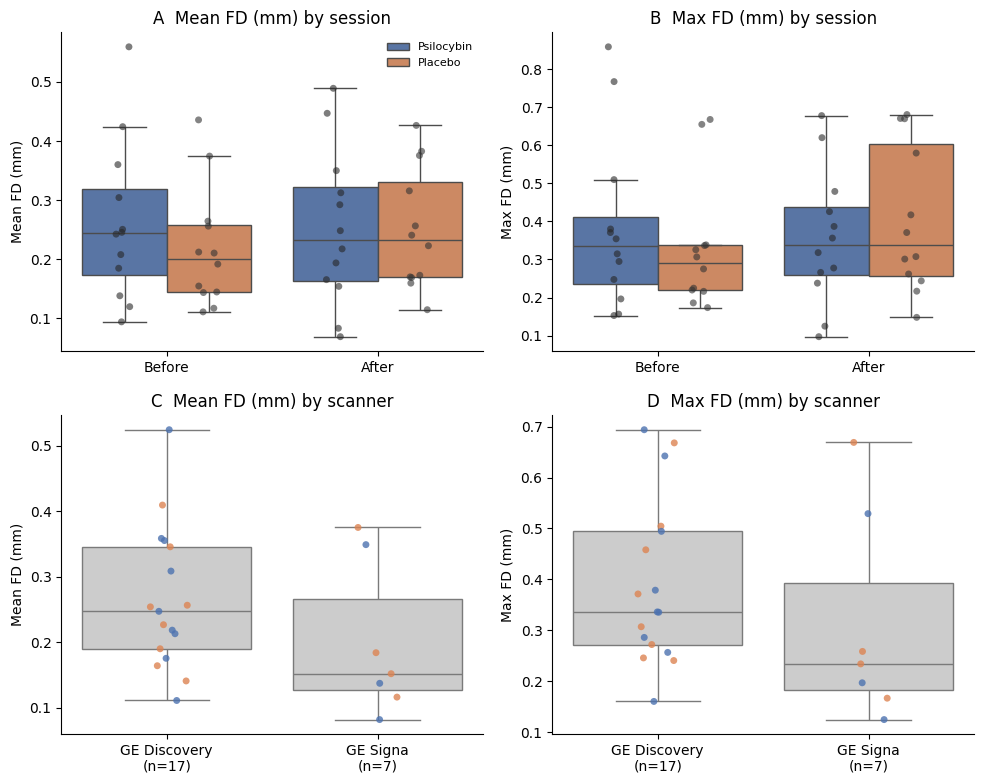

In [52]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8))
for j, m in enumerate(MET):
    ax = axes[0, j]
    sns.boxplot(data=bold, x="session", y=m, hue="group", order=SES_ORDER,
                hue_order=GROUP_ORDER, palette=PALETTE, ax=ax, showfliers=False)
    sns.stripplot(data=bold, x="session", y=m, hue="group", order=SES_ORDER,
                  hue_order=GROUP_ORDER, dodge=True, color="0.2", alpha=.6,
                  ax=ax, legend=False)
    ax.set_title(f"{'AB'[j]}  {MET[m]} by session"); ax.set_ylabel(MET[m]); ax.set_xlabel("")
    ax.legend(frameon=False, fontsize=8) if j == 0 else ax.legend_.remove()

    ax = axes[1, j]
    sns.boxplot(data=per_sub, x="scanner", y=m, order=SCAN_ORDER,
                color="0.8", ax=ax, showfliers=False)
    sns.stripplot(data=per_sub, x="scanner", y=m, order=SCAN_ORDER,
                  hue="group", hue_order=GROUP_ORDER, palette=PALETTE,
                  dodge=False, alpha=.8, ax=ax, legend=False)
    n = per_sub.scanner.value_counts()
    ax.set_xticklabels([f"{s}\n(n={n.get(s,0)})" for s in SCAN_ORDER])
    ax.set_title(f"{'CD'[j]}  {MET[m]} by scanner"); ax.set_ylabel(MET[m]); ax.set_xlabel("")
for ax in axes.ravel():
    ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(f"{SAVEFIG}/fig11_bold_fd.png", dpi=330, bbox_inches="tight")

In [53]:
FD_THRESH = 0.5

rows, missing = [], []
for grp, subs in [("Psilocybin", active_rest_subjects),
                  ("Placebo",    placebo_rest_subjects)]:
    for sub in subs:
        for ses, lab in [("ses-01", "Before"), ("ses-02", "After")]:
            f = f"{MOTION}{sub}_{ses}_task-rest_setting-preproc1_desc-confounds_regressors.tsv"
            if not os.path.exists(f):
                missing.append((sub, ses)); continue
            fd = pd.read_csv(f, sep="\t")["framewise_displacement"].dropna()
            rows.append({"subject": sub, "group": grp, "session": lab,
                         "meanFD": fd.mean(), "maxFD": fd.max(),
                         "n_vols": len(fd),
                         "n_flag": int((fd > FD_THRESH).sum()),
                         "pct_flag": 100 * (fd > FD_THRESH).mean(),
                         "scanner": "GE Signa" if sub in signa_subs else "GE Discovery"})
bold = pd.DataFrame(rows)

In [54]:
print(bold.groupby(['group', 'session'])['pct_flag']
          .agg(['median', 'max']).round(1))

# scans with any flagged volumes, and the worst offenders
flagged = bold.query("n_flag > 0").sort_values("pct_flag", ascending=False)
print(f"\nscans with ≥1 volume > {FD_THRESH} mm: {len(flagged)} / {len(bold)}")
print(flagged[['subject', 'group', 'session', 'meanFD', 'maxFD',
               'n_flag', 'n_vols', 'pct_flag']].round(2).to_string(index=False))

# conventional concern thresholds
print("\nmean FD > 0.5 mm:", bold.query("meanFD > 0.5")[['subject','session','meanFD']].to_dict('records'))
print("more than 20% volumes flagged:",
      bold.query("pct_flag > 20")[['subject','session','pct_flag']].round(1).to_dict('records'))

                    median   max
group      session              
Placebo    After       0.0   8.6
           Before      0.0  13.9
Psilocybin After       0.0  47.2
           Before      0.0  79.0

scans with ≥1 volume > 0.5 mm: 11 / 48
 subject      group session  meanFD  maxFD  n_flag  n_vols  pct_flag
P04 Psilocybin  Before    0.56   0.77     211     267     79.03
P04 Psilocybin   After    0.49   0.62     126     267     47.19
P11 Psilocybin   After    0.45   0.68      57     267     21.35
P09 Psilocybin  Before    0.42   0.86      52     267     19.48
P16    Placebo  Before    0.44   0.66      37     267     13.86
P24    Placebo  Before    0.37   0.67      24     267      8.99
P24    Placebo   After    0.38   0.67      23     267      8.61
P13    Placebo   After    0.43   0.58      20     267      7.49
P16    Placebo   After    0.38   0.68      14     267      5.24
P15    Placebo   After    0.32   0.67       7     267      2.62
P02 Psilocybin  Before    0.36   0.51       3     267

#### Test whether motion was associated with ∆directedness, participant-level ρ(ΔHL, FC gradient), or MADRS score in either group 

In [55]:
# ── MOTION AS A POTENTIAL CONFOUND ───────────────────────────────────────────
# test whether change in head motion relates to any reported measure, and whether the treatment ×
# Δdirectedness interaction survives adjustment for it.

# 1. Δmotion per participant (After − Before)
w_mean = bold.pivot(index='subject', columns='session', values='meanFD')
w_max  = bold.pivot(index='subject', columns='session', values='maxFD')
dmot = pd.DataFrame({'subjects': w_mean.index,
                     'dmeanFD': (w_mean['After'] - w_mean['Before']).values,
                     'dmaxFD':  (w_max['After']  - w_max['Before']).values})

mot = brain_long.merge(dmot, on='subjects', how='left')
assert mot[['dmeanFD', 'dmaxFD']].notna().all().all(), "missing motion for some participants"
print(f"n = {len(mot)}")

# 2. does Δmotion differ between arms?
for c in ['dmeanFD', 'dmaxFD']:
    a = mot.query("Treatment == 'Psilocybin'")[c]
    b = mot.query("Treatment == 'Placebo'")[c]
    r = pg.mwu(a, b)
    print(f"{c}: median {a.median():+.3f} vs {b.median():+.3f} mm | "
          f"U = {float(r['U_val'].iloc[0]):.0f}, p = {float(r['p_val'].iloc[0]):.3f}")

# 3. is Δmotion associated with any reported measure?
TARGETS = ['ddir', 'drho', 'MADRS_change', 'MADRS_pct_change']
rows = []
for grp in ['Psilocybin', 'Placebo']:
    sub = mot[mot.Treatment == grp]
    for mv in ['dmeanFD', 'dmaxFD']:
        for tgt in TARGETS:
            r = pg.corr(sub[mv], sub[tgt], method='spearman')
            rows.append({'Group': grp, 'Motion': mv, 'Target': tgt,
                         'n': len(sub), 'rho': round(float(r['r'].iloc[0]), 2),
                         '95% CI': r['CI95'].iloc[0],
                         'p': round(float(r['p_val'].iloc[0]), 3)})
tab_mot = pd.DataFrame(rows)
_, p_fdr, _, _ = multipletests(tab_mot['p'], method='fdr_bh')
tab_mot['p_fdr'] = np.round(p_fdr, 3)
print("\n" + tab_mot.to_string(index=False))
tab_mot.to_csv(f"{SAVEFIG}eTable_motion_confound.csv", index=False)

# 4. does the interaction survive adjustment for Δmotion?
d3 = mot.copy()
for c in ['ddir', 'MADRS_change', 'MADRS_d0', 'dmeanFD']:
    d3[c + '_r'] = d3[c].rank()

base = smf.ols('MADRS_change_r ~ ddir_r * C(Treatment) + MADRS_d0_r', data=d3).fit()
adj  = smf.ols('MADRS_change_r ~ ddir_r * C(Treatment) + MADRS_d0_r + dmeanFD_r', data=d3).fit()

term = 'ddir_r:C(Treatment)[T.Placebo]'
print(f"\ninteraction, unadjusted:        beta = {base.params[term]:.3f}, "
      f"p = {base.pvalues[term]:.4f}")
print(f"interaction, + ΔmeanFD:        beta = {adj.params[term]:.3f}, "
      f"p = {adj.pvalues[term]:.4f}")
print(f"ΔmeanFD coefficient:           beta = {adj.params['dmeanFD_r']:.3f}, "
      f"p = {adj.pvalues['dmeanFD_r']:.4f}")

n = 24
dmeanFD: median -0.015 vs +0.017 mm | U = 42, p = 0.089
dmaxFD: median -0.024 vs +0.034 mm | U = 39, p = 0.061

     Group  Motion           Target  n   rho        95% CI     p  p_fdr
Psilocybin dmeanFD             ddir 12  0.20  [-0.42, 0.7] 0.527  0.947
Psilocybin dmeanFD             drho 12 -0.02 [-0.59, 0.56] 0.948  0.966
Psilocybin dmeanFD     MADRS_change 12 -0.32 [-0.76, 0.31] 0.307  0.947
Psilocybin dmeanFD MADRS_pct_change 12 -0.17 [-0.68, 0.45] 0.602  0.947
Psilocybin  dmaxFD             ddir 12  0.22  [-0.4, 0.71] 0.484  0.947
Psilocybin  dmaxFD             drho 12  0.36 [-0.27, 0.77] 0.255  0.947
Psilocybin  dmaxFD     MADRS_change 12 -0.36 [-0.77, 0.27] 0.254  0.947
Psilocybin  dmaxFD MADRS_pct_change 12 -0.27 [-0.73, 0.36] 0.404  0.947
   Placebo dmeanFD             ddir 12  0.08 [-0.51, 0.63] 0.795  0.947
   Placebo dmeanFD             drho 12 -0.13 [-0.65, 0.48] 0.697  0.947
   Placebo dmeanFD     MADRS_change 12  0.11  [-0.5, 0.64] 0.744  0.947
   Placebo dmeanF

In [56]:
LAB = {'dmeanFD': 'Δ mean FD', 'dmaxFD': 'Δ maximum FD',
       'ddir': 'ΔDirectedness', 'drho': 'ρ(ΔHL, FC gradient)',
       'MADRS_change': 'MADRS change', 'MADRS_pct_change': 'MADRS % change'}

out = tab_mot.copy()
out['Motion'] = out['Motion'].map(LAB)
out['Target'] = out['Target'].map(LAB)
for c in ['p', 'p_fdr']:
    out[c] = out[c].apply(lambda v: '>.99' if v > .995 else f'{v:.2f}'.lstrip('0'))
out.to_csv(f"{savetable}eTable6_motion.csv", index=False)
print(out.to_string(index=False))

     Group       Motion              Target  n   rho        95% CI   p p_fdr
Psilocybin    Δ mean FD       ΔDirectedness 12  0.20  [-0.42, 0.7] .53   .95
Psilocybin    Δ mean FD ρ(ΔHL, FC gradient) 12 -0.02 [-0.59, 0.56] .95   .97
Psilocybin    Δ mean FD        MADRS change 12 -0.32 [-0.76, 0.31] .31   .95
Psilocybin    Δ mean FD      MADRS % change 12 -0.17 [-0.68, 0.45] .60   .95
Psilocybin Δ maximum FD       ΔDirectedness 12  0.22  [-0.4, 0.71] .48   .95
Psilocybin Δ maximum FD ρ(ΔHL, FC gradient) 12  0.36 [-0.27, 0.77] .26   .95
Psilocybin Δ maximum FD        MADRS change 12 -0.36 [-0.77, 0.27] .25   .95
Psilocybin Δ maximum FD      MADRS % change 12 -0.27 [-0.73, 0.36] .40   .95
   Placebo    Δ mean FD       ΔDirectedness 12  0.08 [-0.51, 0.63] .80   .95
   Placebo    Δ mean FD ρ(ΔHL, FC gradient) 12 -0.13 [-0.65, 0.48] .70   .95
   Placebo    Δ mean FD        MADRS change 12  0.11  [-0.5, 0.64] .74   .95
   Placebo    Δ mean FD      MADRS % change 12  0.20  [-0.42, 0.7] .53   .95

#### FD for DTI data

In [57]:
SCDIR = DWI_DIR

def dwi_ids(ses):
    return {m.group(1) for f in os.listdir(f'{SCDIR}/{ses}')
            if f.endswith('.mat') and (m := re.match(r'(sub-\d+)', f))}

dwi1, dwi2 = dwi_ids('ses-01'), dwi_ids('ses-02')
print(len(dwi1), len(dwi2))


roster = (madrs_raw[['MRI_subject', 'Treatment']].drop_duplicates()
          .rename(columns={'MRI_subject': 'subject', 'Treatment': 'group'}))
roster['dwi_ses1'] = roster.subject.isin(dwi1)
roster['dwi_ses2'] = roster.subject.isin(dwi2)
roster['bold']     = roster.subject.isin(set(bold.subject))

print("roster n =", len(roster))
print(roster.groupby('group', dropna=False)[['dwi_ses1', 'dwi_ses2', 'bold']].sum())
print("\nno treatment label:", sorted(roster.loc[roster.group.isna(), 'subject']))
print("in scan folders but not roster:", sorted((dwi1 | dwi2) - set(roster.subject)))
print("DWI session 1 only:", sorted(roster.loc[roster.dwi_ses1 & ~roster.dwi_ses2, 'subject']))


25 18
roster n = 35
         dwi_ses1  dwi_ses2  bold
group                            
Active         12         9    12
Placebo        12         9    12

no treatment label: []
in scan folders but not roster: ['P25']
DWI session 1 only: ['P26', 'P27', 'P28', 'P29', 'P30', 'P31']


In [58]:
# ── DWI motion: Figure 12 and Table 5 ────────────────────────────────────────

SCDIR = DWI_DIR
DWI_CSV = DWI_QC_CSV

def dwi_ids(ses):
    return {m.group(1) for f in os.listdir(f'{SCDIR}/{ses}')
            if f.endswith('.mat') and (m := re.match(r'(sub-\d+)', f))}

dwi1, dwi2 = dwi_ids('ses-01'), dwi_ids('ses-02')
print(len(dwi1), len(dwi2))


# 1. the DWI sample IS whatever entered the connectome -----------------------
sample = pd.DataFrame(
    [{'subject': re.match(r'(sub-\d+)', f).group(1), 'session': lab}
     for ses, lab in [('ses-01', 'Before'), ('ses-02', 'After')]
     for f in os.listdir(f'{SCDIR}/{ses}') if f.endswith('.mat')])

# 2. group labels (madrs_wide covers the full trial) -------------------------
sample = sample.drop(columns='group', errors='ignore').merge(
    roster[['subject', 'group']], on='subject', how='left')
sample['group'] = sample['group'].map({'Active': 'Psilocybin'}).fillna(sample['group'])

unlabelled = sorted(sample.loc[sample.group.isna(), 'subject'].unique())
print("not randomised (excluded):", unlabelled)
sample = sample.dropna(subset=['group'])

# 3. attach FD ---------------------------------------------------------------
fd = pd.read_csv(DWI_CSV, sep=';').rename(columns={'mean_fd': 'meanFD', 'max_fd': 'maxFD'})
fd['session'] = (fd['session'].astype(str).str.replace('ses-', '', regex=False)
                 .map({'01': 'Before', '02': 'After'}))
dti = sample.merge(fd[['subject', 'session', 'meanFD', 'maxFD']],
                   on=['subject', 'session'], how='left')

missing = dti[dti.meanFD.isna()]
if len(missing):
    print("no FD values for:", missing[['subject', 'session']].to_dict('records'))
dti = dti.dropna(subset=['meanFD'])

print(f"\nDWI sample: {dti.subject.nunique()} participants, {len(dti)} scans")
print(dti.groupby(['session', 'group']).size())
piv_all = dti.pivot_table(index='subject', columns='session', values='meanFD')
print("both sessions:", int(piv_all.notna().all(axis=1).sum()))

25 18
not randomised (excluded): ['P25']
no FD values for: [{'subject': 'P20', 'session': 'After'}]

DWI sample: 24 participants, 41 scans
session  group     
After    Placebo        8
         Psilocybin     9
Before   Placebo       12
         Psilocybin    12
dtype: int64
both sessions: 17


/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/902296367.py:7: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:0.2'` for the same effect.

  sns.stripplot(data=dti, x="session", y=m, hue="group", order=SES_ORDER,
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/902296367.py:11: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels([f"{s}\n({n.get((s, GROUP_ORDER[0]), 0)}, "
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/902296367.py:7: FutureWarning: 

Setting a gradient palette using color= is deprecated and will be removed in v0.14.0. Set `palette='dark:0.2'` for the same effect.

  sns.stripplot(data=dti, x="session", y=m, hue="group", order=SES_ORDER,
/var/folders/vl/h7r84w590p3501ngkttl9gp00000gp/T/ipykernel_67450/902296367.py:11: UserWarning: set_ticklabels() sho

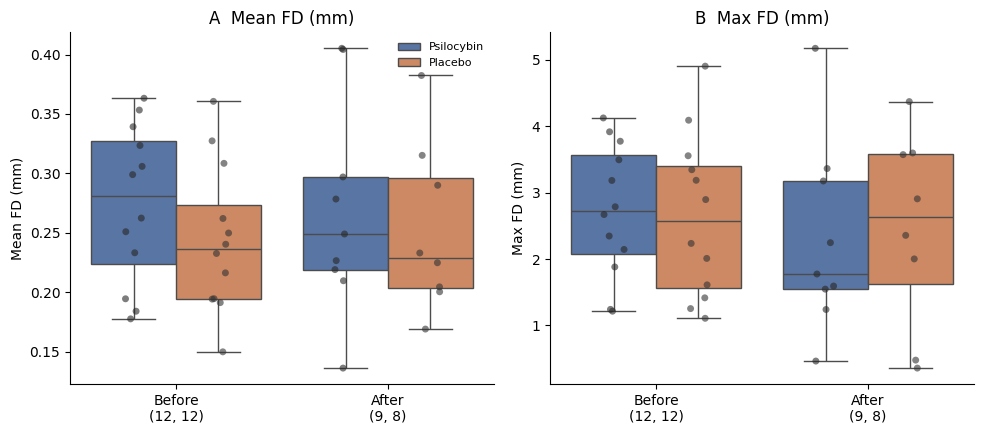

In [59]:
# ── Figure 12: DWI framewise displacement ────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for j, m in enumerate(MET):
    ax = axes[j]
    sns.boxplot(data=dti, x="session", y=m, hue="group", order=SES_ORDER,
                hue_order=GROUP_ORDER, palette=PALETTE, ax=ax, showfliers=False)
    sns.stripplot(data=dti, x="session", y=m, hue="group", order=SES_ORDER,
                  hue_order=GROUP_ORDER, dodge=True, color="0.2", alpha=.6,
                  ax=ax, legend=False)
    n = dti.groupby(["session", "group"]).size()
    ax.set_xticklabels([f"{s}\n({n.get((s, GROUP_ORDER[0]), 0)}, "
                        f"{n.get((s, GROUP_ORDER[1]), 0)})" for s in SES_ORDER])
    ax.set_title(f"{'AB'[j]}  {MET[m]}")
    ax.set_ylabel(MET[m]); ax.set_xlabel("")
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(frameon=False, fontsize=8) if j == 0 else ax.legend_.remove()
fig.tight_layout()
fig.savefig(f"{SAVEFIG}/fig12_dwi_fd.png", dpi=330, bbox_inches="tight")
plt.show()

In [60]:
# Table 5:
rows = []
for ses in SES_ORDER:                                   # between groups
    for m in MET:
        a = dti.query("group=='Psilocybin' and session==@ses")[m]
        b = dti.query("group=='Placebo'    and session==@ses")[m]
        s, p = sts.mannwhitneyu(a, b, alternative='two-sided')
        rows.append({"Comparison": "Psilocybin vs Placebo", "Measure": m,
                     "Context": ses, "N": f"{len(a)} vs {len(b)}",
                     "Mean diff (mm)": round(a.mean() - b.mean(), 4),
                     "Statistic": round(s, 1), "p-value": round(p, 4)})

for grp in GROUP_ORDER:                                 # within group, paired
    for m in MET:
        w = (dti.query("group == @grp")
                .pivot(index='subject', columns='session', values=m).dropna())
        s, p = sts.wilcoxon(w['Before'], w['After'])
        rows.append({"Comparison": f"{grp}: Before vs After", "Measure": m,
                     "Context": "Paired", "N": f"{len(w)} pairs",
                     "Mean diff (mm)": round((w['Before'] - w['After']).mean(), 4),
                     "Statistic": round(s, 1), "p-value": round(p, 4)})

table5 = pd.DataFrame(rows)
_, p_fdr, _, _ = multipletests(table5['p-value'], method='fdr_bh')
table5['p (FDR)'] = np.round(p_fdr, 4)
print(table5.to_string(index=False))
table5.to_csv(f"{SAVEFIG}/table5_dwi_fd.csv", index=False)

                 Comparison Measure Context        N  Mean diff (mm)  Statistic  p-value  p (FDR)
      Psilocybin vs Placebo  meanFD  Before 12 vs 12          0.0299       90.0   0.3123      1.0
      Psilocybin vs Placebo   maxFD  Before 12 vs 12          0.0974       76.0   0.8399      1.0
      Psilocybin vs Placebo  meanFD   After   9 vs 8          0.0171       42.0   0.6058      1.0
      Psilocybin vs Placebo   maxFD   After   9 vs 8         -0.1689       30.0   0.6058      1.0
Psilocybin: Before vs After  meanFD  Paired  9 pairs         -0.0135       22.0   1.0000      1.0
Psilocybin: Before vs After   maxFD  Paired  9 pairs          0.2912       22.0   1.0000      1.0
   Placebo: Before vs After  meanFD  Paired  8 pairs         -0.0023       17.0   0.9453      1.0
   Placebo: Before vs After   maxFD  Paired  8 pairs          0.1029       16.0   0.8438      1.0


#### tSNR

Sessions (paired, n = 24): W = 98.0, p = 0.143
Scanners (Discovery n = 17, Signa n = 7): U = 65.0, p = 0.757

scans total = 48  |  participants = 24
scanner    session
Discovery  01         17
           02         17
Signa      01          7
           02          7
dtype: int64


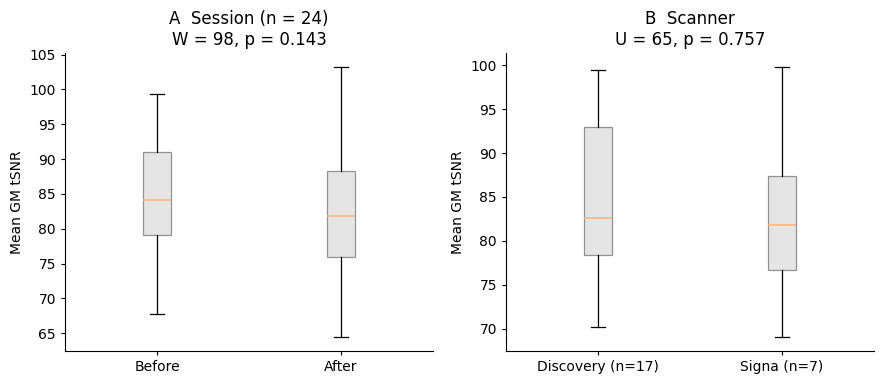

In [61]:
# ── tSNR: sessions and scanners ──────────────────────────────────────────────
jsonpath = JSON_DIR
tspath = TS_DIR

concatenated_subjects = np.concatenate((active_rest_subjects, placebo_rest_subjects))

# --- scanner per subject (flag any subject seen on both) ---------------------
scanner = {}
conflict = set()
for f in os.listdir(tspath):
    s = f.split('_')[0]
    if s not in concatenated_subjects:
        continue
    tag = 'Discovery' if 'discovery' in f else 'Signa' if 'signa' in f else None
    if tag is None:
        continue
    if scanner.setdefault(s, tag) != tag:
        conflict.add(s)
if conflict:
    print(f"WARNING: subjects with files from both scanners: {sorted(conflict)}")

# --- tidy tSNR table --------------------------------------------------------
recs = []
for sub in concatenated_subjects:
    for ses in ['01', '02']:
        jf = os.path.join(jsonpath, f"{sub}_ses-{ses}_task-rest_"
                                    f"feature-corrMatrixICA24Motion_"
                                    f"atlas-SchaeferTian116_timeseries.json")
        if os.path.exists(jf):
            with open(jf) as fh:
                recs.append({'subject': sub, 'session': ses,
                             'tSNR': json.load(fh).get('MeanGMTSNR', np.nan),
                             'scanner': scanner.get(sub, 'unknown')})
tsnr = pd.DataFrame(recs)

missing = set(concatenated_subjects) - set(tsnr['subject'])
if missing:
    print(f"WARNING: no tSNR JSON for {sorted(missing)}")

# --- session comparison: paired -------------------------------------------
wide = tsnr.pivot(index='subject', columns='session', values='tSNR').dropna()
w, p_ses = sts.wilcoxon(wide['01'], wide['02'])
print(f"Sessions (paired, n = {len(wide)}): W = {w:.1f}, p = {p_ses:.3f}")

# --- scanner comparison: one value per participant --------------------------
per_sub = (tsnr.groupby(['subject', 'scanner'], as_index=False)['tSNR'].mean())
disc = per_sub.loc[per_sub.scanner == 'Discovery', 'tSNR']
sig  = per_sub.loc[per_sub.scanner == 'Signa', 'tSNR']
u, p_scan = sts.mannwhitneyu(disc, sig, alternative='two-sided')
print(f"Scanners (Discovery n = {len(disc)}, Signa n = {len(sig)}): "
      f"U = {u:.1f}, p = {p_scan:.3f}")
print(f"\nscans total = {len(tsnr)}  |  participants = {tsnr.subject.nunique()}")
print(tsnr.groupby(['scanner', 'session']).size())

# --- figure ------------------------------------------------------------------
BOX = dict(patch_artist=True, showfliers=False,
           medianprops=dict(linewidth=1.2), whiskerprops=dict(linewidth=0.9),
           capprops=dict(linewidth=0.9),
           boxprops=dict(linewidth=0.9, facecolor='0.8', alpha=0.5, edgecolor='0.2'))

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

axes[0].boxplot([wide['01'], wide['02']], **BOX)
axes[0].set_xticks([1, 2])
axes[0].set_xticklabels(['Before', 'After'])
axes[0].set_title(f"A  Session (n = {len(wide)})\nW = {w:.0f}, p = {p_ses:.3f}")

axes[1].boxplot([disc, sig], **BOX)
axes[1].set_xticks([1, 2])
axes[1].set_xticklabels([f'Discovery (n={len(disc)})', f'Signa (n={len(sig)})'])
axes[1].set_title(f"B  Scanner\nU = {u:.0f}, p = {p_scan:.3f}")

for ax in axes:
    ax.set_ylabel('Mean GM tSNR')
    ax.spines[['top', 'right']].set_visible(False)
    ax.tick_params(direction='out', length=3, width=0.8)
fig.tight_layout()
plt.savefig(f"{SAVEFIG}/fig12_tSNR.png", dpi=330, bbox_inches="tight")